# Home Credit Default Risk Dataset Project

# Part 4 - Models

This is Part 4 of the Home Credit Project for Machine Learning Capstone Project project of Machine Learning module sprint 4.

In this part the models for predicting the target will be tested and deployed.

- Simple baseline model will be created using random forests.
- XBG and LGBM classifiers will be used for modeling due to processing limits.
- Models will be evaluated using ROC AUC score.
- Goal is to reach higher accuracy than set baseline.
- Models will be deployed using docker into Google cloud.

This is the final part of the project.


# Initial Setup

## Import all Packages

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import duckdb as db
import xgboost as xgb
import optuna
import dill
import json
from lightgbm import LGBMClassifier
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, FunctionTransformer, make_pipeline
from sklearn.preprocessing import OneHotEncoder
from scripts import *

pd.set_option('display.max_rows', 300)

pd.options.display.html.border = 0
db.sql("SET enable_progress_bar = False")

## Importing Data

In [2]:
app_train = pd.read_csv('home-credit-default-risk/application_train.csv')
bureau_balance = pd.read_csv('home-credit-default-risk/bureau_balance.csv')
bureau = pd.read_csv('home-credit-default-risk/bureau.csv')
credit_card_balance = pd.read_csv('home-credit-default-risk/credit_card_balance.csv')
installments_payments = pd.read_csv('home-credit-default-risk/installments_payments.csv')
pos_cash = pd.read_csv('home-credit-default-risk/POS_CASH_balance.csv')
previous_application = pd.read_csv('home-credit-default-risk/previous_application.csv')

## Splitting Data Into Training, Validation, and Test Sets

The dataset is divided into training (80%), validation (10%), and test (10%) sets. The validation set will be used for model selection and hyperparameter tuning. The test set will be kept completely separate and used only for the final evaluation of the chosen model to estimate its real-world performance.

In [3]:
X = app_train.drop(['TARGET'], axis=1)
y = app_train['TARGET'].astype(int)

x_train, x_test_val, y_train, y_test_val = train_test_split(
    X, y, test_size=0.2, random_state=8, stratify=app_train['TARGET']
)
x_val, x_test, y_val, y_test = train_test_split(
    x_test_val, y_test_val, test_size=0.5, random_state=8, stratify=y_test_val
)

## Functions for the Pipeline

In [4]:
# Adding a list for removing features from the application preprocess function.
list_to_remove = []

### Application Data

In [5]:
def preprocess_app(data: pd.DataFrame) -> pd.DataFrame:
    '''
    A function made for the preprocessor pipeline for application_train data.
    It needs pandas dataframe as an argument and returns the modified dataframe.
    '''

    df = data.copy()  # To avoid modifying the original DataFrame
    mask = df.DAYS_EMPLOYED == 365243
    df['NAME_INCOME_TYPE'][mask].unique()

    df.loc[mask, 'OCCUPATION_TYPE'] = df.loc[mask, 'OCCUPATION_TYPE'].fillna('Not employed')

    df['OCCUPATION_TYPE'] = df['OCCUPATION_TYPE'].fillna('Unknown')
    df['OWN_CAR_AGE'] = df['OWN_CAR_AGE'].replace(64, np.nan)

    mask = df['AMT_INCOME_TOTAL'] < 2e7, 'AMT_INCOME_TOTAL'
    realistic_median = df.loc[mask].median()
    mask = df['AMT_INCOME_TOTAL'] > 2e7, 'AMT_INCOME_TOTAL'
    df.loc[mask] = realistic_median

    realistic_median_def_30 = df.loc[df['DEF_30_CNT_SOCIAL_CIRCLE'] < 10, 'DEF_30_CNT_SOCIAL_CIRCLE'].median()
    realistic_median_obs_60 = df.loc[df['OBS_60_CNT_SOCIAL_CIRCLE'] < 31, 'OBS_60_CNT_SOCIAL_CIRCLE'].median()
    realistic_median_def_60 = df.loc[df['DEF_60_CNT_SOCIAL_CIRCLE'] < 10, 'DEF_60_CNT_SOCIAL_CIRCLE'].median()
    realistic_median_amt_req = df.loc[df['AMT_REQ_CREDIT_BUREAU_QRT'] < 20, 'OBS_60_CNT_SOCIAL_CIRCLE'].median()
    df.loc[df['DEF_30_CNT_SOCIAL_CIRCLE'] >= 10, 'DEF_30_CNT_SOCIAL_CIRCLE'] = realistic_median_def_30
    df.loc[df['OBS_60_CNT_SOCIAL_CIRCLE'] >= 31, 'OBS_60_CNT_SOCIAL_CIRCLE'] = realistic_median_obs_60
    df.loc[df['DEF_60_CNT_SOCIAL_CIRCLE'] >= 10, 'DEF_60_CNT_SOCIAL_CIRCLE'] = realistic_median_def_60
    df.loc[df['AMT_REQ_CREDIT_BUREAU_QRT'] >= 20, 'AMT_REQ_CREDIT_BUREAU_QRT'] = realistic_median_amt_req

    df['DAYS_LAST_PHONE_CHANGE'] = df['DAYS_LAST_PHONE_CHANGE'].replace(0, np.nan)
    df['PHONE_CHANGE_SUS_FLAG'] = (df['DAYS_LAST_PHONE_CHANGE'].isna()).astype(int)

    for col in ['EXT_SOURCE_1', 'EXT_SOURCE_3']:
        df[f'{col}_MISSING'] = df[col].isnull().astype(int)

    building_other = [
        'FONDKAPREMONT_MODE',
        'HOUSETYPE_MODE',
        'TOTALAREA_MODE',
        'WALLSMATERIAL_MODE',
        'EMERGENCYSTATE_MODE',
    ]

    building_avg = [
        'APARTMENTS_AVG',
        'BASEMENTAREA_AVG',
        'YEARS_BEGINEXPLUATATION_AVG',
        'YEARS_BUILD_AVG',
        'COMMONAREA_AVG',
        'ELEVATORS_AVG',
        'ENTRANCES_AVG',
        'FLOORSMAX_AVG',
        'FLOORSMIN_AVG',
        'LANDAREA_AVG',
        'LIVINGAPARTMENTS_AVG',
        'LIVINGAREA_AVG',
        'NONLIVINGAPARTMENTS_AVG',
        'NONLIVINGAREA_AVG',
    ]

    df['BUILDING_MISSING_COUNT'] = df[building_avg].isna().sum(axis=1)
    df['BUILDING_ANY_MISSING'] = (df['BUILDING_MISSING_COUNT'] >= 1).astype(int)
    df['BUILDING_OTHER_MISSING_COUNT'] = df[building_other].isna().sum(axis=1)
    df['BUILDING_OTHER_ANY_MISSING'] = (df['BUILDING_OTHER_MISSING_COUNT'] >= 1).astype(int)

    # Select all FLAG_DOCUMENT_* columns
    flag_doc_cols = [col for col in df.columns if col.startswith('FLAG_DOCUMENT_')]

    # Create a new column that is 1 if any document flag is 1, else 0
    df['ANY_DOCUMENT_PRESENTED'] = df[flag_doc_cols].any(axis=1).astype(int)
    df['DOCUMENTS_COUNT'] = df[flag_doc_cols].sum(axis=1)

    df['ANNUITY_INCOME_RATIO'] = df['AMT_ANNUITY'] / df['AMT_INCOME_TOTAL']
    df['ANNUITY_CREDIT_RATIO'] = df['AMT_ANNUITY'] / df['AMT_CREDIT']
    df['GOODS_CREDIT_RATIO'] = df['AMT_GOODS_PRICE'] / df['AMT_CREDIT']

    df['DAYS_EMPLOYED'] = df['DAYS_EMPLOYED'].replace(365243, np.nan)
    df['AGE_YEARS'] = (-df['DAYS_BIRTH']) // 365
    df['YEARS_EMPLOYED'] = df['DAYS_EMPLOYED'].apply(lambda x: x if x < 0 else np.nan) / -365
    df['RECENT_PHONE_CHANGE'] = (df['DAYS_LAST_PHONE_CHANGE'] > -365).astype(int)

    columns_to_drop = [
        'FLAG_MOBIL',
        'FLAG_DOCUMENT_2',
        'FLAG_DOCUMENT_4',
        'FLAG_DOCUMENT_7',
        'FLAG_DOCUMENT_10',
        'FLAG_DOCUMENT_12',
        'FLAG_DOCUMENT_21',
    ]
    df = df.drop(columns_to_drop, axis=1)

    df['FLAG_OWN_CAR'] = df['FLAG_OWN_CAR'].map({'Y': 1, 'N': 0})
    df['FLAG_OWN_REALTY'] = df['FLAG_OWN_REALTY'].map({'Y': 1, 'N': 0})

    df['ORGANIZATION_TYPE_TRADE'] = df['ORGANIZATION_TYPE'].str.contains('Trade', case=False).astype(int)
    df['ORGANIZATION_TYPE_INDUSTRY'] = df['ORGANIZATION_TYPE'].str.contains('Industry', case=False).astype(int)
    df['ORGANIZATION_TYPE_TRANSPORT'] = df['ORGANIZATION_TYPE'].str.contains('Transport', case=False).astype(int)

    df['ORGANIZATION_TYPE_BUSINESS_ENTITY'] = (
        df['ORGANIZATION_TYPE'].str.contains('Business Entity Type', case=False).astype(int)
    )
    df['ORGANIZATION_TYPE_GOVERNMENT'] = (
        df['ORGANIZATION_TYPE']
        .isin(['Government', 'Military', 'Police', 'Emergency', 'Security Ministries', 'Postal'])
        .astype(int)
    )
    df['ORGANIZATION_TYPE_EDUCATION'] = (
        df['ORGANIZATION_TYPE'].isin(['School', 'University', 'Kindergarten']).astype(int)
    )
    df['ORGANIZATION_TYPE_INFRASTRUCTURE'] = (
        df['ORGANIZATION_TYPE'].isin(['Construction', 'Housing', 'Electricity']).astype(int)
    )
    df['ORGANIZATION_TYPE_SERVICES'] = (
        df['ORGANIZATION_TYPE']
        .isin(['Self-employed', 'Services', 'Cleaning', 'Legal Services', 'Realtor', 'Security', 'Religion'])
        .astype(int)
    )
    df['ORGANIZATION_TYPE_FINANCE'] = df['ORGANIZATION_TYPE'].isin(['Bank', 'Insurance']).astype(int)
    df['ORGANIZATION_TYPE_TECH'] = df['ORGANIZATION_TYPE'].isin(['Telecom', 'Mobile', 'Advertising']).astype(int)
    df['ORGANIZATION_TYPE_HOSPITALITY'] = df['ORGANIZATION_TYPE'].isin(['Restaurant', 'Hotel', 'Culture']).astype(int)

    df['NAME_TYPE_SUITE_OTHER'] = df['NAME_TYPE_SUITE'].isin(['Other_A', 'Other_B', 'Group of people']).astype(int)

    df['NAME_EDUCATION_TYPE_SECONDARY'] = (
        df['NAME_EDUCATION_TYPE'].isin(['Secondary / secondary special', 'Lower secondary']).astype(int)
    )

    df['WALLSMATERIAL_MODE_UNCOMMON'] = (
        df['WALLSMATERIAL_MODE'].isin(['Block', 'Mixed', 'Wooden', 'Others', 'Monolithic']).astype(int)
    )

    occupation_map = {
        'Laborers': 'Manual',
        'Low-skill Laborers': 'Manual',
        'Drivers': 'Manual',
        'Cleaning staff': 'Manual',
        'Cooking staff': 'Manual',
        'Security staff': 'Manual',
        'Core staff': 'Office',
        'Secretaries': 'Office',
        'HR staff': 'Office',
        'Accountants': 'Professional',
        'Managers': 'Professional',
        'IT staff': 'Professional',
        'High skill tech staff': 'Professional',
        'Medicine staff': 'Professional',
        'Sales staff': 'Service',
        'Waiters/barmen staff': 'Service',
        'Private service staff': 'Service',
        'Realty agents': 'Service',
        'Not employed': 'Unemployed',
        'Unknown': 'Unemployed',
    }

    df['OCCUPATION_TYPE_GROUPED'] = df['OCCUPATION_TYPE'].map(occupation_map)

    x_num = df.select_dtypes(exclude='object').reset_index(drop=True)
    x_cat = df.select_dtypes(include='object')

    encoder = OneHotEncoder(sparse_output=False)
    x_encoded = encoder.fit_transform(x_cat)

    # create the names for the one-hot encoded categorical features
    categorical_columns = [f'{col}_{cat}' for i, col in enumerate(x_cat.columns) for cat in encoder.categories_[i]]

    # put the features into a dataframe and join with the original
    # numerical features

    one_hot_features = pd.DataFrame(x_encoded, columns=categorical_columns)

    # Dropping missing, high some of rare categories and ones which had high p value in
    # hypothesis testing
    high_corr = [
        'NAME_CONTRACT_TYPE_Revolving loans',
        'DAYS_BIRTH',
        'DAYS_EMPLOYED',
        'FLAG_EMP_PHONE',
        'CODE_GENDER_F',
        'NAME_INCOME_TYPE_Pensioner',
        'OBS_30_CNT_SOCIAL_CIRCLE',
    ]
    no_corr = [
        'FLAG_DOCUMENT_20',
        'FLAG_DOCUMENT_5',
        'FLAG_CONT_MOBILE',
        'OCCUPATION_TYPE_Realty agents',
        'ORGANIZATION_TYPE_Advertising',
        'ORGANIZATION_TYPE_Business Entity Type 1',
        'ORGANIZATION_TYPE_Industry: type 6',
        'ORGANIZATION_TYPE_Industry: type 7',
        'ORGANIZATION_TYPE_Telecom',
        'ORGANIZATION_TYPE_Transport: type 2',
        'ORGANIZATION_TYPE_Trade: type 5',
        'ORGANIZATION_TYPE_Housing',
        'ORGANIZATION_TYPE_Legal Services',
    ]
    drop_high_p = [
        'AMT_ANNUITY',
        'FLAG_EMAIL',
        'LIVE_REGION_NOT_WORK_REGION',
        'NONLIVINGAPARTMENTS_MODE',
        'NONLIVINGAPARTMENTS_MEDI',
        'FLAG_DOCUMENT_19',
        'AMT_REQ_CREDIT_BUREAU_HOUR',
        'AMT_REQ_CREDIT_BUREAU_WEEK',
        'NAME_TYPE_SUITE_Children',
        'NAME_TYPE_SUITE_Spouse, partner',
        'NAME_EDUCATION_TYPE_Incomplete higher',
        'NAME_FAMILY_STATUS_Separated',
        'OCCUPATION_TYPE_HR staff',
        'OCCUPATION_TYPE_IT staff',
        'OCCUPATION_TYPE_Secretaries',
        'WEEKDAY_APPR_PROCESS_START_FRIDAY',
        'WEEKDAY_APPR_PROCESS_START_SATURDAY',
        'WEEKDAY_APPR_PROCESS_START_SUNDAY',
        'WEEKDAY_APPR_PROCESS_START_THURSDAY',
        'WEEKDAY_APPR_PROCESS_START_WEDNESDAY',
        'ORGANIZATION_TYPE_Electricity',
        'ORGANIZATION_TYPE_Emergency',
        'ORGANIZATION_TYPE_Industry: type 10',
        'ORGANIZATION_TYPE_Industry: type 11',
        'ORGANIZATION_TYPE_Industry: type 13',
        'ORGANIZATION_TYPE_Industry: type 2',
        'ORGANIZATION_TYPE_Industry: type 5',
        'ORGANIZATION_TYPE_Industry: type 8',
        'ORGANIZATION_TYPE_Mobile',
        'ORGANIZATION_TYPE_Postal',
        'ORGANIZATION_TYPE_Religion',
        'ORGANIZATION_TYPE_Trade: type 1',
        'ORGANIZATION_TYPE_Trade: type 4',
        'HOUSETYPE_MODE_terraced house',
        'WALLSMATERIAL_MODE_Mixed',
        'WALLSMATERIAL_MODE_Others',
    ]

    col_to_drop = [
        'EMERGENCYSTATE_MODE_nan',
        'CODE_GENDER_XNA',
        'FONDKAPREMONT_MODE_nan',
        'HOUSETYPE_MODE_nan',
        'WALLSMATERIAL_MODE_nan',
        'ORGANIZATION_TYPE_XNA',
        'NAME_TYPE_SUITE_nan',
        'NAME_TYPE_SUITE_Group of people',
        'NAME_TYPE_SUITE_Other_A',
        'NAME_INCOME_TYPE_Businessman',
        'NAME_INCOME_TYPE_Maternity leave',
        'NAME_INCOME_TYPE_Student',
        'NAME_INCOME_TYPE_Unemployed',
        'NAME_FAMILY_STATUS_Unknown',
        'NAME_HOUSING_TYPE_Co-op apartment',
        'OCCUPATION_TYPE_Unknown',
        'FONDKAPREMONT_MODE_not specified',
        'WALLSMATERIAL_MODE_Monolithic',
    ]
    col_to_drop.extend(high_corr)
    col_to_drop.extend(drop_high_p)
    col_to_drop.extend(no_corr)
    col_to_drop.extend(list_to_remove)
    one_hot_features
    df = x_num.join(one_hot_features)
    df = df.drop(columns=col_to_drop, errors='ignore')

    return df

### Suplementary Data

#### Bureau

In [6]:
def preprocess_bureau_feat(bur: pd.DataFrame, bur_balance: pd.DataFrame) -> pd.DataFrame:
    """
    A function made for the preprocessor pipeline for bureau and bureau balance
    data.
    It needs pandas dataframe as an argument and returns the modified dataframe.
    """
    bureau = bur.copy()
    bureau_balance = bur_balance.copy()

    bureau['CREDIT_ENDDATE_MISSING_FLAG'] = bureau['DAYS_CREDIT_ENDDATE'].isnull().astype(int)
    bureau['AMT_CREDIT_MAX_OVERDUE_MISSING_FLAG'] = bureau['AMT_CREDIT_MAX_OVERDUE'].isnull().astype(int)
    bureau['HAS_ANNUITY_INFO'] = bureau['AMT_ANNUITY'].notnull().astype(int)

    def simplify_credit_type(x: str) -> str:
        """
        Helper function to simplify credit type into broader categories.
        Keeps 'Consumer credit', 'Credit card', 'Car loan', and 'Mortgage' as-is.

        Parameters: x (str): original credit type.
        Returns: str: Simplified credit type.
        """
        if x in ['Consumer credit', 'Credit card', 'Car loan', 'Mortgage']:
            return x
        else:
            return 'Other'

    def simplify_credit_active(x: str) -> str:
        """
        Helper function to simplify credit active into broader categories.
        Keeps 'Closed' and 'Active' as-is.

        Parameters: x (str): original credit type.
        Returns: str: Simplified credit category.
        """
        if x in ['Closed', 'Active']:
            return x
        else:
            return 'Other'

    bureau['CREDIT_TYPE_GROUPED'] = bureau['CREDIT_TYPE'].apply(simplify_credit_type)
    bureau['CREDIT_ACTIVE_GROUPED'] = bureau['CREDIT_ACTIVE'].apply(simplify_credit_active)
    bureau['CREDIT_CURRENCY_GROUPED'] = bureau['CREDIT_CURRENCY'].apply(
        lambda x: 'currency 1' if x == 'currency 1' else 'other currency'
    )
    bureau['WAS_CREDIT_PROLONGED'] = (bureau['CNT_CREDIT_PROLONG'] != 0).astype(int)

    bureau['CREDIT_LENGTH'] = bureau['DAYS_ENDDATE_FACT'] - bureau['DAYS_CREDIT']
    bureau['DEBT_CREDIT_RATIO'] = bureau.apply(
        lambda row: row['AMT_CREDIT_SUM_DEBT'] / row['AMT_CREDIT_SUM'] if row['AMT_CREDIT_SUM'] != 0 else np.nan, axis=1
    )
    bureau['OVERDUE_TO_DEBT_RATIO'] = bureau.apply(
        lambda row: (
            row['AMT_CREDIT_SUM_OVERDUE'] / row['AMT_CREDIT_SUM_DEBT'] if row['AMT_CREDIT_SUM_DEBT'] != 0 else np.nan
        ),
        axis=1,
    )
    bureau['HAS_OVERDUE'] = (bureau['AMT_CREDIT_SUM_OVERDUE'] > 0).astype(int)
    bureau['CREDIT_ACTIVE_FLAG'] = bureau['CREDIT_ACTIVE'].isin(['Active']).astype(int)

    bureau['OVERDUE_WITH_NO_DEBT_FLAG'] = (
        (bureau['AMT_CREDIT_SUM_DEBT'] == 0) & (bureau['AMT_CREDIT_SUM_OVERDUE'] > 0)
    ).astype(int)

    mask = bureau['CREDIT_LENGTH'] < 0
    bureau.loc[mask, 'CREDIT_LENGTH'] = np.nan

    query = """
        SELECT 
            SK_ID_BUREAU,
            AVG(MONTHS_BALANCE) MONTHS_BALANCE,
            CASE 
                WHEN COUNT_IF(STATUS IN ('0','1','2','3','4','5')) > 0 
                    THEN MAX(CASE WHEN STATUS IN ('0','1','2','3','4','5') 
                    THEN STATUS ELSE NULL END)
                WHEN COUNT_IF(STATUS = 'C') > 0 
                    THEN 'C'
                ELSE 'X'
            END AS STATUS
        FROM bureau_balance
        GROUP BY SK_ID_BUREAU;    
    """

    bb_agg = db.sql(query).df()
    query = '''
    SELECT *
    FROM bureau b
    LEFT JOIN bb_agg bb
    ON b.SK_ID_BUREAU = bb.SK_ID_BUREAU
    '''

    bureau_all = db.sql(query).df().drop(['SK_ID_BUREAU_1'], axis=1)

    aggregations = {
        'DAYS_CREDIT': ['mean'],
        'CREDIT_DAY_OVERDUE': ['mean'],
        'DAYS_CREDIT_ENDDATE': ['mean'],
        'DAYS_ENDDATE_FACT': ['min', 'mean'],
        'AMT_CREDIT_MAX_OVERDUE': ['mean'],
        'CNT_CREDIT_PROLONG': ['mean'],
        'AMT_CREDIT_SUM': ['mean'],
        'AMT_CREDIT_SUM_DEBT': ['mean'],
        'AMT_CREDIT_SUM_LIMIT': ['mean'],
        'AMT_CREDIT_SUM_OVERDUE': ['mean'],
        'DAYS_CREDIT_UPDATE': ['mean'],
        'AMT_ANNUITY': ['mean'],
        'CREDIT_ENDDATE_MISSING_FLAG': ['max'],
        'AMT_CREDIT_MAX_OVERDUE_MISSING_FLAG': ['max'],
        'HAS_ANNUITY_INFO': ['max'],
        'WAS_CREDIT_PROLONGED': ['max'],
        'CREDIT_LENGTH': ['mean', 'max'],
        'DEBT_CREDIT_RATIO': ['mean'],
        'OVERDUE_TO_DEBT_RATIO': ['mean'],
        'HAS_OVERDUE': ['max'],
        'CREDIT_ACTIVE_FLAG': ['max'],
        'OVERDUE_WITH_NO_DEBT_FLAG': ['max'],
        'MONTHS_BALANCE': ['mean'],
    }

    bureau_agg = bureau_all.groupby('SK_ID_CURR').agg(aggregations)
    bureau_agg.columns = ['BUR_' + '_'.join(col).upper() for col in bureau_agg.columns]
    bureau_agg.reset_index(inplace=True)

    query = '''
    with t1 as (
        SELECT 
            SK_ID_CURR,
            COUNT(DISTINCT SK_ID_BUREAU) AS NUM_BUREAU,
            CASE WHEN COUNT(DISTINCT SK_ID_BUREAU) > 0 THEN 1 ELSE 0 END AS HAS_BUREAU,
           
            SUM(CASE WHEN CREDIT_ACTIVE_GROUPED = 'Active' THEN 1 ELSE 0 END) AS CREDIT_ACTIVE_ACTIVE,
            SUM(CASE WHEN CREDIT_ACTIVE_GROUPED = 'Closed' THEN 1 ELSE 0 END) AS CREDIT_ACTIVE_CLOSED,
            SUM(CASE WHEN CREDIT_ACTIVE_GROUPED = 'Other' THEN 1 ELSE 0 END) AS CREDIT_ACTIVE_OTHER,
    
            SUM(CASE WHEN CREDIT_TYPE_GROUPED = 'Credit card' THEN 1 ELSE 0 END) AS CREDIT_TYPE_CREDIT_CARD,
            SUM(CASE WHEN CREDIT_TYPE_GROUPED = 'Consumer credit' THEN 1 ELSE 0 END) AS CREDIT_TYPE_CONSUMER_CREDIT,
            SUM(CASE WHEN CREDIT_TYPE_GROUPED = 'Mortgage' THEN 1 ELSE 0 END) AS CREDIT_TYPE_MORTGAGE,
            SUM(CASE WHEN CREDIT_TYPE_GROUPED = 'Car loan' THEN 1 ELSE 0 END) AS CREDIT_TYPE_CAR_LOAN,
            SUM(CASE WHEN CREDIT_TYPE_GROUPED = 'Other' THEN 1 ELSE 0 END) AS CREDIT_TYPE_OTHER,
            
            COUNT(DISTINCT CREDIT_CURRENCY) AS NUM_DISTINCT_CURRENCIES,
            SUM(CASE WHEN CREDIT_CURRENCY = 'currency 2' THEN 1 ELSE 0 END) AS NUM_CURRENCY_2,
            SUM(CASE WHEN CREDIT_CURRENCY = 'currency 3' THEN 1 ELSE 0 END) AS NUM_CURRENCY_3,
            SUM(CASE WHEN CREDIT_CURRENCY_GROUPED = 'other currency' THEN 1 ELSE 0 END) AS NUM_CURRENCY_OTHER,
            CASE 
                WHEN COUNT_IF(STATUS IN ('0','1','2','3','4','5')) > 0 
                    THEN MAX(CASE WHEN STATUS IN ('0','1','2','3','4','5') 
                    THEN STATUS ELSE NULL END)
                WHEN COUNT_IF(STATUS = 'C') > 0 
                    THEN 'C'
                ELSE 'X'
            END AS STATUS,
            CASE 
                WHEN COUNT(*) FILTER (WHERE STATUS IN ('1','2','3','4','5')) > 0 
                    THEN 1
                ELSE 0
            END AS STATUS_FLAG
        FROM bureau_all
        GROUP BY SK_ID_CURR
        )
        
    SELECT *
    FROM bureau_agg b
    LEFT JOIN t1
    ON b.SK_ID_CURR = t1.SK_ID_CURR
    '''

    bureau_agg = db.sql(query).df().drop(['SK_ID_CURR_1'], axis=1)

    x_num = bureau_agg.select_dtypes(exclude='object').reset_index(drop=True)
    x_cat = bureau_agg.select_dtypes(include='object')

    encoder = OneHotEncoder(sparse_output=False)
    x_encoded = encoder.fit_transform(x_cat)

    # create the names for the one-hot encoded categorical features
    categorical_columns = [f'{col}_{cat}' for i, col in enumerate(x_cat.columns) for cat in encoder.categories_[i]]

    # put the features into a dataframe and join with the original
    # numerical features

    one_hot_features = pd.DataFrame(x_encoded, columns=categorical_columns)

    # Dropping missing and some of rare categories
    one_hot_features = one_hot_features.drop(
        [
            'STATUS_X',
            'STATUS_3',
            'STATUS_4',
            'STATUS_C',
        ],
        axis=1,
    )

    bureau_agg = x_num.join(one_hot_features)

    mask = bureau_agg['BUR_AMT_CREDIT_MAX_OVERDUE_MEAN'] < 2e7
    realistic_median = bureau_agg.loc[mask, 'BUR_AMT_CREDIT_MAX_OVERDUE_MEAN'].median()

    # Replace suspiciously value with the realistic median
    mask = bureau_agg['BUR_AMT_CREDIT_MAX_OVERDUE_MEAN'] > 2e7
    bureau_agg.loc[mask, 'BUR_AMT_CREDIT_MAX_OVERDUE_MEAN'] = realistic_median
    bureau_agg['BUR_AMT_CREDIT_MAX_OVERDUE_MEAN'] = bureau_agg['BUR_AMT_CREDIT_MAX_OVERDUE_MEAN'].fillna(0)

    mask = bureau_agg['BUR_AMT_CREDIT_SUM_MEAN'] < 5e7
    realistic_median = bureau_agg.loc[mask, 'BUR_AMT_CREDIT_SUM_MEAN'].median()

    # Replace suspiciously value with the realistic median
    mask = bureau_agg['BUR_AMT_CREDIT_SUM_MEAN'] > 5e7
    bureau_agg.loc[mask, 'BUR_AMT_CREDIT_SUM_MEAN'] = realistic_median

    return bureau_agg

#### Credit Card Balance

In [7]:
def preprocess_credit_card_balance(cc_balance: pd.DataFrame) -> pd.DataFrame:
    '''
    A function made for the preprocessor pipeline for credit card balance data.
    It needs pandas dataframe as an argument and returns the modified dataframe.
    '''
    credit_card_balance = cc_balance.copy()
    credit_card_balance['HAD_DPD'] = credit_card_balance['SK_DPD'].apply(lambda x: 1 if x > 0 else 0)
    credit_card_balance['HAD_DPD_DEF'] = credit_card_balance['SK_DPD_DEF'].apply(lambda x: 1 if x > 0 else 0)

    aggregations = {
        'MONTHS_BALANCE': ['mean'],
        'AMT_BALANCE': ['mean'],
        'AMT_DRAWINGS_ATM_CURRENT': ['mean'],
        'AMT_DRAWINGS_CURRENT': ['mean'],
        'AMT_DRAWINGS_POS_CURRENT': ['mean'],
        'AMT_PAYMENT_CURRENT': ['mean'],
        'AMT_PAYMENT_TOTAL_CURRENT': ['mean'],
        'CNT_DRAWINGS_ATM_CURRENT': ['mean'],
        'CNT_DRAWINGS_CURRENT': ['mean'],
        'CNT_DRAWINGS_POS_CURRENT': ['mean'],
        'CNT_INSTALMENT_MATURE_CUM': ['mean'],
        'SK_DPD_DEF': ['mean'],
        'HAD_DPD': ['max'],
        'HAD_DPD_DEF': ['max'],
    }

    cc_bal_agg = credit_card_balance.groupby('SK_ID_CURR').agg(aggregations)
    cc_bal_agg.columns = ['CC_' + '_'.join(col).upper() for col in cc_bal_agg.columns]
    cc_bal_agg.reset_index(inplace=True)

    query = """
    with t1 as (
        SELECT 
            SK_ID_CURR,
            COUNT(DISTINCT SK_ID_PREV) AS NUM_CREDIT_CARD,
        FROM credit_card_balance
        GROUP BY SK_ID_CURR
        ), 
    
        t2 as (
        SELECT 
        SK_ID_CURR,
        COUNT(DISTINCT CASE WHEN has_completed = 1 THEN SK_ID_PREV ELSE NULL END) AS CC_COMPLETED
        FROM (
            SELECT 
                SK_ID_CURR,
                SK_ID_PREV,
                MAX(CASE WHEN NAME_CONTRACT_STATUS = 'Active' THEN 1 ELSE 0 END) AS has_active,
                MAX(CASE WHEN NAME_CONTRACT_STATUS = 'Completed' THEN 1 ELSE 0 END) AS has_completed,
            FROM credit_card_balance
            GROUP BY SK_ID_CURR, SK_ID_PREV
        ) AS loan_flags
        GROUP BY SK_ID_CURR
        )
    
    SELECT *
    FROM cc_bal_agg cc
    JOIN t1
    ON cc.SK_ID_CURR = t1.SK_ID_CURR
    LEFT JOIN t2
    ON cc.SK_ID_CURR = t2.SK_ID_CURR;
    """

    cc_bal_agg = db.sql(query).df().drop(['SK_ID_CURR_1', 'SK_ID_CURR_2'], axis=1)
    return cc_bal_agg

#### Installments Payments

In [8]:
def preprocess_installments_payments(inst_payments: pd.DataFrame) -> pd.DataFrame:
    '''
    A function made for the preprocessor pipeline for installment payments data.
    It needs pandas dataframe as an argument and returns the modified dataframe.
    '''

    installments_payments = inst_payments.copy()
    installments_payments['DAYS_INST_PAY_DIFF'] = (
        installments_payments['DAYS_INSTALMENT'] - installments_payments['DAYS_ENTRY_PAYMENT']
    )
    installments_payments['AMT_INST_PAY_DIFF'] = (
        installments_payments['AMT_INSTALMENT'] - installments_payments['AMT_PAYMENT']
    )
    installments_payments['AMT_INST_PAY_RATIO'] = installments_payments.apply(
        lambda row: row['AMT_INSTALMENT'] / row['AMT_PAYMENT'] if row['AMT_PAYMENT'] != 0 else np.nan, axis=1
    )
    installments_payments['AMT_INST_PAY_RATIO'] = installments_payments['AMT_INST_PAY_RATIO'].clip(upper=10)

    aggregations = {
        'NUM_INSTALMENT_VERSION': ['mean'],
        'NUM_INSTALMENT_NUMBER': ['max', 'mean'],
        'DAYS_ENTRY_PAYMENT': ['mean'],
        'DAYS_INST_PAY_DIFF': ['mean', 'min'],
        'AMT_PAYMENT': ['mean'],
        'AMT_INST_PAY_DIFF': ['mean', 'max'],
        'AMT_INST_PAY_RATIO': ['mean'],
    }

    inst_pay_agg = installments_payments.groupby('SK_ID_CURR').agg(aggregations)
    inst_pay_agg.columns = ['IP_' + '_'.join(col).upper() for col in inst_pay_agg.columns]
    inst_pay_agg.reset_index(inplace=True)

    query = '''
    with t1 as (
        SELECT 
            SK_ID_CURR,
            COUNT(DISTINCT SK_ID_PREV) AS NUM_INSTALMENT_PAYMENTS,
            CASE WHEN COUNT(DISTINCT SK_ID_PREV) > 0 THEN 1 ELSE 0 END AS HAD_INSTALMENT_PAYMENTS
        FROM installments_payments
        GROUP BY SK_ID_CURR
        ) 
    
    SELECT *
    FROM inst_pay_agg ip
    JOIN t1
    ON ip.SK_ID_CURR = t1.SK_ID_CURR;
    '''

    inst_pay_agg = db.sql(query).df().drop(['SK_ID_CURR_1'], axis=1)
    return inst_pay_agg

#### POS Cash

In [9]:
def preprocess_pos_cash(p_cash: pd.DataFrame) -> pd.DataFrame:
    '''
    A function made for the preprocessor pipeline for POS cash data.
    It needs pandas dataframe as an argument and returns the modified dataframe.
    '''
    pos_cash = p_cash.copy()
    pos_cash['HAD_DPD'] = pos_cash['SK_DPD'].apply(lambda x: 1 if x > 0 else 0)
    pos_cash['HAD_DPD_DEF'] = pos_cash['SK_DPD_DEF'].apply(lambda x: 1 if x > 0 else 0)

    aggregations = {
        'MONTHS_BALANCE': ['min', 'mean'],
        'CNT_INSTALMENT': ['mean', 'max'],
        'CNT_INSTALMENT_FUTURE': ['mean', 'sum'],
        'SK_DPD': ['mean'],
        'SK_DPD_DEF': ['mean'],
        'HAD_DPD': ['max'],
        'HAD_DPD_DEF': ['max'],
    }

    pos_agg = pos_cash.groupby('SK_ID_CURR').agg(aggregations)
    pos_agg.columns = ['POS_' + '_'.join(col).upper() for col in pos_agg.columns]
    pos_agg.reset_index(inplace=True)

    query = """
    with t1 as (
        SELECT 
            SK_ID_CURR,
            CASE WHEN COUNT(DISTINCT SK_ID_PREV) > 0 THEN 1 ELSE 0 END AS HAS_PREVIOUS_POS
        FROM pos_cash
        GROUP BY SK_ID_CURR
        ), 
    
        t2 as (
        SELECT 
        SK_ID_CURR,
        COUNT(DISTINCT CASE WHEN has_active = 1 THEN SK_ID_PREV ELSE NULL END) AS POS_ACTIVE_LOANS
        FROM (
            SELECT 
                SK_ID_CURR,
                SK_ID_PREV,
                MAX(CASE WHEN NAME_CONTRACT_STATUS = 'Active' THEN 1 ELSE 0 END) AS has_active,
            FROM pos_cash
            GROUP BY SK_ID_CURR, SK_ID_PREV
        ) AS loan_flags
        GROUP BY SK_ID_CURR
        )
    
    SELECT *
    FROM pos_agg pa
    JOIN t1
    ON pa.SK_ID_CURR = t1.SK_ID_CURR
    LEFT JOIN t2
    ON pa.SK_ID_CURR = t2.SK_ID_CURR;
    """

    pos_agg = db.sql(query).df().drop(['SK_ID_CURR_1', 'SK_ID_CURR_2'], axis=1)
    return pos_agg

#### Previous Application

In [10]:
def preprocess_previous_application(p_application: pd.DataFrame) -> pd.DataFrame:
    '''
    A function made for the preprocessor pipeline for previous application data.
    It needs pandas dataframe as an argument and returns the modified dataframe.
    '''

    previous_application = p_application.copy()
    previous_application['NAME_TYPE_SUITE'] = previous_application['NAME_TYPE_SUITE'].fillna('Unknown')
    previous_application['FLAG_LAST_APPL_PER_CONTRACT'] = previous_application['FLAG_LAST_APPL_PER_CONTRACT'].map(
        {'Y': 1, 'N': 0}
    )

    previous_application['DAYS_FIRST_DRAWING'] = previous_application['DAYS_FIRST_DRAWING'].replace(365243, np.nan)
    previous_application['DAYS_FIRST_DUE'] = previous_application['DAYS_FIRST_DUE'].replace(365243, np.nan)
    previous_application['DAYS_LAST_DUE_1ST_VERSION'] = previous_application['DAYS_LAST_DUE_1ST_VERSION'].replace(
        365243, np.nan
    )
    previous_application['DAYS_LAST_DUE'] = previous_application['DAYS_LAST_DUE'].replace(365243, np.nan)
    previous_application['DAYS_TERMINATION'] = previous_application['DAYS_TERMINATION'].replace(365243, np.nan)

    aggregations = {
        'AMT_ANNUITY': ['mean'],
        'AMT_APPLICATION': ['mean', 'max'],
        'AMT_CREDIT': ['mean'],
        'AMT_DOWN_PAYMENT': ['min', 'mean'],
        'AMT_GOODS_PRICE': ['mean'],
        'HOUR_APPR_PROCESS_START': ['mean'],
        'RATE_DOWN_PAYMENT': ['mean'],
        'RATE_INTEREST_PRIVILEGED': ['mean'],
        'DAYS_DECISION': ['mean'],
        'SELLERPLACE_AREA': ['mean'],
        'DAYS_FIRST_DRAWING': ['mean'],
        'DAYS_FIRST_DUE': ['mean'],
        'DAYS_TERMINATION': ['mean'],
        'FLAG_LAST_APPL_PER_CONTRACT': ['min'],
        'NFLAG_LAST_APPL_IN_DAY': ['min'],
        'NFLAG_INSURED_ON_APPROVAL': ['mean', 'max'],
    }

    prev_app_agg = previous_application.groupby('SK_ID_CURR').agg(aggregations)
    prev_app_agg.columns = ['PREV_' + '_'.join(col).upper() for col in prev_app_agg.columns]
    prev_app_agg.reset_index(inplace=True)

    query = """
    with t1 as (
        SELECT 
            SK_ID_CURR,
            COUNT(DISTINCT SK_ID_PREV) AS NUM_PREV_APPLICATIONS,
            CASE WHEN COUNT(DISTINCT SK_ID_PREV) > 0 THEN 1 ELSE 0 END AS HAS_PREV_APPLICATION,
            SUM(CASE WHEN NAME_CONTRACT_TYPE = 'Cash loans' THEN 1 ELSE 0 END) AS CASH_LOAN,
            SUM(CASE WHEN NAME_CONTRACT_TYPE = 'Consumer loans' THEN 1 ELSE 0 END) AS CONSUMER_LOAN,
            SUM(CASE WHEN NAME_CONTRACT_TYPE = 'Revolving loans' THEN 1 ELSE 0 END) AS REVOLVING_LOAN,
            SUM(CASE WHEN NAME_CONTRACT_STATUS = 'Approved' THEN 1 ELSE 0 END) AS CONTRACT_APPROVED,
            SUM(CASE WHEN NAME_PAYMENT_TYPE = 'Cash through the bank' THEN 1 ELSE 0 END) AS PAY_TYPE_BANK,
            SUM(CASE WHEN NAME_PORTFOLIO = 'POS' THEN 1 ELSE 0 END) AS PORTFOLIO_POS,
            SUM(CASE WHEN NAME_PORTFOLIO = 'Cash' THEN 1 ELSE 0 END) AS PORTFOLIO_CASH,
            SUM(CASE WHEN NAME_PORTFOLIO = 'Cards' THEN 1 ELSE 0 END) AS PORTFOLIO_CARDS,
            SUM(CASE WHEN NAME_PORTFOLIO = 'Cars' THEN 1 ELSE 0 END) AS PORTFOLIO_CARS,
            SUM(CASE WHEN NAME_PRODUCT_TYPE = 'x-sell' THEN 1 ELSE 0 END) AS PRODUCT_XSELL,
            SUM(CASE WHEN NAME_PRODUCT_TYPE = 'walk-in' THEN 1 ELSE 0 END) AS PRODUCT_WALKIN,
            SUM(CASE WHEN NAME_YIELD_GROUP = 'low_action' THEN 1 ELSE 0 END) AS YIELD_LOW_ACTION,
            SUM(CASE WHEN NAME_YIELD_GROUP = 'low_normal' THEN 1 ELSE 0 END) AS YIELD_LOW_NORMAL,
            SUM(CASE WHEN NAME_YIELD_GROUP = 'middle' THEN 1 ELSE 0 END) AS YIELD_MIDDLE,
            SUM(CASE WHEN NAME_YIELD_GROUP = 'high' THEN 1 ELSE 0 END) AS YIELD_HIGH,
            SUM(CASE WHEN NAME_CASH_LOAN_PURPOSE NOT IN ('XAP', 'XNA') THEN 1 ELSE 0 END) AS CASH_LOAN_PURPOSE_OTHER,
            SUM(CASE WHEN CODE_REJECT_REASON = 'XAP' THEN 1 ELSE 0 END) AS CODE_REJECT_REASON_XAP,
            SUM(CASE WHEN CODE_REJECT_REASON NOT IN ('XAP', 'XNA') THEN 1 ELSE 0 END) AS CODE_REJECT_REASON_OTHER,
            SUM(CASE WHEN NAME_TYPE_SUITE = 'Unknown' THEN 1 ELSE 0 END) AS TYPE_SUITE_UNKNOWN,
            SUM(CASE WHEN NAME_TYPE_SUITE = 'Family' THEN 1 ELSE 0 END) AS TYPE_SUITE_FAMILY,
            SUM(CASE WHEN NAME_TYPE_SUITE NOT IN ('Unknown', 'Unaccompanied', 'Family') THEN 1 ELSE 0 END) AS TYPE_SUITE_OTHER,
            SUM(CASE WHEN NAME_GOODS_CATEGORY = 'Mobile' THEN 1 ELSE 0 END) AS GOODS_CATEGORY_MOBILE,
            SUM(CASE WHEN NAME_GOODS_CATEGORY = 'Consumer Electronics' THEN 1 ELSE 0 END) AS GOODS_CATEGORY_ELECTRONICS,
            SUM(CASE WHEN NAME_GOODS_CATEGORY = 'Computers' THEN 1 ELSE 0 END) AS GOODS_CATEGORY_COMPUTERS,
            SUM(CASE WHEN NAME_GOODS_CATEGORY = 'Audio/Video' THEN 1 ELSE 0 END) AS GOODS_CATEGORY_AUDIOVID,
            SUM(CASE WHEN NAME_GOODS_CATEGORY = 'Furniture' THEN 1 ELSE 0 END) AS GOODS_CATEGORY_FURNITURE,
            SUM(CASE WHEN NAME_GOODS_CATEGORY NOT IN ('Mobile', 'Consumer Electronics', 'Computers',
            'Audio/Video', 'Furniture', 'XNA') THEN 1 ELSE 0 END) AS GOODS_CATEGORY_OTHER,
            SUM(CASE WHEN CHANNEL_TYPE = 'Credit and cash offices' THEN 1 ELSE 0 END) AS CHANNEL_OFFICES,
            SUM(CASE WHEN CHANNEL_TYPE = 'Stone' THEN 1 ELSE 0 END) AS CHANNEL_STONE,
            SUM(CASE WHEN CHANNEL_TYPE = 'Regional / Local' THEN 1 ELSE 0 END) AS CHANNEL_REGLOCAL,
            SUM(CASE WHEN CHANNEL_TYPE NOT IN ('Credit and cash offices', 'Country-wide', 'Stone',
            'Regional / Local') THEN 1 ELSE 0 END) AS CHANNEL_OTHER,
            SUM(CASE WHEN NAME_SELLER_INDUSTRY = 'Consumer electronics' THEN 1 ELSE 0 END) AS SELLER_INDUSTRY_ELECTRONICS,
            SUM(CASE WHEN NAME_SELLER_INDUSTRY = 'Connectivity' THEN 1 ELSE 0 END) AS SELLER_INDUSTRY_CONNECTIVITY,
            SUM(CASE WHEN NAME_SELLER_INDUSTRY NOT IN ('Consumer electronics', 'Connectivity', 'XNA') THEN 1 ELSE 0 END) AS SELLER_INDUSTRY_OTHER,
            SUM(CASE WHEN PRODUCT_COMBINATION = 'Cash' THEN 1 ELSE 0 END) AS PRODUCT_COMBO_CASH,
            SUM(CASE WHEN PRODUCT_COMBINATION IN ('POS household with interest', 'POS mobile with interest', 
            'POS other with interest', 'POS industry with interest') THEN 1 ELSE 0 END) AS PRODUCT_COMBO_POS_WITH_INTEREST,
            SUM(CASE WHEN PRODUCT_COMBINATION IN ('POS household without interest', 'POS mobile without interest', 
            'POS industry without interest', 'POS others without interest') THEN 1 ELSE 0 END) AS PRODUCT_COMBO_POS_WITHOUT_INTEREST,
            SUM(CASE WHEN PRODUCT_COMBINATION IN ('Cash X-Sell: low', 'Cash X-Sell: high',  
            'Cash X-Sell: middle', 'Card X-Sell') THEN 1 ELSE 0 END) AS PRODUCT_COMBO_XSELL,
            SUM(CASE WHEN PRODUCT_COMBINATION IN ('Cash Street: high', 'Card Street', 
            'Cash Street: low', 'Cash Street: middle') THEN 1 ELSE 0 END) AS PRODUCT_COMBO_CASHSTREET
        FROM previous_application
        GROUP BY SK_ID_CURR
        )
    
    SELECT *
    FROM prev_app_agg pa
    JOIN t1
    ON pa.SK_ID_CURR = t1.SK_ID_CURR;
    """

    prev_app_agg = db.sql(query).df().drop(['SK_ID_CURR_1'], axis=1)
    return prev_app_agg

### Test Pipeline

In [11]:
def connect_all(data: pd.DataFrame) -> pd.DataFrame:
    '''
    A function made for the preprocessor pipeline to connect all of the data.
    It needs pandas dataframe as an argument and returns the modified dataframe.
    '''

    bureau_agg = preprocess_bureau_feat(bureau, bureau_balance)
    pos_agg = preprocess_pos_cash(pos_cash)
    cc_bal_agg = preprocess_credit_card_balance(credit_card_balance)
    prev_app_agg = preprocess_previous_application(previous_application)
    inst_pay_agg = preprocess_installments_payments(installments_payments)

    df = data.copy()  # To avoid modifying the original DataFrame
    df = df.set_index('SK_ID_CURR')

    to_align = df.index
    df = df.reset_index()

    db.register("app_data", df)

    query = '''
    SELECT *
    FROM app_data at
    LEFT JOIN bureau_agg ba
    ON at.SK_ID_CURR = ba.SK_ID_CURR
    LEFT JOIN pos_agg pa
    ON at.SK_ID_CURR = pa.SK_ID_CURR
    LEFT JOIN cc_bal_agg cc
    ON at.SK_ID_CURR = cc.SK_ID_CURR
    LEFT JOIN prev_app_agg pr
    ON at.SK_ID_CURR = pr.SK_ID_CURR
    LEFT JOIN inst_pay_agg ip
    ON at.SK_ID_CURR = ip.SK_ID_CURR;
    '''

    df = (
        db.sql(query)
        .df()
        .drop(['SK_ID_CURR_1', 'SK_ID_CURR_2', 'SK_ID_CURR_3', 'SK_ID_CURR_4', 'SK_ID_CURR_5'], axis=1)
    )
    df = df.set_index('SK_ID_CURR')
    df = df.loc[to_align]

    mylist = [
        'NUM_INSTALMENT_PAYMENTS',
        'HAD_INSTALMENT_PAYMENTS',
        'HAS_PREV_APPLICATION',
        'NUM_PREV_APPLICATIONS',
        'NUM_CREDIT_CARD',
        'HAS_PREVIOUS_POS',
        'HAS_BUREAU',
        'NUM_BUREAU',
    ]

    for item in mylist:
        df[item] = df[item].fillna(0)

    return df

In [12]:
preprocessor = make_pipeline(
    FunctionTransformer(preprocess_app, validate=False),
    FunctionTransformer(lambda df: df.drop(choosing_params("median"), axis=1)),
    FunctionTransformer(connect_all, validate=False),
    FunctionTransformer(lambda df: remove_outliers_iqr(df, factor=2)),
)

pipeline = Pipeline([('preprocessing', preprocessor)])

# Transform the DataFrame using the pipeline
transformed_X = pipeline.fit_transform(x_train)
transformed_X

,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,...,IP_NUM_INSTALMENT_NUMBER_MEAN,IP_DAYS_ENTRY_PAYMENT_MEAN,IP_DAYS_INST_PAY_DIFF_MEAN,IP_DAYS_INST_PAY_DIFF_MIN,IP_AMT_PAYMENT_MEAN,IP_AMT_INST_PAY_DIFF_MEAN,IP_AMT_INST_PAY_DIFF_MAX,IP_AMT_INST_PAY_RATIO_MEAN,NUM_INSTALMENT_PAYMENTS,HAD_INSTALMENT_PAYMENTS
SK_ID_CURR,,,,,,,,,,,,,,,,,,,,,
399343,1,1,0.0,202500.0,630000.0,630000.0,0.046220,-1282.0,-942.0,16.0,...,5.909091,-2602.090909,NaN,-16.0,3577.647273,353.920909,2801.745,1.268789,1.0,1.0
227534,0,1,0.0,157500.0,1107612.0,990000.0,0.031329,-1071.0,-1931.0,NaN,...,7.727273,-820.333333,2.121212,-6.0,3475.020000,0.000000,0.000,1.000000,3.0,1.0
276463,1,1,0.0,90000.0,474048.0,360000.0,0.007120,-1352.0,-4115.0,17.0,...,4.000000,-182.428571,23.428571,3.0,21128.220000,0.000000,0.000,1.000000,1.0,1.0
428823,1,0,1.0,225000.0,555273.0,463500.0,0.009657,-10729.0,-2725.0,7.0,...,2.777778,-1123.777778,16.888889,9.0,4479.410000,0.000000,0.000,1.000000,2.0,1.0
325927,0,1,0.0,193500.0,435276.0,355500.0,0.002042,-1559.0,-2398.0,NaN,...,12.107143,-303.214286,5.678571,-3.0,32644.088036,NaN,NaN,NaN,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
448607,1,1,0.0,157500.0,318528.0,252000.0,0.025164,-13605.0,-3511.0,8.0,...,14.682927,-1324.451220,4.487805,0.0,9841.087866,0.000000,0.000,1.000000,6.0,1.0
360060,1,0,1.0,135000.0,675000.0,675000.0,0.008019,-7741.0,-4827.0,14.0,...,NaN,-1393.027778,8.120370,-2.0,4717.902083,10.256667,1054.755,1.083798,3.0,1.0
170930,1,1,2.0,112500.0,1267735.5,1107000.0,0.018029,-1107.0,-2714.0,13.0,...,4.176471,-622.000000,16.764706,1.0,NaN,0.000000,0.000,1.000000,6.0,1.0


# Baseline model

For the baseline model random forest is used. The goal is to have better accuracy than 0,92 and higher ROC AUC than the baseline model. The accuracy of 0,92 matches probability of the customer not having a target - 92%. 

The ROC (Receiver-operating characteristic) curve is a visual representation of model performance across all thresholds. The ROC curve is drawn by calculating the true positive rate (TPR) and false positive rate (FPR) at every possible threshold (in practice, at selected intervals), then graphing TPR over FPR.

The area under the ROC curve (AUC) represents the probability that the model, if given a randomly chosen positive and negative example, will rank the positive higher than the negative.

The perfect model above, containing a square with sides of length 1, has an area under the curve (AUC) of 1.0. This means there is a 100% probability that the model will correctly rank a randomly chosen positive example higher than a randomly chosen negative example. In other words, looking at the spread of data points below, AUC gives the probability that the model will place a randomly chosen square to the right of a randomly chosen circle, independent of where the threshold is set.

Below we can see that the baseline model has accuracy of 0,92% and ROC AUC of 0,714. 

In [13]:
preprocessor = make_pipeline(
    FunctionTransformer(preprocess_app, validate=False),
)

X_processed = preprocessor.fit_transform(x_train)
transformed_x_val = preprocessor.transform(x_val)

In [14]:
imputer = SimpleImputer(strategy='most_frequent')

base_rf = Pipeline([('imput', imputer), ("clf", RandomForestClassifier(random_state=8))])
base_rf.fit(X_processed, y_train)

yhat = base_rf.predict(transformed_x_val)
prediction = list(map(round, yhat))

cm = confusion_matrix(y_val, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y_val, prediction))

Confusion Matrix : 
 [[28266     3]
 [ 2481     1]]
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     28269
           1       0.25      0.00      0.00      2482

    accuracy                           0.92     30751
   macro avg       0.58      0.50      0.48     30751
weighted avg       0.87      0.92      0.88     30751



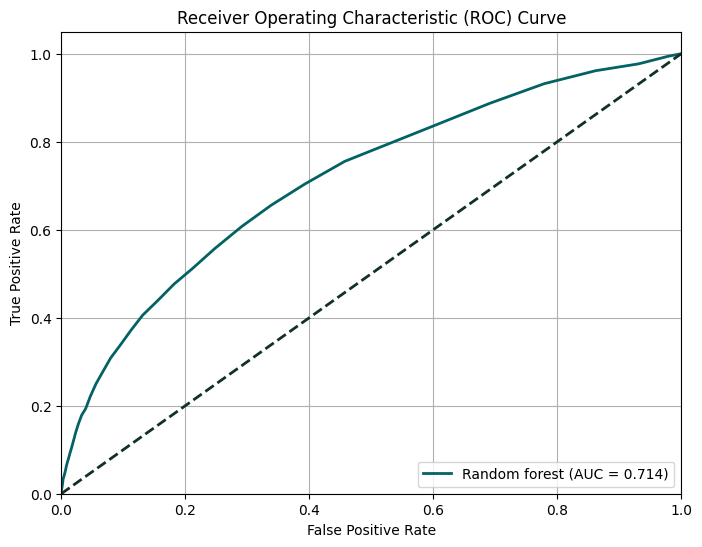

np.float64(0.7144618087044435)

In [15]:
y_probs = base_rf.predict_proba(transformed_x_val)[:, 1]
plot_roc_curve(y_val, y_probs, model_name='Random forest')

# Just the application data

XGB and LGBM classifiers will be used for modeling, as they do not require excessive processing power. For the initial runs, only application data will be used. Features that are not useful for the model will be removed.

For hyperparameter tuning, the Optuna library will be used. Four imputation strategies for handling missing values will be evaluated: mean, median, most frequent, and a constant value (-999). Since the dataset used for building parameters contains means, medians, and modes, only one of type of building parameter values will be left to make models more efficient.

## XGBClassifier

XGBClassifier is an efficient machine learning algorithm provided by the XGBoost library which stands for Extreme Gradient Boosting. XGBoost is an implementation of gradient boosted decision trees designed for speed and performance.

These hyper parameters will be tested for XGBClassifier:
- n_estimators: Defines the number of boosting rounds. More trees can increase accuracy but also the risk of overfitting and training time.
- max_depth: Limits the maximum depth of each decision tree. Deeper trees can capture more patterns but may overfit the data.
- learning_rate: Controls how much each tree contributes to the final prediction. Lower values make the model more robust but require more trees.
- subsample: Specifies the fraction of training instances to be used for growing each tree. Helps prevent overfitting.
- colsample_bytree: Fraction of features to be used when building each tree. Reduces correlation between trees and prevents overfitting.
- gamma: Minimum loss reduction required to make a further partition on a leaf node. Acts as a regularization term to control tree complexity.
- reg_alpha (L1 regularization) and reg_lambda (L2 regularization): These help prevent overfitting by adding penalties for large weights (coefficients). L1 can lead to sparsity (feature selection), while L2 reduces weight size.

#### Optuna Study

In [16]:
def objective(trial):

    impute_strategy = trial.suggest_categorical("impute_strategy", ["mean", "median", "most_frequent", "constant_-999"])
    building_param = trial.suggest_categorical('building_param', ['mean', 'median', 'mode'])
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 900),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "gamma": trial.suggest_float("gamma", 0, 5),
        "reg_alpha": trial.suggest_float("reg_alpha", 0, 10),
        "reg_lambda": trial.suggest_float("reg_lambda", 1, 10),
    }

    # Imputer and model
    if impute_strategy.startswith("constant_"):
        fill_value = float(impute_strategy.split("_")[1])
        imputer = SimpleImputer(strategy="constant", fill_value=fill_value)
    else:
        imputer = SimpleImputer(strategy=impute_strategy)

    clf = xgb.XGBClassifier(**params, random_state=8)

    pipeline = Pipeline(
        [
            ('building_param', FunctionTransformer(lambda df: df.drop(choosing_params(building_param), axis=1))),
            ('imputer', imputer),
            ('clf', clf),
        ]
    )

    # Evaluate with cross-validation
    scores = cross_val_score(pipeline, X_processed, y_train, cv=3, scoring='roc_auc')
    return np.mean(scores)


study = optuna.create_study(direction="maximize", sampler=optuna.samplers.RandomSampler(seed=8))
study.optimize(objective, n_trials=30)

best_result = study.best_trial
print("Best trial:")
print(best_result)

[I 2025-11-09 21:19:14,347] A new study created in memory with name: no-name-d4fa5a4b-9abe-41cf-a649-15878cb7e00c
[I 2025-11-09 21:20:32,725] Trial 0 finished with value: 0.7657267822815671 and parameters: {'impute_strategy': 'median', 'building_param': 'mode', 'n_estimators': 422, 'max_depth': 8, 'learning_rate': 0.050891199780757124, 'subsample': 0.7776782369111652, 'colsample_bytree': 0.7716930087712701, 'gamma': 3.804477878014645, 'reg_alpha': 7.123745740820913, 'reg_lambda': 6.577138864930957}. Best is trial 0 with value: 0.7657267822815671.
[I 2025-11-09 21:21:20,616] Trial 1 finished with value: 0.7512669968234222 and parameters: {'impute_strategy': 'most_frequent', 'building_param': 'mode', 'n_estimators': 202, 'max_depth': 6, 'learning_rate': 0.012728909063302372, 'subsample': 0.6123849694840227, 'colsample_bytree': 0.6968174574718025, 'gamma': 4.480725024403176, 'reg_alpha': 3.4546161199786707, 'reg_lambda': 9.862744935567441}. Best is trial 0 with value: 0.7657267822815671.


Best trial:
FrozenTrial(number=23, state=1, values=[0.7666539474731033], datetime_start=datetime.datetime(2025, 11, 9, 21, 49, 52, 566583), datetime_complete=datetime.datetime(2025, 11, 9, 21, 51, 39, 14352), params={'impute_strategy': 'most_frequent', 'building_param': 'mode', 'n_estimators': 772, 'max_depth': 5, 'learning_rate': 0.030766180945253675, 'subsample': 0.8629495310564325, 'colsample_bytree': 0.8690588864748121, 'gamma': 3.973296168490123, 'reg_alpha': 0.8398236965997374, 'reg_lambda': 5.105955690084617}, user_attrs={}, system_attrs={}, intermediate_values={}, distributions={'impute_strategy': CategoricalDistribution(choices=('mean', 'median', 'most_frequent', 'constant_-999')), 'building_param': CategoricalDistribution(choices=('mean', 'median', 'mode')), 'n_estimators': IntDistribution(high=900, log=False, low=100, step=1), 'max_depth': IntDistribution(high=12, log=False, low=3, step=1), 'learning_rate': FloatDistribution(high=0.3, log=True, low=0.01, step=None), 'subsamp

In [17]:
best_score = study.best_value
print(f"best roc_auc: {best_score:.3f}")

best roc_auc: 0.767


In [18]:
optuna.visualization.plot_optimization_history(study)

23th trail was the best in the Optuna study, but overall there isn't much difference between the trails, except for few outliers which performed very poorly.

#### Hyperparameters

In [19]:
optuna.visualization.plot_slice(study, params=['n_estimators', 'max_depth', 'learning_rate', 'subsample'])

In [20]:
optuna.visualization.plot_slice(study, params=['colsample_bytree', 'gamma', 'reg_alpha', 'reg_lambda'])

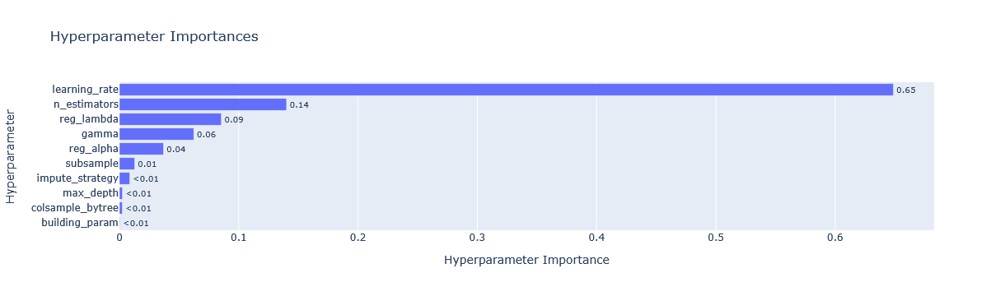

In [21]:
optuna.visualization.plot_param_importances(study)

We see that learning rate hyperparameter had the most impact on the outcome of the model, although it was not so clear in the slice plots.

#### Best parameters and confusion matrix

In [22]:
best_par = study.best_params
impute_strategy = best_par['impute_strategy']
del best_par['impute_strategy']
building_param = best_par['building_param']
del best_par['building_param']

study.best_params

{'impute_strategy': 'most_frequent',
 'building_param': 'mode',
 'n_estimators': 772,
 'max_depth': 5,
 'learning_rate': 0.030766180945253675,
 'subsample': 0.8629495310564325,
 'colsample_bytree': 0.8690588864748121,
 'gamma': 3.973296168490123,
 'reg_alpha': 0.8398236965997374,
 'reg_lambda': 5.105955690084617}

In [23]:
if impute_strategy.startswith("constant_"):
    fill_value = float(impute_strategy.split("_")[1])
    imputer = SimpleImputer(strategy="constant", fill_value=fill_value)
else:
    imputer = SimpleImputer(strategy=impute_strategy)

xgb_model = Pipeline(
    [
        ('drop_columns', FunctionTransformer(lambda df: df.drop(choosing_params(building_param), axis=1))),
        ('imput', imputer),
        ("clf", xgb.XGBClassifier(**best_par, random_state=8)),
    ]
)
xgb_model.fit(X_processed, y_train)

yhat = xgb_model.predict(transformed_x_val)
prediction = list(map(round, yhat))

cm = confusion_matrix(y_val, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y_val, prediction))

Confusion Matrix : 
 [[28208    61]
 [ 2420    62]]
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     28269
           1       0.50      0.02      0.05      2482

    accuracy                           0.92     30751
   macro avg       0.71      0.51      0.50     30751
weighted avg       0.89      0.92      0.88     30751



#### Receiver Operating Characteristic (ROC) Curve

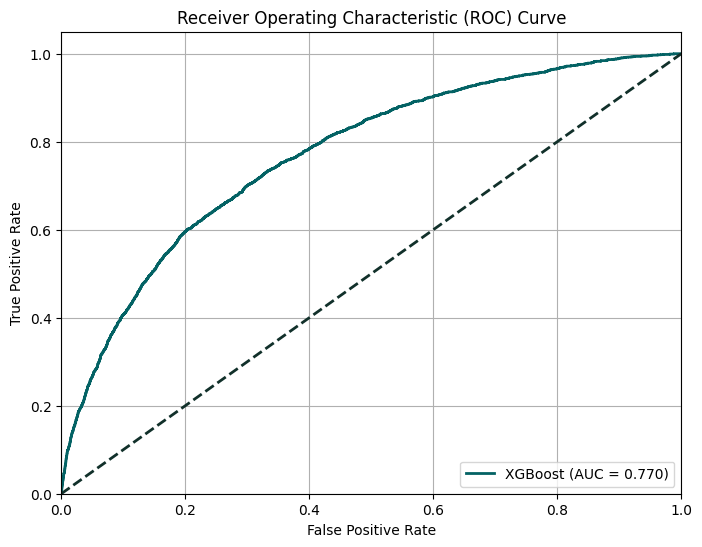

np.float64(0.7696497594238887)

In [24]:
y_probs = xgb_model.predict_proba(transformed_x_val)[:, 1]
plot_roc_curve(y_val, y_probs, model_name='XGBoost')

We can see that the XGB model on the application data performs better than the baseline as it has higher ROC AUC score (0,77). The accuracy is the same (0,92).

### Feature Importance

Features with zero importance will be added to a list for removal. If the feature is not important on both XGB and LGBM models it will be removed.

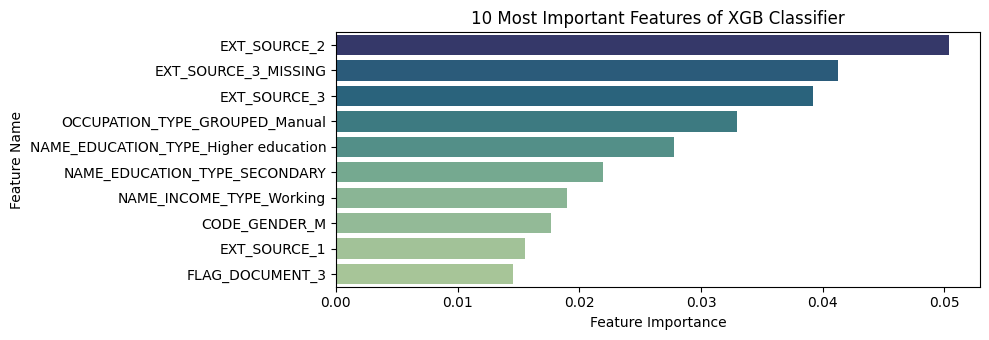

In [25]:
feature_names = X_processed.drop(choosing_params(building_param), axis=1).columns
mylist = plot_feature_importance(xgb_model, feature_names, model_name="XGB Classifier")

External sources information had the most information for predicting the value, as we can see all three of them in top ten most important features list. 

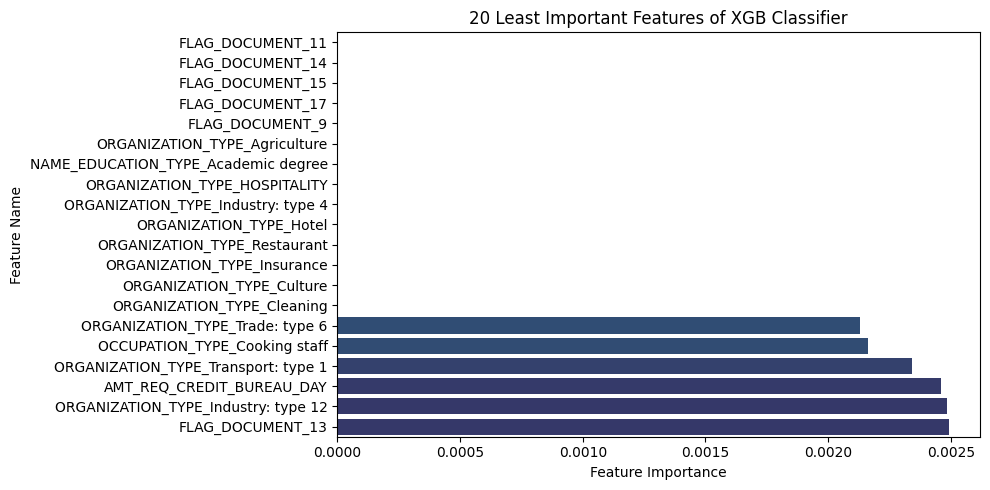

In [26]:
mylist = plot_feature_importance(xgb_model, feature_names, n=20, order="bottom", model_name="XGB Classifier")

There are 14 features with 0 importance in the model. They have been added to a list for potential removal in future runs.

In [27]:
importances = xgb_model.named_steps["clf"].feature_importances_
zero_importance_features_xgb = feature_names[importances == 0].tolist()
zero_importance_features_xgb

['FLAG_DOCUMENT_9',
 'FLAG_DOCUMENT_11',
 'FLAG_DOCUMENT_14',
 'FLAG_DOCUMENT_15',
 'FLAG_DOCUMENT_17',
 'ORGANIZATION_TYPE_HOSPITALITY',
 'NAME_EDUCATION_TYPE_Academic degree',
 'ORGANIZATION_TYPE_Agriculture',
 'ORGANIZATION_TYPE_Cleaning',
 'ORGANIZATION_TYPE_Culture',
 'ORGANIZATION_TYPE_Hotel',
 'ORGANIZATION_TYPE_Industry: type 4',
 'ORGANIZATION_TYPE_Insurance',
 'ORGANIZATION_TYPE_Restaurant']

## LGBMClassifier

LightGBM (Light Gradient Boosting Machine) is a gradient-boosting framework that uses tree-based learning algorithms and is designed for distributed and efficient training, particularly on large datasets. It uses a leaf-wise tree growth strategy (rather than level-wise like XGBoost).

These hyperparemeters will be tuned:
- n_estimators – Number of boosted trees to fit.
- learning_rate – Boosting learning rate.
- num_leaves – Maximum tree leaves for base learners.
- subsample – Subsample ratio of the training instance.
- colsample_bytree – Subsample ratio of columns when constructing each tree.
- reg_alpha – L1 regularization term on weights.
- reg_lambda – L2 regularization term on weights.

#### Optuna Study

In [28]:
def objective(trial):

    impute_strategy = trial.suggest_categorical("impute_strategy", ["mean", "median", "most_frequent", "constant_-999"])
    building_param = trial.suggest_categorical('building_param', ['mean', 'median', 'mode'])
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.3, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 7, 127),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
    }

    # Imputer and model
    if impute_strategy.startswith("constant_"):
        fill_value = float(impute_strategy.split("_")[1])
        imputer = SimpleImputer(strategy="constant", fill_value=fill_value)
    else:
        imputer = SimpleImputer(strategy=impute_strategy)

    clf = LGBMClassifier(**params, random_state=8)

    pipeline = Pipeline(
        [
            ('building_param', FunctionTransformer(lambda df: df.drop(choosing_params(building_param), axis=1))),
            ('imputer', imputer),
            ('clf', clf),
        ]
    )

    # Evaluate with cross-validation
    scores = cross_val_score(pipeline, X_processed, y_train, cv=3, scoring='roc_auc')
    return np.mean(scores)


study = optuna.create_study(direction="maximize", sampler=optuna.samplers.RandomSampler(seed=8))
study.optimize(objective, n_trials=30)

best_result = study.best_trial
print("Best trial:")
print(best_result)

[I 2025-11-09 22:03:09,733] A new study created in memory with name: no-name-57342911-9773-494c-b46a-a5dff0b83b40


[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.076556 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 6771
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 177
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.177519 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 6783
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 177
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432

[I 2025-11-09 22:04:22,110] Trial 0 finished with value: 0.7609072274291244 and parameters: {'impute_strategy': 'median', 'building_param': 'mode', 'n_estimators': 462, 'learning_rate': 0.042497621552667786, 'num_leaves': 64, 'subsample': 0.7776782369111652, 'colsample_bytree': 0.7716930087712701, 'reg_alpha': 0.07047907254411474, 'reg_lambda': 0.02578523933004178}. Best is trial 0 with value: 0.7609072274291244.


[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.136753 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7340
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 177
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.060924 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 7338
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 177
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432

[I 2025-11-09 22:06:44,072] Trial 1 finished with value: 0.7645965320312481 and parameters: {'impute_strategy': 'constant_-999', 'building_param': 'mean', 'n_estimators': 985, 'learning_rate': 0.008439501605622537, 'num_leaves': 45, 'subsample': 0.5354714223750994, 'colsample_bytree': 0.6123849694840227, 'reg_alpha': 3.489106569271376e-05, 'reg_lambda': 1.1622646898311586}. Best is trial 1 with value: 0.7645965320312481.


[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.061055 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 6771
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 177
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.073275 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 6783
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 177
[LightGBM] [

... (52 outputs left out)

[I 2025-11-09 22:39:30,278] Trial 28 finished with value: 0.762128850300123 and parameters: {'impute_strategy': 'median', 'building_param': 'mean', 'n_estimators': 151, 'learning_rate': 0.03863158955829469, 'num_leaves': 57, 'subsample': 0.7012272790679026, 'colsample_bytree': 0.5965494562641793, 'reg_alpha': 0.0003021756301955124, 'reg_lambda': 0.006794151752336533}. Best is trial 24 with value: 0.7646198221414041.


[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.072249 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 6847
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 177
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.129042 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 6866
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 177
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432

[I 2025-11-09 22:40:40,204] Trial 29 finished with value: 0.7327741341554094 and parameters: {'impute_strategy': 'median', 'building_param': 'median', 'n_estimators': 506, 'learning_rate': 0.28810218281183736, 'num_leaves': 24, 'subsample': 0.656452734572168, 'colsample_bytree': 0.5004638973367048, 'reg_alpha': 2.109601908111008e-05, 'reg_lambda': 1.2457908008847487e-06}. Best is trial 24 with value: 0.7646198221414041.


Best trial:
FrozenTrial(number=24, state=1, values=[0.7646198221414041], datetime_start=datetime.datetime(2025, 11, 9, 22, 33, 3, 615035), datetime_complete=datetime.datetime(2025, 11, 9, 22, 33, 54, 645467), params={'impute_strategy': 'most_frequent', 'building_param': 'mode', 'n_estimators': 521, 'learning_rate': 0.03591578163240314, 'num_leaves': 29, 'subsample': 0.5272110839833367, 'colsample_bytree': 0.8432662336214356, 'reg_alpha': 0.00022243509693861707, 'reg_lambda': 0.2793569604187851}, user_attrs={}, system_attrs={}, intermediate_values={}, distributions={'impute_strategy': CategoricalDistribution(choices=('mean', 'median', 'most_frequent', 'constant_-999')), 'building_param': CategoricalDistribution(choices=('mean', 'median', 'mode')), 'n_estimators': IntDistribution(high=1000, log=False, low=100, step=1), 'learning_rate': FloatDistribution(high=0.3, log=True, low=0.005, step=None), 'num_leaves': IntDistribution(high=127, log=False, low=7, step=1), 'subsample': FloatDistribu

In [29]:
best_score = study.best_value
print(f"best roc_auc: {best_score:.3f}")

best roc_auc: 0.765


In [30]:
optuna.visualization.plot_optimization_history(study)

24th trail was the best in the Optuna study.

#### Hyperparameters

In [31]:
optuna.visualization.plot_slice(study, params=['n_estimators', "learning_rate", "num_leaves", 'subsample'])

In [32]:
optuna.visualization.plot_slice(study, params=["colsample_bytree", "reg_alpha", "reg_lambda"])

In [33]:
optuna.visualization.plot_param_importances(study)

Learning rate is the most important hyperparameter in tuning. The same can be seen from the slice plots.

#### Best parameters and confusion matrix

In [34]:
best_par = study.best_params
impute_strategy = best_par['impute_strategy']
del best_par['impute_strategy']
building_param = best_par['building_param']
del best_par['building_param']

study.best_params

{'impute_strategy': 'most_frequent',
 'building_param': 'mode',
 'n_estimators': 521,
 'learning_rate': 0.03591578163240314,
 'num_leaves': 29,
 'subsample': 0.5272110839833367,
 'colsample_bytree': 0.8432662336214356,
 'reg_alpha': 0.00022243509693861707,
 'reg_lambda': 0.2793569604187851}

In [35]:
if impute_strategy.startswith("constant_"):
    fill_value = float(impute_strategy.split("_")[1])
    imputer = SimpleImputer(strategy="constant", fill_value=fill_value)
else:
    imputer = SimpleImputer(strategy=impute_strategy)

light_model = Pipeline(
    [
        ('drop_columns', FunctionTransformer(lambda df: df.drop(choosing_params(building_param), axis=1))),
        ('imput', imputer),
        ("clf", LGBMClassifier(**best_par, random_state=8)),
    ]
)
light_model.fit(X_processed, y_train)

yhat = light_model.predict(transformed_x_val)
prediction = list(map(round, yhat))

cm = confusion_matrix(y_val, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y_val, prediction))

[LightGBM] [Info] Number of positive: 19860, number of negative: 226148
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.123423 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 6792
[LightGBM] [Info] Number of data points in the train set: 246008, number of used features: 177
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432482
[LightGBM] [Info] Start training from score -2.432482
Confusion Matrix : 
 [[28206    63]
 [ 2423    59]]
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     28269
           1       0.48      0.02      0.05      2482

    accuracy                           0.92     30751
   macro avg       0.70      0.51      0.50     30751
weighted avg       0.89      0.92      0.88     30751



#### Receiver Operating Characteristic (ROC) Curve

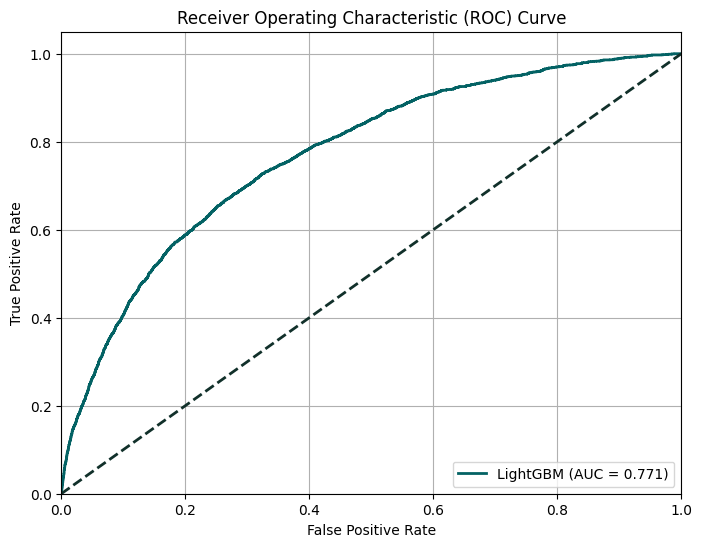

np.float64(0.7706119740792305)

In [36]:
y_probs = light_model.predict_proba(transformed_x_val)[:, 1]
plot_roc_curve(y_val, y_probs, model_name='LightGBM')

LGBM model has slightly better AUC than XGB model (0,771 vs 0,77). 

### Feature Importance

Features with low importance will be added to a list for removal. If the feature is not important on both XGB and LGBM models it will be removed.

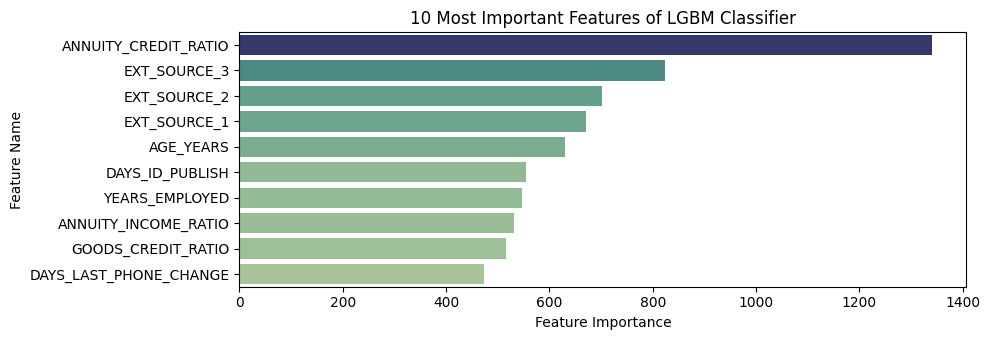

In [37]:
feature_names = X_processed.drop(choosing_params(building_param), axis=1).columns
mylist = plot_feature_importance(light_model, feature_names, model_name="LGBM Classifier")

External sources were also important for LGBM classifier just like for XGB classifier. However, the most important feature in this case is annuity credit ratio.

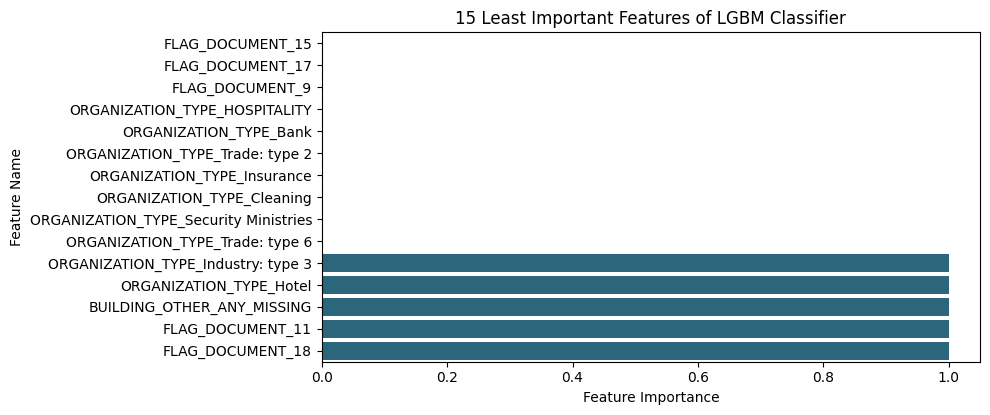

In [38]:
mylist = plot_feature_importance(light_model, feature_names, n=15, order="bottom", model_name="LGBM Classifier")

There are 10 features which have no importance in the model. They have been added to the list for potential removal.

In [39]:
importances = light_model.named_steps["clf"].feature_importances_
zero_importance_features_light = feature_names[importances == 0].tolist()

In [40]:
for item in zero_importance_features_xgb:
    if item in zero_importance_features_light:
        list_to_remove.append(item)

In [41]:
list_to_remove

['FLAG_DOCUMENT_9',
 'FLAG_DOCUMENT_15',
 'FLAG_DOCUMENT_17',
 'ORGANIZATION_TYPE_HOSPITALITY',
 'ORGANIZATION_TYPE_Cleaning',
 'ORGANIZATION_TYPE_Insurance']

These 6 features will be removed, as they weren't important in both LGBM and XGB classifiers.

# Adding Removing Outliers and Dimention Reduction

XGB and LGBM classifiers will be used for modeling. Only application data. Adding removing outliers and dimention reduction to test. Also, the model will test for class imbalance (scale_pos_weight). For balance of positive and negative weights a typical value will be used: sum(negative instances) / sum(positive instances).

- scale_pos_weight: Helps with imbalanced classification tasks by giving more importance to the minority class. It’s typically set to the ratio of negative to positive samples.

Dimention reduction techniques to be used:
- Principal Component Analysis (PCA) is a linear dimensionality reduction technique which converts a set of correlated features in the high dimensional space into a series of uncorrelated features in the low dimensional space. These uncorrelated features are also called principal components. 
- Singular Value Decomposition (SVD) is a matrix factorization technique widely used in various applications, including linear algebra, signal processing, and machine learning. It decomposes a matrix into three other matrices, allowing for the representation of the original matrix in a reduced form.

In [42]:
preprocessor = make_pipeline(
    FunctionTransformer(preprocess_app, validate=False),
)

X_processed = preprocessor.fit_transform(x_train)
transformed_x_val = preprocessor.transform(x_val)

pos, neg = np.bincount(y_train)
ratio = neg / pos
ratio

np.float64(0.08781859667120646)

## XGBClassifier

#### Optuna Study

In [43]:
def objective(trial):

    impute_strategy = trial.suggest_categorical("impute_strategy", ["mean", "median", "most_frequent", "constant_-999"])
    building_param = trial.suggest_categorical('building_param', ['mean', 'median', 'mode'])
    outlier_factor = trial.suggest_float("outlier_factor", 1.5, 4.0)
    dim_red_method = trial.suggest_categorical("dim_red_method", ["none", "pca", "svd"])

    dim_red = None
    if dim_red_method == "pca":
        n_components = trial.suggest_float("pca_n_components", 0.8, 0.99)
        dim_red = PCA(n_components=n_components)
    elif dim_red_method == "svd":
        n_components = trial.suggest_int("svd_components", 5, min(x_train.shape[1] - 1, 50))
        dim_red = TruncatedSVD(n_components=n_components)

    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 900),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "gamma": trial.suggest_float("gamma", 0, 5),
        "reg_alpha": trial.suggest_float("reg_alpha", 0, 10),
        "reg_lambda": trial.suggest_float("reg_lambda", 1, 10),
        "scale_pos_weight": trial.suggest_categorical("scale_pos_weight", [ratio, 1]),
    }

    # Imputer and model
    if impute_strategy.startswith("constant_"):
        fill_value = float(impute_strategy.split("_")[1])
        imputer = SimpleImputer(strategy="constant", fill_value=fill_value)
    else:
        imputer = SimpleImputer(strategy=impute_strategy)

    clf = xgb.XGBClassifier(**params, random_state=8)

    steps = [
        ('building_param', FunctionTransformer(lambda df: df.drop(choosing_params(building_param), axis=1))),
        ('remove_outliers', FunctionTransformer(lambda df: remove_outliers_iqr(df, factor=outlier_factor))),
        ('imputer', imputer),
        ('dim_red', dim_red),
        ('clf', clf),
    ]

    pipeline = Pipeline(steps)

    # Evaluate with cross-validation
    scores = cross_val_score(pipeline, X_processed, y_train, cv=3, scoring='roc_auc')
    return np.mean(scores)


study = optuna.create_study(direction="maximize", sampler=optuna.samplers.RandomSampler(seed=8))
study.optimize(objective, n_trials=30)

best_result = study.best_trial
print("Best trial:")
print(best_result)

[I 2025-11-09 22:41:12,994] A new study created in memory with name: no-name-a770fb9d-4d05-4ecc-b889-0eec314a76c9
[I 2025-11-09 22:42:35,955] Trial 0 finished with value: 0.6658507306699102 and parameters: {'impute_strategy': 'median', 'building_param': 'mode', 'outlier_factor': 2.505878400093412, 'dim_red_method': 'svd', 'svd_components': 29, 'n_estimators': 709, 'max_depth': 10, 'learning_rate': 0.0822897220336018, 'subsample': 0.7130458852380961, 'colsample_bytree': 0.6445375140090439, 'gamma': 4.869276206002231, 'reg_alpha': 3.3377404551067036, 'reg_lambda': 2.9692095473784517, 'scale_pos_weight': 1}. Best is trial 0 with value: 0.6658507306699102.
[I 2025-11-09 22:44:10,705] Trial 1 finished with value: 0.6682442323918846 and parameters: {'impute_strategy': 'median', 'building_param': 'median', 'outlier_factor': 3.9618735932131783, 'dim_red_method': 'svd', 'svd_components': 40, 'n_estimators': 851, 'max_depth': 6, 'learning_rate': 0.043533079754951284, 'subsample': 0.6350728707957

Best trial:
FrozenTrial(number=12, state=1, values=[0.7643857747257209], datetime_start=datetime.datetime(2025, 11, 9, 22, 53, 34, 300306), datetime_complete=datetime.datetime(2025, 11, 9, 22, 55, 23, 682536), params={'impute_strategy': 'mean', 'building_param': 'mode', 'outlier_factor': 3.081881436202404, 'dim_red_method': 'none', 'n_estimators': 581, 'max_depth': 5, 'learning_rate': 0.026513150871925604, 'subsample': 0.5834163743961864, 'colsample_bytree': 0.8537599043019748, 'gamma': 4.280691090371335, 'reg_alpha': 2.1944594126694863, 'reg_lambda': 1.5587496731783848, 'scale_pos_weight': 1}, user_attrs={}, system_attrs={}, intermediate_values={}, distributions={'impute_strategy': CategoricalDistribution(choices=('mean', 'median', 'most_frequent', 'constant_-999')), 'building_param': CategoricalDistribution(choices=('mean', 'median', 'mode')), 'outlier_factor': FloatDistribution(high=4.0, log=False, low=1.5, step=None), 'dim_red_method': CategoricalDistribution(choices=('none', 'pca'

In [44]:
best_score = study.best_value
print(f"best roc_auc: {best_score:.3f}")

best roc_auc: 0.764


In [45]:
optuna.visualization.plot_optimization_history(study)

12th trail was the best in the Optuna study.

#### Hyperparameters

In [46]:
optuna.visualization.plot_slice(study, params=['outlier_factor', 'building_param', 'impute_strategy', 'dim_red_method'])

In [47]:
optuna.visualization.plot_slice(study, params=['n_estimators', 'max_depth', 'learning_rate'])

In [48]:
optuna.visualization.plot_slice(study, params=['subsample', 'colsample_bytree', 'gamma'])

In [49]:
optuna.visualization.plot_slice(study, params=['reg_alpha', 'reg_lambda', 'scale_pos_weight'])

In [50]:
optuna.visualization.plot_param_importances(study)

In this case adding dimension reduction greatly reduced score of the model.

#### Best parameters and confusion matrix

In [51]:
best_par = study.best_params
impute_strategy = best_par['impute_strategy']
del best_par['impute_strategy']
building_param = best_par['building_param']
del best_par['building_param']
outlier_factor = best_par['outlier_factor']
del best_par['outlier_factor']
dim_red_method = best_par['dim_red_method']
del best_par['dim_red_method']

study.best_params

{'impute_strategy': 'mean',
 'building_param': 'mode',
 'outlier_factor': 3.081881436202404,
 'dim_red_method': 'none',
 'n_estimators': 581,
 'max_depth': 5,
 'learning_rate': 0.026513150871925604,
 'subsample': 0.5834163743961864,
 'colsample_bytree': 0.8537599043019748,
 'gamma': 4.280691090371335,
 'reg_alpha': 2.1944594126694863,
 'reg_lambda': 1.5587496731783848,
 'scale_pos_weight': 1}

In [52]:
if impute_strategy.startswith("constant_"):
    fill_value = float(impute_strategy.split("_")[1])
    imputer = SimpleImputer(strategy="constant", fill_value=fill_value)
else:
    imputer = SimpleImputer(strategy=impute_strategy)

xgb_model = Pipeline(
    [
        ('drop_columns', FunctionTransformer(lambda df: df.drop(choosing_params(building_param), axis=1))),
        ('remove_outliers', FunctionTransformer(lambda df: remove_outliers_iqr(df, factor=outlier_factor))),
        ('imput', imputer),
        ("clf", xgb.XGBClassifier(**best_par, random_state=8)),
    ]
)
xgb_model.fit(X_processed, y_train)

yhat = xgb_model.predict(transformed_x_val)
prediction = list(map(round, yhat))

cm = confusion_matrix(y_val, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y_val, prediction))

Confusion Matrix : 
 [[28212    57]
 [ 2425    57]]
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     28269
           1       0.50      0.02      0.04      2482

    accuracy                           0.92     30751
   macro avg       0.71      0.51      0.50     30751
weighted avg       0.89      0.92      0.88     30751



#### Receiver Operating Characteristic (ROC) Curve

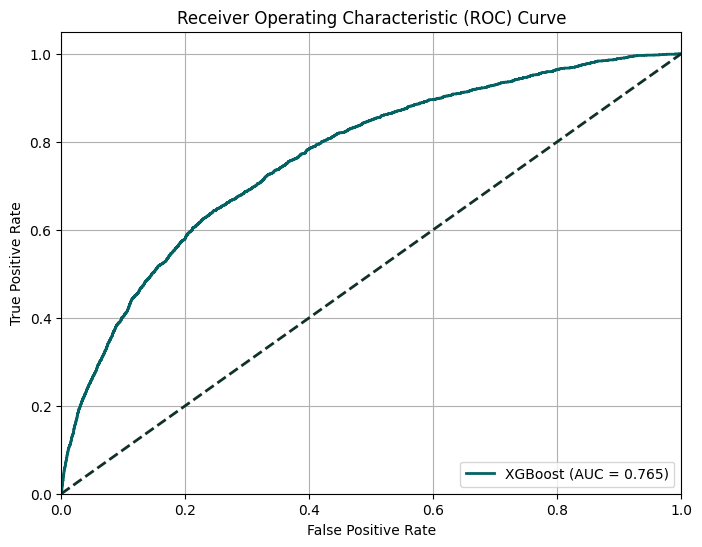

np.float64(0.7652558251737673)

In [53]:
y_probs = xgb_model.predict_proba(transformed_x_val)[:, 1]
plot_roc_curve(y_val, y_probs, model_name='XGBoost')

The models AUC score is worse, but overall the model performs similarly to the first one. We can see that reducing dimentions in the model does not improve it and overall better models are with without dimention reduction techniques.

### Feature Importance

Features with zero importance will be added to a list for removal. If the feature is not important on both XGB and LGBM models it will be removed.

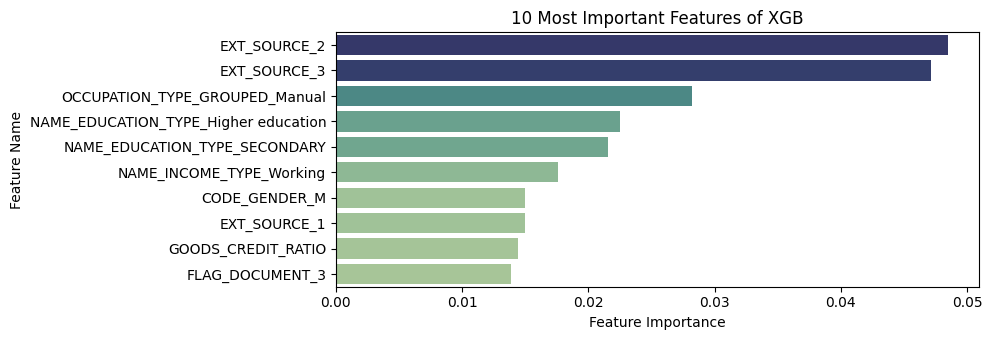

In [54]:
feature_names = X_processed.drop(choosing_params(building_param), axis=1).columns
mylist = plot_feature_importance(xgb_model, feature_names, model_name="XGB")

External sources information remains an important factor for predicting the target. 

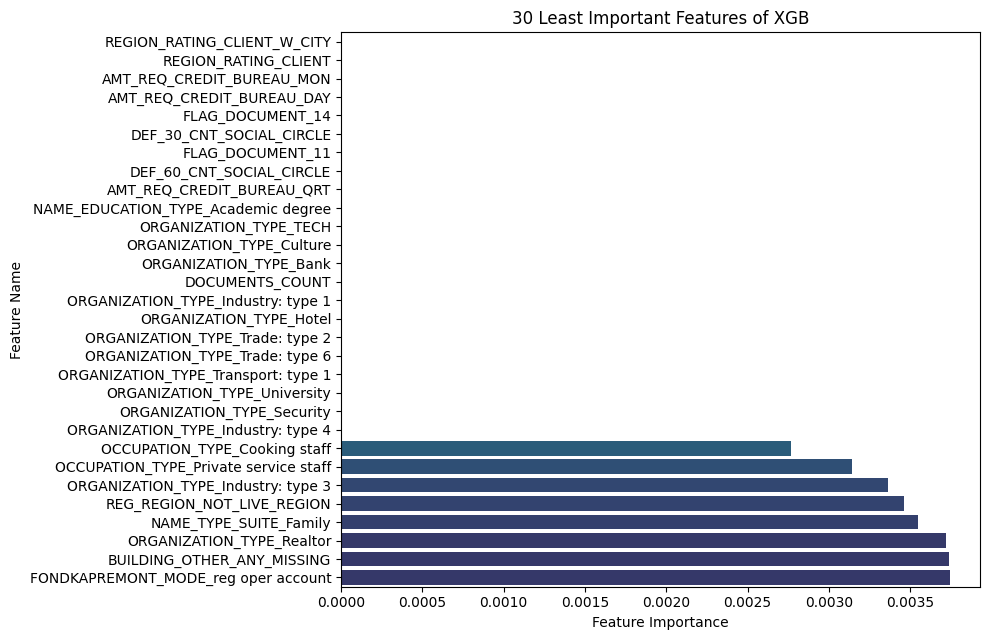

In [55]:
mylist = plot_feature_importance(xgb_model, feature_names, n=30, order="bottom", model_name="XGB")

There are 22 features with 0 importance in this case.

In [56]:
importances = xgb_model.named_steps["clf"].feature_importances_
zero_importance_features_xgb_2 = feature_names[importances == 0].tolist()

## LGBMClassifier

#### Optuna Study

In [57]:
def objective(trial):
    # Hyperparameters
    impute_strategy = trial.suggest_categorical("impute_strategy", ["mean", "median", "most_frequent", "constant_-999"])
    outlier_factor = trial.suggest_float("outlier_factor", 1.5, 4.0)
    building_param = trial.suggest_categorical('building_param', ['mean', 'median', 'mode'])
    dim_red_method = trial.suggest_categorical("dim_red_method", ["none", "pca", "svd"])

    dim_red = None
    if dim_red_method == "pca":
        n_components = trial.suggest_float("pca_n_components", 0.8, 0.99)
        dim_red = PCA(n_components=n_components)
    elif dim_red_method == "svd":
        n_components = trial.suggest_int("svd_components", 5, min(x_train.shape[1] - 1, 50))
        dim_red = TruncatedSVD(n_components=n_components)

    pos, neg = np.bincount(y_train)
    ratio = neg / pos

    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.3, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 7, 127),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
        "scale_pos_weight": trial.suggest_categorical("scale_pos_weight", [ratio, 1]),
    }

    # Imputer and model
    if impute_strategy.startswith("constant_"):
        fill_value = float(impute_strategy.split("_")[1])
        imputer = SimpleImputer(strategy="constant", fill_value=fill_value)
    else:
        imputer = SimpleImputer(strategy=impute_strategy)

    clf = LGBMClassifier(**params, random_state=8)

    steps = [
        ('building_param', FunctionTransformer(lambda df: df.drop(choosing_params(building_param), axis=1))),
        ('remove_outliers', FunctionTransformer(lambda df: remove_outliers_iqr(df, factor=outlier_factor))),
        ('imputer', imputer),
        ('dim_red', dim_red),
        ('clf', clf),
    ]

    pipeline = Pipeline(steps)

    # Evaluate with cross-validation
    scores = cross_val_score(pipeline, X_processed, y_train, cv=3, scoring='roc_auc')
    return np.mean(scores)


# Run optimization
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.RandomSampler(seed=8))
study.optimize(objective, n_trials=30)

best_result = study.best_trial
print("Best trial:")
print(best_result)

[I 2025-11-09 23:17:31,343] A new study created in memory with name: no-name-b3d9a259-08f8-4c02-9962-58e670d0b0b1


[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.034870 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7395
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 29
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped training because there are no more leaves 

[I 2025-11-09 23:18:27,586] Trial 0 finished with value: 0.5 and parameters: {'impute_strategy': 'median', 'outlier_factor': 2.0818208199432267, 'building_param': 'median', 'dim_red_method': 'svd', 'svd_components': 29, 'n_estimators': 785, 'learning_rate': 0.09240165373869441, 'num_leaves': 81, 'subsample': 0.7130458852380961, 'colsample_bytree': 0.6445375140090439, 'reg_alpha': 5.816974645028655, 'reg_lambda': 1.0091748286696615e-05, 'scale_pos_weight': np.float64(0.08781859667120646)}. Best is trial 0 with value: 0.5.


[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.055555 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 6340
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 163
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.048653 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 6347
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 163
[LightGBM] [

[I 2025-11-09 23:19:38,060] Trial 1 finished with value: 0.7463572896672582 and parameters: {'impute_strategy': 'mean', 'outlier_factor': 2.0619248474201135, 'building_param': 'median', 'dim_red_method': 'none', 'n_estimators': 443, 'learning_rate': 0.11422529738630657, 'num_leaves': 120, 'subsample': 0.6598448982335139, 'colsample_bytree': 0.7162379663952079, 'reg_alpha': 2.6996761779657997e-06, 'reg_lambda': 0.16199550980940675, 'scale_pos_weight': np.float64(0.08781859667120646)}. Best is trial 1 with value: 0.7463572896672582.


[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.011841 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3570
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 14
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.014679 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3570
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 14
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[LightGB

... (52 outputs left out)

[I 2025-11-09 23:40:15,303] Trial 28 finished with value: 0.6666035142248191 and parameters: {'impute_strategy': 'mean', 'outlier_factor': 3.677960147364517, 'building_param': 'mode', 'dim_red_method': 'svd', 'svd_components': 25, 'n_estimators': 430, 'learning_rate': 0.018528695557126856, 'num_leaves': 117, 'subsample': 0.8776510808863517, 'colsample_bytree': 0.8905417895223162, 'reg_alpha': 0.005874506478751591, 'reg_lambda': 0.04085378980613044, 'scale_pos_weight': 1}. Best is trial 20 with value: 0.7619589663069819.


[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000711 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 255
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 1
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000858 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 255
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 1
[LightGBM] [Info] 

[I 2025-11-09 23:40:49,874] Trial 29 finished with value: 0.5681395608545453 and parameters: {'impute_strategy': 'median', 'outlier_factor': 3.8798374310530175, 'building_param': 'median', 'dim_red_method': 'pca', 'pca_n_components': 0.8071414362902307, 'n_estimators': 311, 'learning_rate': 0.2687521903003153, 'num_leaves': 96, 'subsample': 0.7884072078460715, 'colsample_bytree': 0.6416368427921215, 'reg_alpha': 5.375947564163693e-08, 'reg_lambda': 0.008942486219491452, 'scale_pos_weight': 1}. Best is trial 20 with value: 0.7619589663069819.


Best trial:
FrozenTrial(number=20, state=1, values=[0.7619589663069819], datetime_start=datetime.datetime(2025, 11, 9, 23, 32, 56, 681522), datetime_complete=datetime.datetime(2025, 11, 9, 23, 34, 55, 354832), params={'impute_strategy': 'median', 'outlier_factor': 3.9099331462543154, 'building_param': 'mode', 'dim_red_method': 'none', 'n_estimators': 981, 'learning_rate': 0.02885659458526185, 'num_leaves': 99, 'subsample': 0.5352127373338929, 'colsample_bytree': 0.8077027614158246, 'reg_alpha': 2.9335569863014334e-05, 'reg_lambda': 1.1583646783800938, 'scale_pos_weight': np.float64(0.08781859667120646)}, user_attrs={}, system_attrs={}, intermediate_values={}, distributions={'impute_strategy': CategoricalDistribution(choices=('mean', 'median', 'most_frequent', 'constant_-999')), 'outlier_factor': FloatDistribution(high=4.0, log=False, low=1.5, step=None), 'building_param': CategoricalDistribution(choices=('mean', 'median', 'mode')), 'dim_red_method': CategoricalDistribution(choices=('no

In [58]:
best_score = study.best_value
print(f"best roc_auc: {best_score:.3f}")

best roc_auc: 0.762


In [59]:
optuna.visualization.plot_optimization_history(study)

20th trail was the best in the Optuna study.

#### Hyperparameters

In [60]:
optuna.visualization.plot_slice(study, params=['outlier_factor', 'building_param', 'impute_strategy', 'dim_red_method'])

In [61]:
optuna.visualization.plot_slice(study, params=['n_estimators', "learning_rate", "num_leaves", 'subsample'])

In [62]:
optuna.visualization.plot_slice(study, params=["colsample_bytree", "reg_alpha", "reg_lambda", "scale_pos_weight"])

In [63]:
optuna.visualization.plot_param_importances(study)

LGBM also didn't perform better after adding dimension reduction techniques.

#### Best parameters and confusion matrix

In [64]:
best_par = study.best_params
impute_strategy = best_par['impute_strategy']
del best_par['impute_strategy']
building_param = best_par['building_param']
del best_par['building_param']
outlier_factor = best_par['outlier_factor']
del best_par['outlier_factor']
dim_red_method = best_par['dim_red_method']
del best_par['dim_red_method']

study.best_params

{'impute_strategy': 'median',
 'outlier_factor': 3.9099331462543154,
 'building_param': 'mode',
 'dim_red_method': 'none',
 'n_estimators': 981,
 'learning_rate': 0.02885659458526185,
 'num_leaves': 99,
 'subsample': 0.5352127373338929,
 'colsample_bytree': 0.8077027614158246,
 'reg_alpha': 2.9335569863014334e-05,
 'reg_lambda': 1.1583646783800938,
 'scale_pos_weight': np.float64(0.08781859667120646)}

In [65]:
if impute_strategy.startswith("constant_"):
    fill_value = float(impute_strategy.split("_")[1])
    imputer = SimpleImputer(strategy="constant", fill_value=fill_value)
else:
    imputer = SimpleImputer(strategy=impute_strategy)

light_model = Pipeline(
    [
        ('drop_columns', FunctionTransformer(lambda df: df.drop(choosing_params(building_param), axis=1))),
        ('remove_outliers', FunctionTransformer(lambda df: remove_outliers_iqr(df, factor=outlier_factor))),
        ('imput', imputer),
        ("clf", LGBMClassifier(**best_par, random_state=8)),
    ]
)
light_model.fit(X_processed, y_train)

yhat = light_model.predict(transformed_x_val)
prediction = list(map(round, yhat))

cm = confusion_matrix(y_val, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y_val, prediction))

[LightGBM] [Info] Number of positive: 19860, number of negative: 226148
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.076661 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 6427
[LightGBM] [Info] Number of data points in the train set: 246008, number of used features: 163
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432482
[LightGBM] [Info] Start training from score -2.432482
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Confusion Matrix : 
 [[28266     3]
 [ 2480     2]]
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     28269
           1       0.40      0.00      0.00      2482

#### Receiver Operating Characteristic (ROC) Curve

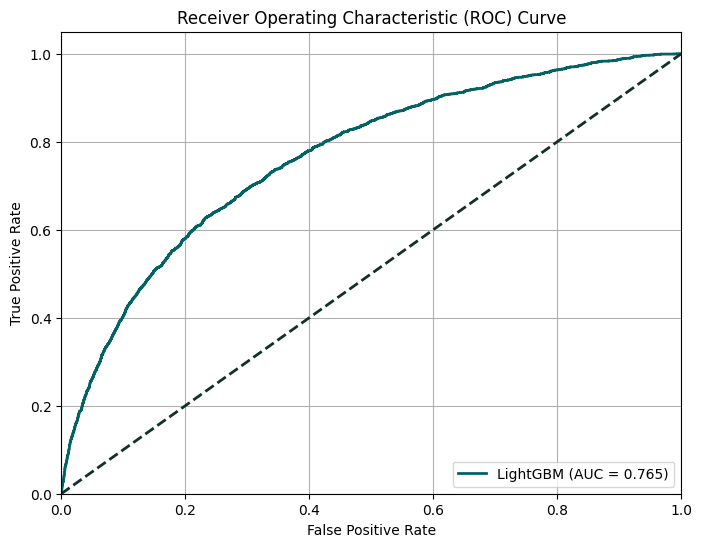

np.float64(0.7645815159751221)

In [66]:
y_probs = light_model.predict_proba(transformed_x_val)[:, 1]
plot_roc_curve(y_val, y_probs, model_name='LightGBM')

The models AUC score is worse, and the model does not perform better than first one.

### Feature Importance

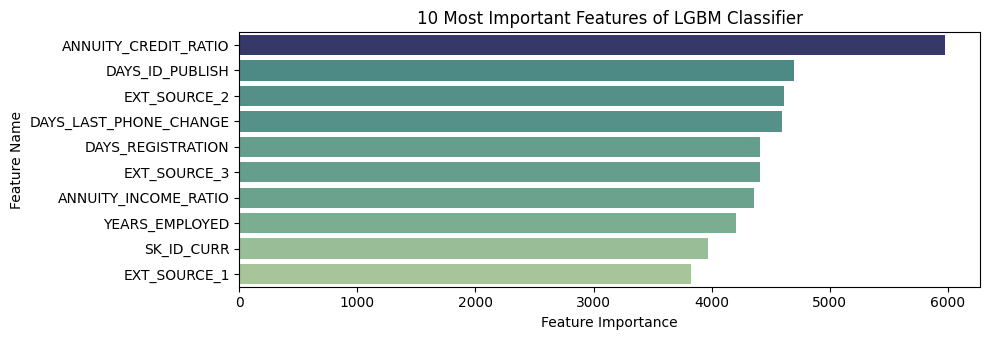

In [67]:
feature_names = X_processed.drop(choosing_params(building_param), axis=1).columns
mylist = plot_feature_importance(light_model, feature_names, model_name="LGBM Classifier")

External source information is among the top 10 most important features; however, the annuity-to-credit ratio and Days ID Publish were the most influential in determining the target.

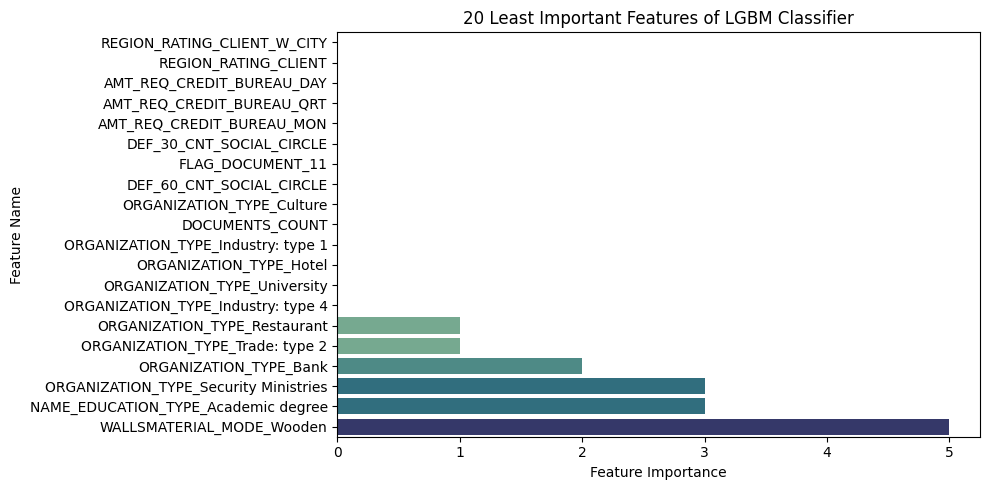

In [68]:
mylist = plot_feature_importance(light_model, feature_names, order="bottom", n=20, model_name="LGBM Classifier")

16 features were not important in the LGBM model. They were added to the list for portential removal.

In [69]:
importances = light_model.named_steps["clf"].feature_importances_
zero_importance_features_light_2 = feature_names[importances == 0].tolist()

list_to_remove_2 = []
for item in zero_importance_features_xgb_2:
    if item in zero_importance_features_light_2:
        list_to_remove_2.append(item)

list_to_remove_2

['REGION_RATING_CLIENT',
 'REGION_RATING_CLIENT_W_CITY',
 'DEF_30_CNT_SOCIAL_CIRCLE',
 'DEF_60_CNT_SOCIAL_CIRCLE',
 'FLAG_DOCUMENT_11',
 'AMT_REQ_CREDIT_BUREAU_DAY',
 'AMT_REQ_CREDIT_BUREAU_MON',
 'AMT_REQ_CREDIT_BUREAU_QRT',
 'DOCUMENTS_COUNT',
 'ORGANIZATION_TYPE_Culture',
 'ORGANIZATION_TYPE_Hotel',
 'ORGANIZATION_TYPE_Industry: type 1',
 'ORGANIZATION_TYPE_Industry: type 4',
 'ORGANIZATION_TYPE_University']

In [70]:
list_to_remove.extend(list_to_remove_2)

In this case there are more features to add to removed list. 

# All of the data 

Here all of the data will be tested for modelling, including suplementary data.

In [71]:
preprocessor = make_pipeline(
    FunctionTransformer(preprocess_app, validate=False),
    FunctionTransformer(connect_all, validate=False),
)

X_processed = preprocessor.fit_transform(x_train)
transformed_x_val = preprocessor.transform(x_val)

## XGBClassifier

### Version 1

#### Optuna Study

XGB classifier using all of the data (main application data and supplementary data). Dimention reduction methods will not be used, as they reduce AUC ROC score significantly. 

In [72]:
def objective(trial):
    # Hyperparameters
    impute_strategy = trial.suggest_categorical("impute_strategy", ["mean", "median", "most_frequent", "constant_-999"])
    building_param = trial.suggest_categorical('building_param', ['mean', 'median', 'mode'])
    outlier_factor = trial.suggest_float("outlier_factor", 1.5, 4.0)

    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 2000),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "gamma": trial.suggest_float("gamma", 0, 5),
        "reg_alpha": trial.suggest_float("reg_alpha", 0, 10),
        "reg_lambda": trial.suggest_float("reg_lambda", 1, 10),
        "scale_pos_weight": trial.suggest_categorical("scale_pos_weight", [ratio, 1]),
    }

    # Imputer and model
    if impute_strategy.startswith("constant_"):
        fill_value = float(impute_strategy.split("_")[1])
        imputer = SimpleImputer(strategy="constant", fill_value=fill_value)
    else:
        imputer = SimpleImputer(strategy=impute_strategy)

    clf = xgb.XGBClassifier(**params, random_state=8)

    pipeline = Pipeline(
        [
            ('building_param', FunctionTransformer(lambda df: df.drop(choosing_params(building_param), axis=1))),
            ('remove_outliers', FunctionTransformer(lambda df: remove_outliers_iqr(df, factor=outlier_factor))),
            ('imputer', imputer),
            ('clf', clf),
        ]
    )

    # Evaluate with cross-validation

    scores = cross_val_score(pipeline, X_processed, y_train, cv=3, scoring='roc_auc')
    return np.mean(scores)


# Run optimization
study_xgb_1 = optuna.create_study(direction="maximize", sampler=optuna.samplers.RandomSampler(seed=8))
study_xgb_1.optimize(objective, n_trials=50)

best_result = study_xgb_1.best_trial
print("Best trial:")
print(best_result)

[I 2025-11-09 23:50:00,662] A new study created in memory with name: no-name-8c0dd26e-99a2-4feb-93d3-b201b66ff769
[I 2025-11-09 23:54:38,637] Trial 0 finished with value: 0.7786093074589339 and parameters: {'impute_strategy': 'median', 'building_param': 'mode', 'outlier_factor': 2.505878400093412, 'n_estimators': 1093, 'max_depth': 7, 'learning_rate': 0.0661193920092195, 'subsample': 0.7716930087712701, 'colsample_bytree': 0.8804477878014645, 'gamma': 3.5618728704104563, 'reg_alpha': 6.196820961034396, 'reg_lambda': 4.83482593428573, 'scale_pos_weight': 1}. Best is trial 0 with value: 0.7786093074589339.
[I 2025-11-09 23:57:46,642] Trial 1 finished with value: 0.7656271130588936 and parameters: {'impute_strategy': 'constant_-999', 'building_param': 'median', 'outlier_factor': 2.0619248474201135, 'n_estimators': 848, 'max_depth': 11, 'learning_rate': 0.03238088317448776, 'subsample': 0.9923747186426357, 'colsample_bytree': 0.5143660244816477, 'gamma': 1.7584236813506005, 'reg_alpha': 3.

Best trial:
FrozenTrial(number=28, state=1, values=[0.7843179775925577], datetime_start=datetime.datetime(2025, 11, 10, 1, 36, 11, 930990), datetime_complete=datetime.datetime(2025, 11, 10, 1, 43, 46, 760756), params={'impute_strategy': 'constant_-999', 'building_param': 'mode', 'outlier_factor': 3.7505819911764084, 'n_estimators': 1603, 'max_depth': 5, 'learning_rate': 0.018820735746177587, 'subsample': 0.8389550046273759, 'colsample_bytree': 0.5288144455814897, 'gamma': 2.3570126169620083, 'reg_alpha': 9.177487359855984, 'reg_lambda': 6.618920919541211, 'scale_pos_weight': 1}, user_attrs={}, system_attrs={}, intermediate_values={}, distributions={'impute_strategy': CategoricalDistribution(choices=('mean', 'median', 'most_frequent', 'constant_-999')), 'building_param': CategoricalDistribution(choices=('mean', 'median', 'mode')), 'outlier_factor': FloatDistribution(high=4.0, log=False, low=1.5, step=None), 'n_estimators': IntDistribution(high=2000, log=False, low=100, step=1), 'max_dep

In [73]:
best_score = study_xgb_1.best_value
print(f"best roc_auc: {best_score:.3f}")

best roc_auc: 0.784


In [74]:
optuna.visualization.plot_optimization_history(study_xgb_1)

28th trail was the best in the Optuna study.

#### Hyperparameters

In [75]:
optuna.visualization.plot_slice(study_xgb_1, params=['outlier_factor', 'building_param', 'impute_strategy'])

At first glance, it seems that median building parameters perform worse. Mean and constant impute strateties seem to perform better. There are no clear tendencies for outlier factor.

In [76]:
optuna.visualization.plot_slice(study_xgb_1, params=['n_estimators', 'max_depth', 'learning_rate'])

There is clear tendency for higher learning rate to perform worse. Also it seems that the model performs better with more estimators.

In [77]:
optuna.visualization.plot_slice(study_xgb_1, params=['subsample', 'colsample_bytree', 'gamma'])

No clear tendencies to be seen here.

In [78]:
optuna.visualization.plot_slice(study_xgb_1, params=['reg_alpha', 'reg_lambda', 'scale_pos_weight'])

It seems that without taking into account imbalanced classification tasks by giving more importance to the minority class the model performs better (just leaving default value of 1 for scale_pos_weight performs better).

In [79]:
optuna.visualization.plot_param_importances(study_xgb_1)

According to hyperparameter importance learning rate is indeed the most impactful. It seems that even we could see some tendencies for building params, they were not that important.

#### Best parameters and confusion matrix

In [80]:
best_par = study_xgb_1.best_params
impute_strategy = best_par['impute_strategy']
del best_par['impute_strategy']
building_param = best_par['building_param']
del best_par['building_param']
outlier_factor = best_par['outlier_factor']
del best_par['outlier_factor']

study_xgb_1.best_params

{'impute_strategy': 'constant_-999',
 'building_param': 'mode',
 'outlier_factor': 3.7505819911764084,
 'n_estimators': 1603,
 'max_depth': 5,
 'learning_rate': 0.018820735746177587,
 'subsample': 0.8389550046273759,
 'colsample_bytree': 0.5288144455814897,
 'gamma': 2.3570126169620083,
 'reg_alpha': 9.177487359855984,
 'reg_lambda': 6.618920919541211,
 'scale_pos_weight': 1}

In [81]:
if impute_strategy.startswith("constant_"):
    fill_value = float(impute_strategy.split("_")[1])
    imputer = SimpleImputer(strategy="constant", fill_value=fill_value)
else:
    imputer = SimpleImputer(strategy=impute_strategy)

xgb_model = Pipeline(
    [
        ('drop_columns', FunctionTransformer(lambda df: df.drop(choosing_params(building_param), axis=1))),
        ('remove_outliers', FunctionTransformer(lambda df: remove_outliers_iqr(df, factor=outlier_factor))),
        ('imput', imputer),
        ("clf", xgb.XGBClassifier(**best_par, random_state=8)),
    ]
)
xgb_model.fit(X_processed, y_train)

yhat = xgb_model.predict(transformed_x_val)
prediction = list(map(round, yhat))

cm = confusion_matrix(y_val, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y_val, prediction))

Confusion Matrix : 
 [[28188    81]
 [ 2375   107]]
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     28269
           1       0.57      0.04      0.08      2482

    accuracy                           0.92     30751
   macro avg       0.75      0.52      0.52     30751
weighted avg       0.89      0.92      0.89     30751



#### Receiver Operating Characteristic (ROC) Curve

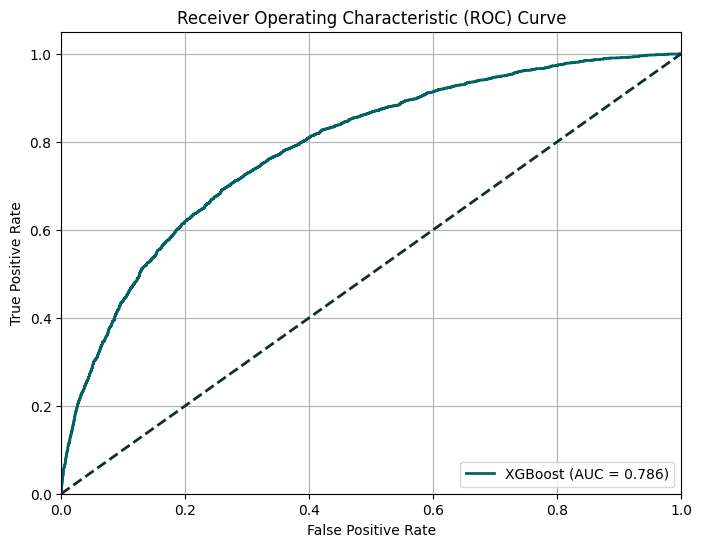

np.float64(0.7855182664507031)

In [82]:
y_probs = xgb_model.predict_proba(transformed_x_val)[:, 1]
plot_roc_curve(y_val, y_probs, model_name='XGBoost')

As expected, adding additional information improves the model's performance (0,786 vs. 0,77 AUC without supplementary data). However, the improvement is not significant enough to achieve an accuracy higher than 0,92.

#### Feature importance

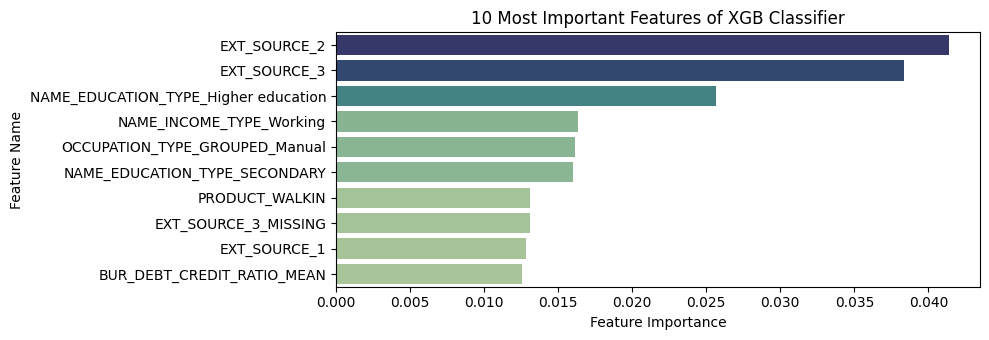

In [83]:
feature_names = X_processed.drop(choosing_params(building_param), axis=1).columns
mylist = plot_feature_importance(xgb_model, feature_names, model_name="XGB Classifier")

External sources are still the most important features in the model. Also majority of most imporant features are from the main application dataset. 

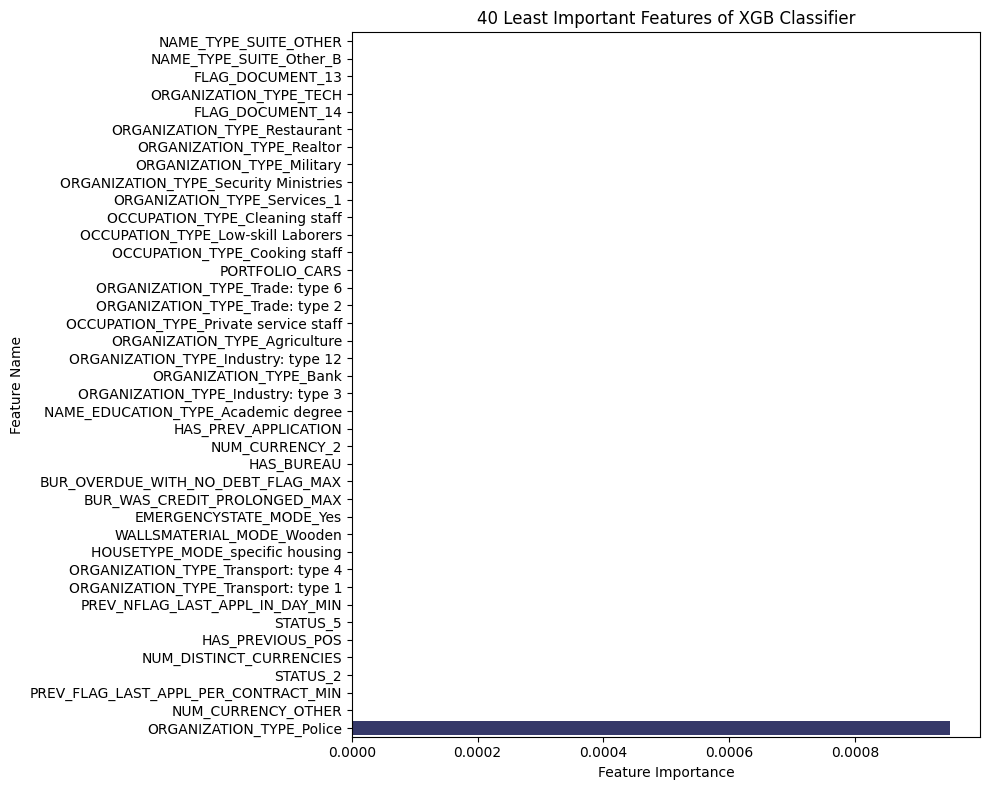

In [84]:
mylist = plot_feature_importance(xgb_model, feature_names, order="bottom", n=40, model_name="XGB Classifier")

Since there are a lot more features, there are a lot more zero imporance features as well. They won't be removed in further testing.

### Version 2

#### Optuna Study

For version 2 of the model, balancing will be removed since it does not improve performance. Parameter values will be adjusted based on the results of the previous version. The values for gamma, learning rate, n_estimators, reg_lambda, subsample, and outlier_factor were adjusted.

In [85]:
def objective(trial):

    impute_strategy = trial.suggest_categorical("impute_strategy", ["mean", "median", "most_frequent", "constant_-999"])
    building_param = trial.suggest_categorical('building_param', ['mean', 'median', 'mode'])
    outlier_factor = trial.suggest_float("outlier_factor", 2, 4.0)

    params = {
        "n_estimators": trial.suggest_int("n_estimators", 700, 1800),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "learning_rate": trial.suggest_float("learning_rate", 0.015, 0.05, log=True),
        "subsample": trial.suggest_float("subsample", 0.75, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "gamma": trial.suggest_float("gamma", 1, 3),
        "reg_alpha": trial.suggest_float("reg_alpha", 0, 10),
        "reg_lambda": trial.suggest_float("reg_lambda", 5, 8),
    }

    # Imputer and model
    if impute_strategy.startswith("constant_"):
        fill_value = float(impute_strategy.split("_")[1])
        imputer = SimpleImputer(strategy="constant", fill_value=fill_value)
    else:
        imputer = SimpleImputer(strategy=impute_strategy)

    clf = xgb.XGBClassifier(**params, random_state=8)

    pipeline = Pipeline(
        [
            ('building_param', FunctionTransformer(lambda df: df.drop(choosing_params(building_param), axis=1))),
            ('remove_outliers', FunctionTransformer(lambda df: remove_outliers_iqr(df, factor=outlier_factor))),
            ('imputer', imputer),
            ('clf', clf),
        ]
    )

    # Evaluate with cross-validation

    scores = cross_val_score(pipeline, X_processed, y_train, cv=3, scoring='roc_auc')
    return np.mean(scores)


study_xgb_2 = optuna.create_study(direction="maximize", sampler=optuna.samplers.RandomSampler(seed=8))
study_xgb_2.optimize(objective, n_trials=70)

best_result = study_xgb_2.best_trial
print("Best trial:")
print(best_result)

[I 2025-11-10 03:07:27,096] A new study created in memory with name: no-name-c4f4edcb-afc8-4427-a103-25fa73c837f0
[I 2025-11-10 03:13:48,695] Trial 0 finished with value: 0.7813065079814497 and parameters: {'impute_strategy': 'median', 'building_param': 'mode', 'outlier_factor': 2.8047027200747294, 'n_estimators': 1275, 'max_depth': 7, 'learning_rate': 0.02927354749270589, 'subsample': 0.8858465043856351, 'colsample_bytree': 0.8804477878014645, 'gamma': 2.4247491481641825, 'reg_alpha': 6.196820961034396, 'reg_lambda': 6.278275311428576}. Best is trial 0 with value: 0.7813065079814497.
[I 2025-11-10 03:17:42,212] Trial 1 finished with value: 0.7795711277692859 and parameters: {'impute_strategy': 'median', 'building_param': 'median', 'outlier_factor': 2.6442615864083585, 'n_estimators': 778, 'max_depth': 5, 'learning_rate': 0.02409431531259863, 'subsample': 0.9740362512201588, 'colsample_bytree': 0.6727308059989335, 'gamma': 2.969498874570543, 'reg_alpha': 0.287320489632954, 'reg_lambda'

Best trial:
FrozenTrial(number=67, state=1, values=[0.7837976738934419], datetime_start=datetime.datetime(2025, 11, 10, 10, 52, 35, 788479), datetime_complete=datetime.datetime(2025, 11, 10, 10, 59, 22, 406540), params={'impute_strategy': 'mean', 'building_param': 'mean', 'outlier_factor': 3.1281568855123973, 'n_estimators': 1309, 'max_depth': 6, 'learning_rate': 0.01848372679985372, 'subsample': 0.7544250580296137, 'colsample_bytree': 0.523264956618508, 'gamma': 1.0504598960432396, 'reg_alpha': 2.760255187247668, 'reg_lambda': 7.39968009856182}, user_attrs={}, system_attrs={}, intermediate_values={}, distributions={'impute_strategy': CategoricalDistribution(choices=('mean', 'median', 'most_frequent', 'constant_-999')), 'building_param': CategoricalDistribution(choices=('mean', 'median', 'mode')), 'outlier_factor': FloatDistribution(high=4.0, log=False, low=2.0, step=None), 'n_estimators': IntDistribution(high=1800, log=False, low=700, step=1), 'max_depth': IntDistribution(high=12, log

In [86]:
best_score = study_xgb_2.best_value
print(f"best roc_auc: {best_score:.3f}")

best roc_auc: 0.784


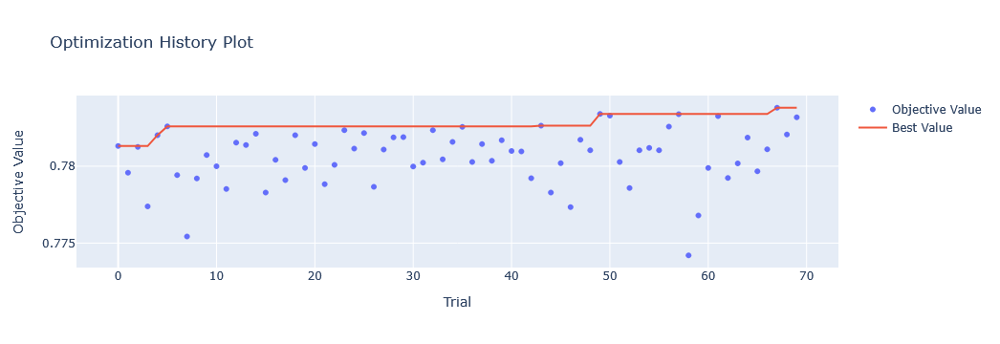

In [87]:
optuna.visualization.plot_optimization_history(study_xgb_2)

Best trial 67th one in the Optuna study.

#### Hyperparameters

In [88]:
optuna.visualization.plot_slice(study_xgb_2, params=['outlier_factor', 'building_param', 'impute_strategy'])

It seems that that for building_param, means were the best option, but there were also few outliers which did not perform well. For impute strategy mean and constant placeholder value (-999) performed the best. Best outcomes for outlier_factor is around 3,1.

In [89]:
optuna.visualization.plot_slice(study_xgb_2, params=['n_estimators', 'max_depth', 'learning_rate', 'subsample'])

For max_depth best values seems to be around 5-6. There are no clear tendiences for other hyperparameters.

In [90]:
optuna.visualization.plot_slice(study_xgb_2, params=['colsample_bytree', 'gamma', 'reg_alpha', 'reg_lambda'])

No clear tendencies.

In [91]:
optuna.visualization.plot_param_importances(study_xgb_2)

Now outlier_factor value is the most important hyperparameter.

#### Best parameters and confusion matrix

In [92]:
best_par = study_xgb_2.best_params
impute_strategy = best_par['impute_strategy']
del best_par['impute_strategy']
building_param = best_par['building_param']
del best_par['building_param']
outlier_factor = best_par['outlier_factor']
del best_par['outlier_factor']

study_xgb_2.best_params

{'impute_strategy': 'mean',
 'building_param': 'mean',
 'outlier_factor': 3.1281568855123973,
 'n_estimators': 1309,
 'max_depth': 6,
 'learning_rate': 0.01848372679985372,
 'subsample': 0.7544250580296137,
 'colsample_bytree': 0.523264956618508,
 'gamma': 1.0504598960432396,
 'reg_alpha': 2.760255187247668,
 'reg_lambda': 7.39968009856182}

In [93]:
if impute_strategy.startswith("constant_"):
    fill_value = float(impute_strategy.split("_")[1])
    imputer = SimpleImputer(strategy="constant", fill_value=fill_value)
else:
    imputer = SimpleImputer(strategy=impute_strategy)

xgb_model = Pipeline(
    [
        ('drop_columns', FunctionTransformer(lambda df: df.drop(choosing_params(building_param), axis=1))),
        ('remove_outliers', FunctionTransformer(lambda df: remove_outliers_iqr(df, factor=outlier_factor))),
        ('imput', imputer),
        ("clf", xgb.XGBClassifier(**best_par, random_state=8)),
    ]
)
xgb_model.fit(X_processed, y_train)

yhat = xgb_model.predict(transformed_x_val)
prediction = list(map(round, yhat))

cm = confusion_matrix(y_val, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y_val, prediction))

Confusion Matrix : 
 [[28179    90]
 [ 2370   112]]
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     28269
           1       0.55      0.05      0.08      2482

    accuracy                           0.92     30751
   macro avg       0.74      0.52      0.52     30751
weighted avg       0.89      0.92      0.89     30751



Version 2 of the model has slightly better recall and slightly worse precision compared to version 1.

#### Receiver Operating Characteristic (ROC) Curve

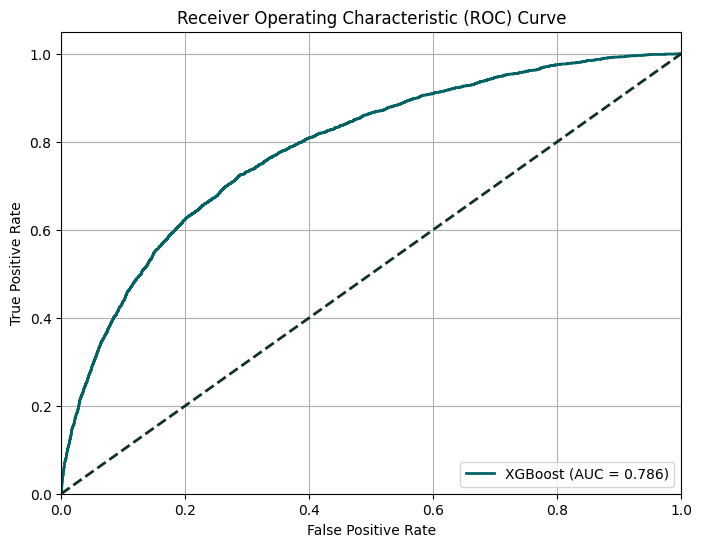

np.float64(0.7855648005125389)

In [94]:
y_probs = xgb_model.predict_proba(transformed_x_val)[:, 1]
plot_roc_curve(y_val, y_probs, model_name='XGBoost')

Version 2 performs similarly to the version 1 as both have same AUC (0,786).

#### Feature importance

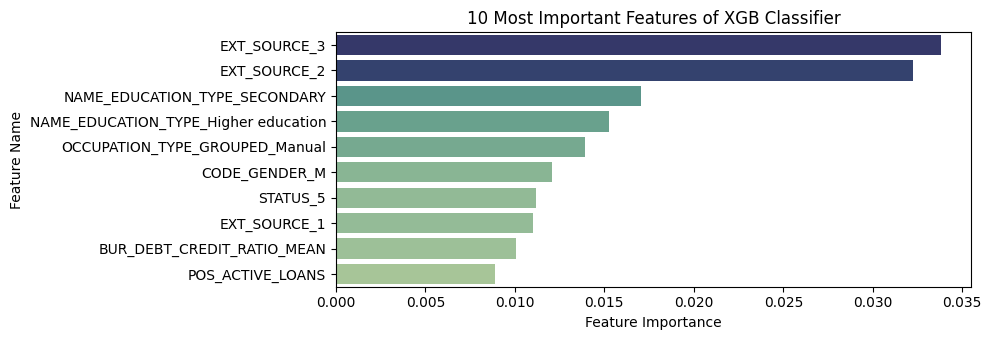

In [95]:
feature_names = X_processed.drop(choosing_params(building_param), axis=1).columns
mylist = plot_feature_importance(xgb_model, feature_names, model_name="XGB Classifier")

External sources remain the most important features in the model. The majority of the most important features also come from the main application dataset. Feature importances have slightly changed between version 1 and version 2 — for example, in version 2 the most important feature is External Source 3, while in version 1 it was External Source 2. Most of the top 10 features remained the same (7 out of 10), although some differences are present; for instance, in version 1 the feature CODE_GENDER_M was not among the top 10.

These results indicate that while the core structure of the model remains stable, minor shifts in feature importance suggest that changes in preprocessing or parameter tuning slightly affect how the model prioritizes input information.

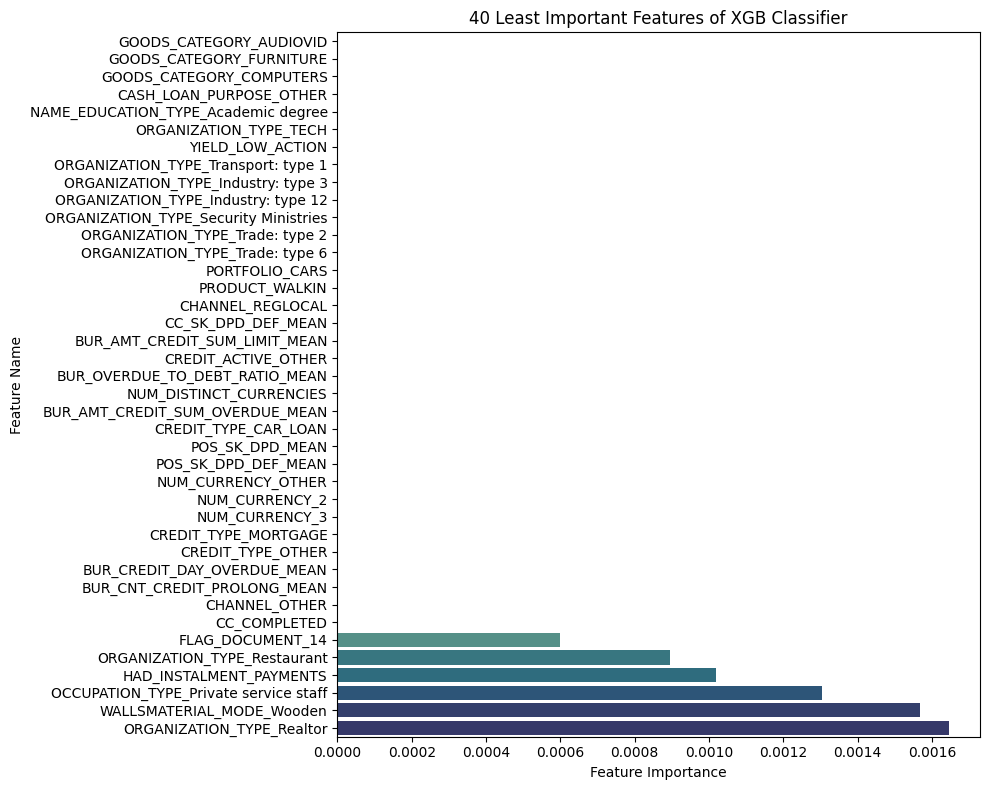

In [96]:
mylist = plot_feature_importance(xgb_model, feature_names, n=40, order="bottom", model_name="XGB Classifier")

Feature importances differ between version 2 and version 1. Version 2 has 34 non-important features, while version 1 has 39. Not all of the unimportant features overlap; for example, FLAG_DOCUMENT_14 has some importance in determining the target in version 2, whereas in version 1 it was not important. This suggests that the updated model (version 2) evaluates certain features differently, due to changes in data preprocessing, feature selection, or parameter tuning.

### Version 3

#### Optuna Study

Max_depth and outlier_factor will be adjusted. Learning_rate, subsample, n_estimators, colsample_bytree will be slightly narrowed down. Median is going to be removed from impute strateties.

In [97]:
def objective(trial):

    impute_strategy = trial.suggest_categorical("impute_strategy", ["mean", "most_frequent", "constant_-999"])
    building_param = trial.suggest_categorical('building_param', ['mean', 'median', 'mode'])
    outlier_factor = trial.suggest_float("outlier_factor", 3, 4.0)

    params = {
        "n_estimators": trial.suggest_int("n_estimators", 700, 1600),
        "max_depth": trial.suggest_int("max_depth", 4, 6),
        "learning_rate": trial.suggest_float("learning_rate", 0.016, 0.04, log=True),
        "subsample": trial.suggest_float("subsample", 0.72, 0.85),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.45, 0.8),
        "gamma": trial.suggest_float("gamma", 1, 3),
        "reg_alpha": trial.suggest_float("reg_alpha", 0, 10),
        "reg_lambda": trial.suggest_float("reg_lambda", 5, 8),
    }

    # Imputer and model
    if impute_strategy.startswith("constant_"):
        fill_value = float(impute_strategy.split("_")[1])
        imputer = SimpleImputer(strategy="constant", fill_value=fill_value)
    else:
        imputer = SimpleImputer(strategy=impute_strategy)

    clf = xgb.XGBClassifier(**params, random_state=8)

    pipeline = Pipeline(
        [
            ('building_param', FunctionTransformer(lambda df: df.drop(choosing_params(building_param), axis=1))),
            ('remove_outliers', FunctionTransformer(lambda df: remove_outliers_iqr(df, factor=outlier_factor))),
            ('imputer', imputer),
            ('clf', clf),
        ]
    )

    # Evaluate with cross-validation

    scores = cross_val_score(pipeline, X_processed, y_train, cv=3, scoring='roc_auc')
    return np.mean(scores)


study_xgb_3 = optuna.create_study(direction="maximize", sampler=optuna.samplers.RandomSampler(seed=8))
study_xgb_3.optimize(objective, n_trials=40)

best_result = study_xgb_3.best_trial
print("Best trial:")
print(best_result)

[I 2025-11-10 11:17:51,301] A new study created in memory with name: no-name-5c38784a-b3d1-4e78-a3c3-a53384b3c554
[I 2025-11-10 11:23:02,511] Trial 0 finished with value: 0.7829480933735385 and parameters: {'impute_strategy': 'most_frequent', 'building_param': 'mean', 'outlier_factor': 3.4304688182924905, 'n_estimators': 1062, 'max_depth': 5, 'learning_rate': 0.024802257839399808, 'subsample': 0.7921963415969029, 'colsample_bytree': 0.6401851061398891, 'gamma': 2.521791151205858, 'reg_alpha': 7.123745740820913, 'reg_lambda': 6.859046288310319}. Best is trial 0 with value: 0.7829480933735385.
[I 2025-11-10 11:26:52,493] Trial 1 finished with value: 0.7777889434962013 and parameters: {'impute_strategy': 'constant_-999', 'building_param': 'mean', 'outlier_factor': 3.9828705465534338, 'n_estimators': 815, 'max_depth': 4, 'learning_rate': 0.017074617318027854, 'subsample': 0.7492200920658458, 'colsample_bytree': 0.5877722202302618, 'gamma': 2.7922900097612704, 'reg_alpha': 3.454616119978670

Best trial:
FrozenTrial(number=36, state=1, values=[0.7844649661139291], datetime_start=datetime.datetime(2025, 11, 10, 14, 40, 7, 955009), datetime_complete=datetime.datetime(2025, 11, 10, 14, 46, 9, 485128), params={'impute_strategy': 'constant_-999', 'building_param': 'mode', 'outlier_factor': 3.9370862454288305, 'n_estimators': 1418, 'max_depth': 4, 'learning_rate': 0.030746239125602013, 'subsample': 0.7643290179213021, 'colsample_bytree': 0.6815390815936563, 'gamma': 2.0367975042344253, 'reg_alpha': 6.93922453608193, 'reg_lambda': 5.585084719613018}, user_attrs={}, system_attrs={}, intermediate_values={}, distributions={'impute_strategy': CategoricalDistribution(choices=('mean', 'most_frequent', 'constant_-999')), 'building_param': CategoricalDistribution(choices=('mean', 'median', 'mode')), 'outlier_factor': FloatDistribution(high=4.0, log=False, low=3.0, step=None), 'n_estimators': IntDistribution(high=1600, log=False, low=700, step=1), 'max_depth': IntDistribution(high=6, log=F

In [98]:
best_score = study_xgb_3.best_value
print(f"best roc_auc: {best_score:.3f}")

best roc_auc: 0.784


In [99]:
optuna.visualization.plot_optimization_history(study_xgb_3)

#### Hyperparameters

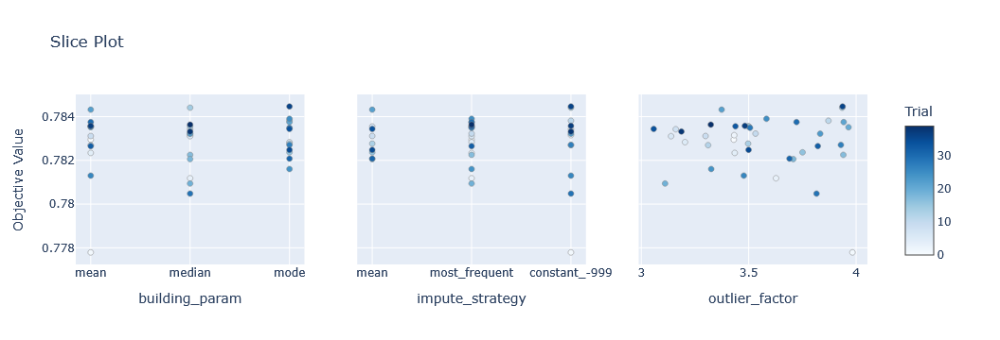

In [100]:
optuna.visualization.plot_slice(study_xgb_3, params=['outlier_factor', "impute_strategy", 'building_param'])

Contstant value for impute strategy seems to be performing the best.

In [101]:
optuna.visualization.plot_slice(study_xgb_3, params=['n_estimators', 'max_depth', 'learning_rate', 'subsample'])

Highest and lowest learning_rate values perform worse. A max_depth of 4 appears to perform the best, with optimal results achieved when using around 1400 n_estimators. No clear trends were observed in subsample .

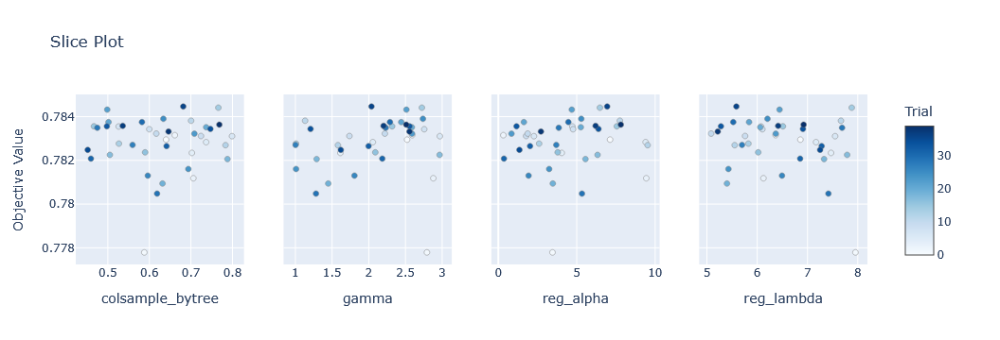

In [102]:
optuna.visualization.plot_slice(study_xgb_3, params=['colsample_bytree', 'gamma', 'reg_alpha', 'reg_lambda'])

There is a trend indicating that the model performs better when gamma is around 2,5 and reg_alpha is around 7.

In [103]:
optuna.visualization.plot_param_importances(study_xgb_3)

The most important hyperparameter in this part of tuning was n_estimators.

#### Best parameters and confusion matrix

In [104]:
best_par = study_xgb_3.best_params
impute_strategy = best_par['impute_strategy']
del best_par['impute_strategy']
building_param = best_par['building_param']
del best_par['building_param']
outlier_factor = best_par['outlier_factor']
del best_par['outlier_factor']

study_xgb_3.best_params

{'impute_strategy': 'constant_-999',
 'building_param': 'mode',
 'outlier_factor': 3.9370862454288305,
 'n_estimators': 1418,
 'max_depth': 4,
 'learning_rate': 0.030746239125602013,
 'subsample': 0.7643290179213021,
 'colsample_bytree': 0.6815390815936563,
 'gamma': 2.0367975042344253,
 'reg_alpha': 6.93922453608193,
 'reg_lambda': 5.585084719613018}

In [105]:
if impute_strategy.startswith("constant_"):
    fill_value = float(impute_strategy.split("_")[1])
    imputer = SimpleImputer(strategy="constant", fill_value=fill_value)
else:
    imputer = SimpleImputer(strategy=impute_strategy)

xgb_model = Pipeline(
    [
        ('drop_columns', FunctionTransformer(lambda df: df.drop(choosing_params(building_param), axis=1))),
        ('remove_outliers', FunctionTransformer(lambda df: remove_outliers_iqr(df, factor=outlier_factor))),
        ('imput', imputer),
        ("clf", xgb.XGBClassifier(**best_par, random_state=8)),
    ]
)
xgb_model.fit(X_processed, y_train)

yhat = xgb_model.predict(transformed_x_val)
prediction = list(map(round, yhat))

cm = confusion_matrix(y_val, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y_val, prediction))

Confusion Matrix : 
 [[28183    86]
 [ 2371   111]]
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     28269
           1       0.56      0.04      0.08      2482

    accuracy                           0.92     30751
   macro avg       0.74      0.52      0.52     30751
weighted avg       0.89      0.92      0.89     30751



#### Receiver Operating Characteristic (ROC) Curve

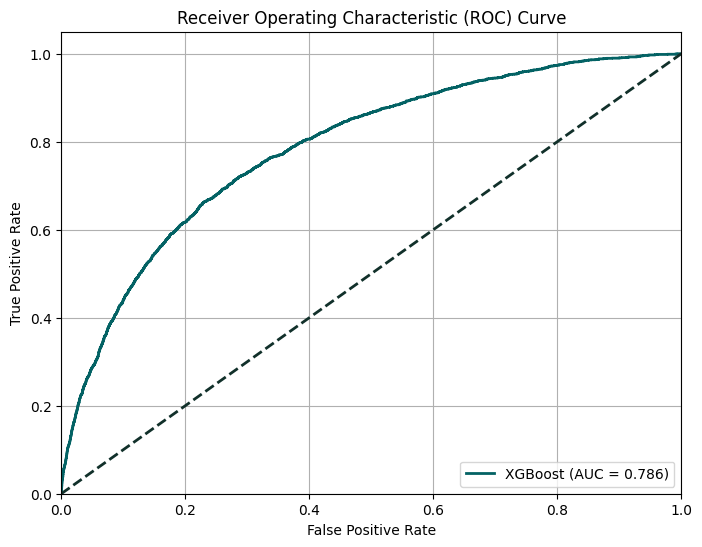

np.float64(0.7855558428837902)

In [106]:
y_probs = xgb_model.predict_proba(transformed_x_val)[:, 1]
plot_roc_curve(y_val, y_probs, model_name='XGBoost')

The model performs similarly to versions 1 and 2 (all have 0.786 AUC).

#### Feature importance

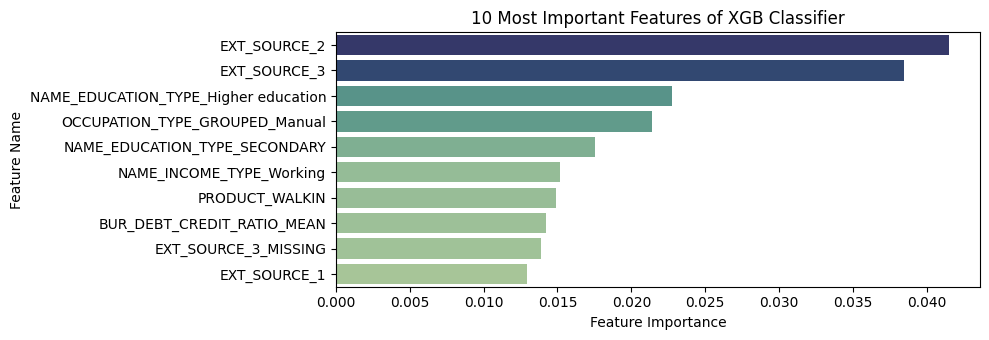

In [107]:
feature_names = X_processed.drop(choosing_params(building_param), axis=1).columns
mylist = plot_feature_importance(xgb_model, feature_names, model_name="XGB Classifier")

Similar trends can be seen here like in versions 1 and 2. External sources of information are still most important features.

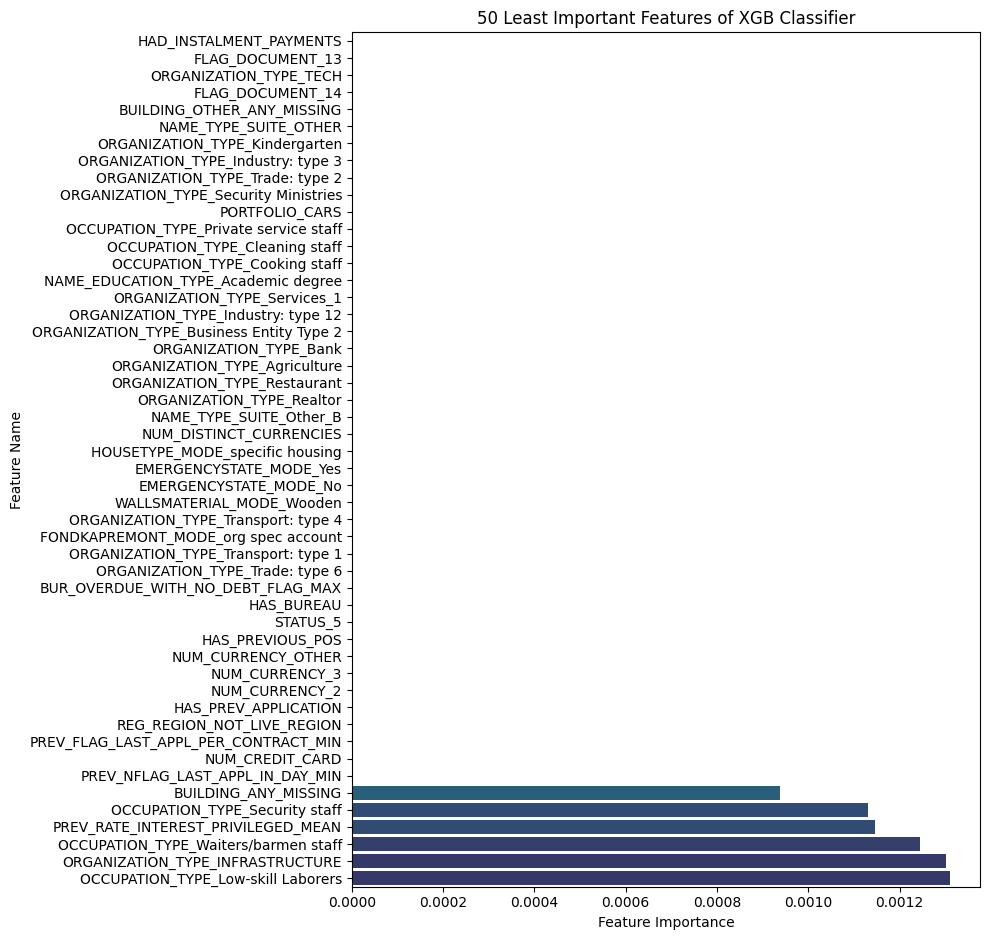

In [108]:
mylist = plot_feature_importance(xgb_model, feature_names, order="bottom", n=50, model_name="XGB Classifier")

There are 36 features with no importance in this version of the model. Feature importances vary slightly from version to version, reflecting how changes in parameter tuning can influence the model's assessment of which variables contribute most to prediction accuracy.

### Version 4

#### Optuna Study

Learning_rate, max_depth and n_estimators ranges were adjusted.  It seems that the best impute strategy is a constant placeholder for a missing value, therefore it will be used from now on. Gamma adjusted slightly.

In [109]:
def objective(trial):

    building_param = trial.suggest_categorical('building_param', ['mean', 'median', 'mode'])
    outlier_factor = trial.suggest_float("outlier_factor", 3, 4.0)

    params = {
        "n_estimators": trial.suggest_int("n_estimators", 1350, 1500),
        "max_depth": trial.suggest_int("max_depth", 4, 5),
        "learning_rate": trial.suggest_float("learning_rate", 0.028, 0.033, log=True),
        "subsample": trial.suggest_float("subsample", 0.72, 0.85),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.45, 0.8),
        "gamma": trial.suggest_float("gamma", 1, 2.8),
        "reg_alpha": trial.suggest_float("reg_alpha", 0, 10),
        "reg_lambda": trial.suggest_float("reg_lambda", 5, 8),
    }

    # Imputer and model

    imputer = SimpleImputer(strategy="constant", fill_value=-999)

    clf = xgb.XGBClassifier(**params, random_state=8)

    pipeline = Pipeline(
        [
            ('building_param', FunctionTransformer(lambda df: df.drop(choosing_params(building_param), axis=1))),
            ('remove_outliers', FunctionTransformer(lambda df: remove_outliers_iqr(df, factor=outlier_factor))),
            ('imputer', imputer),
            ('clf', clf),
        ]
    )

    # Evaluate with cross-validation

    scores = cross_val_score(pipeline, X_processed, y_train, cv=3, scoring='roc_auc')
    return np.mean(scores)


study_xgb_4 = optuna.create_study(direction="maximize", sampler=optuna.samplers.RandomSampler(seed=8))
study_xgb_4.optimize(objective, n_trials=75)

best_result = study_xgb_4.best_trial
print("Best trial:")
print(best_result)

[I 2025-11-10 15:06:29,265] A new study created in memory with name: no-name-c8539ff5-ee98-42de-9b86-73a45e602d09
[I 2025-11-10 15:12:19,873] Trial 0 finished with value: 0.7841260349086633 and parameters: {'building_param': 'median', 'outlier_factor': 3.530855691555599, 'n_estimators': 1385, 'max_depth': 4, 'learning_rate': 0.03005207921716126, 'subsample': 0.7723056768048574, 'colsample_bytree': 0.6329361349733994, 'gamma': 1.8611052324443242, 'reg_alpha': 5.553564738223304, 'reg_lambda': 6.630158052627621}. Best is trial 0 with value: 0.7841260349086633.
[I 2025-11-10 15:18:42,725] Trial 1 finished with value: 0.7837088664853132 and parameters: {'building_param': 'mean', 'outlier_factor': 3.426091770476192, 'n_estimators': 1393, 'max_depth': 5, 'learning_rate': 0.029578407071501014, 'subsample': 0.7484441379065776, 'colsample_bytree': 0.473032935725524, 'gamma': 2.7691669837961808, 'reg_alpha': 1.2785571292503184, 'reg_lambda': 5.966392379612538}. Best is trial 0 with value: 0.78412

Best trial:
FrozenTrial(number=70, state=1, values=[0.7849604822032349], datetime_start=datetime.datetime(2025, 11, 10, 23, 15, 10, 681553), datetime_complete=datetime.datetime(2025, 11, 10, 23, 22, 8, 445969), params={'building_param': 'mean', 'outlier_factor': 3.9007952388462206, 'n_estimators': 1496, 'max_depth': 5, 'learning_rate': 0.029480210787887613, 'subsample': 0.8492049841344275, 'colsample_bytree': 0.526024495680035, 'gamma': 2.0804856673973897, 'reg_alpha': 3.9485835981310045, 'reg_lambda': 6.982645164444177}, user_attrs={}, system_attrs={}, intermediate_values={}, distributions={'building_param': CategoricalDistribution(choices=('mean', 'median', 'mode')), 'outlier_factor': FloatDistribution(high=4.0, log=False, low=3.0, step=None), 'n_estimators': IntDistribution(high=1500, log=False, low=1350, step=1), 'max_depth': IntDistribution(high=5, log=False, low=4, step=1), 'learning_rate': FloatDistribution(high=0.033, log=True, low=0.028, step=None), 'subsample': FloatDistribut

In [110]:
best_score = study_xgb_4.best_value
print(f"best roc_auc: {best_score:.3f}")

best roc_auc: 0.785


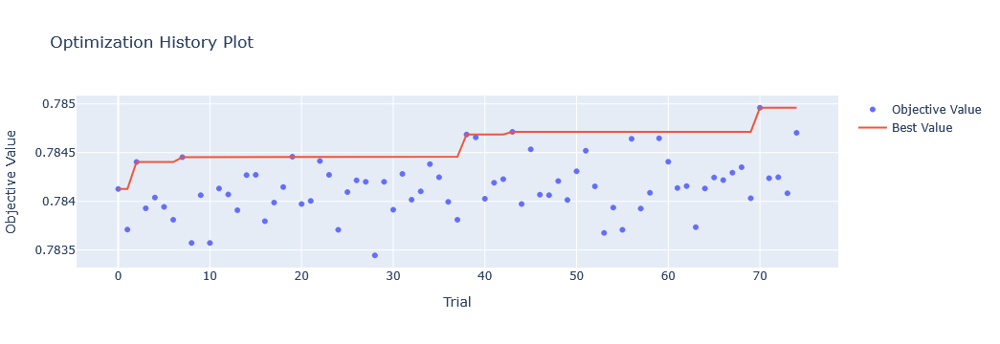

In [111]:
optuna.visualization.plot_optimization_history(study_xgb_4)

Best trial in optuna study was 70th.

#### Hyperparameters

In [112]:
optuna.visualization.plot_slice(study_xgb_4, params=['outlier_factor', 'building_param'])

For builing_param mean seems to be the best. Also higher values for outlier_factor seem to be performing better.

In [113]:
optuna.visualization.plot_slice(study_xgb_4, params=['n_estimators', 'max_depth', 'learning_rate', 'subsample'])

The trend can be seen that the best learning rate is around 0,0295. Max_depth of 5 performs better. Higher values for subsample and n_estimaors also perform better. 

In [114]:
optuna.visualization.plot_slice(study_xgb_4, params=['colsample_bytree', 'gamma', 'reg_alpha', 'reg_lambda'])

There is a trend indicating that models with colsample_bytree values around 0,52, gamma around 2, and reg_alpha around 4.5 perform better. There are no clear trends for reg_lambda, although the best performance was observed at a value of 7.

In [115]:
optuna.visualization.plot_param_importances(study_xgb_4)

The most important hyperparameter was outlier_factor. In comparison max_deph almost didn't make a difference for models performace.

#### Best parameters and confusion matrix

In [116]:
best_par = study_xgb_4.best_params
building_param = best_par['building_param']
del best_par['building_param']
outlier_factor = best_par['outlier_factor']
del best_par['outlier_factor']

study_xgb_4.best_params

{'building_param': 'mean',
 'outlier_factor': 3.9007952388462206,
 'n_estimators': 1496,
 'max_depth': 5,
 'learning_rate': 0.029480210787887613,
 'subsample': 0.8492049841344275,
 'colsample_bytree': 0.526024495680035,
 'gamma': 2.0804856673973897,
 'reg_alpha': 3.9485835981310045,
 'reg_lambda': 6.982645164444177}

In [117]:
imputer = SimpleImputer(strategy="constant", fill_value=-999)

xgb_model = Pipeline(
    [
        ('drop_columns', FunctionTransformer(lambda df: df.drop(choosing_params(building_param), axis=1))),
        ('remove_outliers', FunctionTransformer(lambda df: remove_outliers_iqr(df, factor=outlier_factor))),
        ('imput', imputer),
        ("clf", xgb.XGBClassifier(**best_par, random_state=8)),
    ]
)
xgb_model.fit(X_processed, y_train)

yhat = xgb_model.predict(transformed_x_val)
prediction = list(map(round, yhat))

cm = confusion_matrix(y_val, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y_val, prediction))

Confusion Matrix : 
 [[28173    96]
 [ 2359   123]]
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     28269
           1       0.56      0.05      0.09      2482

    accuracy                           0.92     30751
   macro avg       0.74      0.52      0.52     30751
weighted avg       0.89      0.92      0.89     30751



#### Receiver Operating Characteristic (ROC) Curve

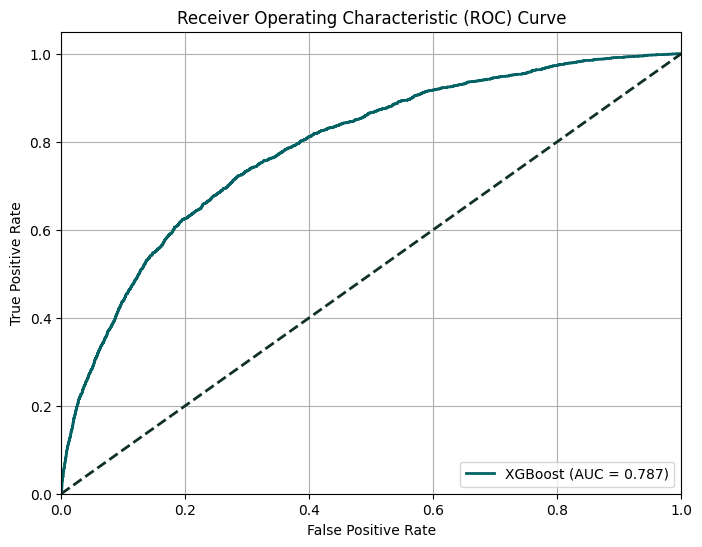

np.float64(0.7868601292139016)

In [118]:
y_probs = xgb_model.predict_proba(transformed_x_val)[:, 1]
plot_roc_curve(y_val, y_probs, model_name='XGBoost')

This version of the model has a slightly higher AUC than the previous versions (0.787 compared to 0.786). However, the accuracy remains at 92%.

#### Feature importance

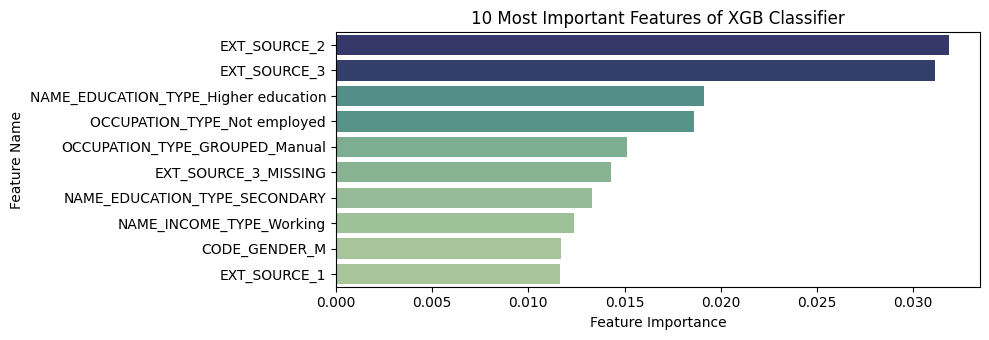

In [119]:
feature_names = X_processed.drop(choosing_params(building_param), axis=1).columns
mylist = plot_feature_importance(xgb_model, feature_names, model_name="XGB Classifier")

Similar trends can be seen here like in versions 1, 2 and 3. External sources of information are still most important features.

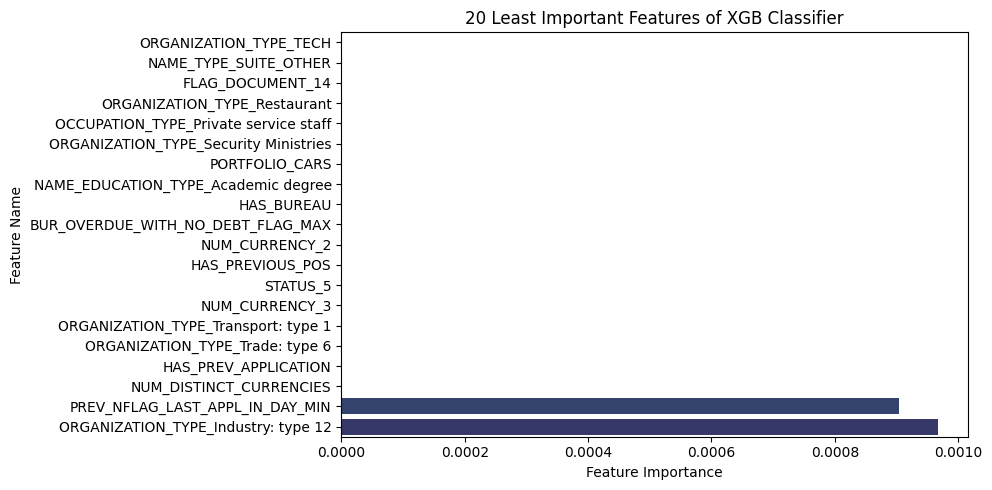

In [120]:
mylist = plot_feature_importance(xgb_model, feature_names, order="bottom", n=20, model_name="XGB Classifier")

This version of model has the least amount of not important features – only 18. Differences between model versions are due to that they evaluate certain features differently.

## LGBMClassifier

### Version 1

#### Optuna Study

LGBM classifier using all of the data (main application data and supplementary data). Dimention reduction methods will not be used, as they reduce AUC ROC score significantly. 

In [121]:
def objective(trial):

    impute_strategy = trial.suggest_categorical("impute_strategy", ["mean", "median", "most_frequent", "constant_-999"])
    building_param = trial.suggest_categorical('building_param', ['mean', 'median', 'mode'])
    outlier_factor = trial.suggest_float("outlier_factor", 1.5, 4.0)

    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 2000),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.3, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 7, 127),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
        "scale_pos_weight": trial.suggest_categorical("scale_pos_weight", [ratio, 1]),
    }

    # Imputer and model
    if impute_strategy.startswith("constant_"):
        fill_value = float(impute_strategy.split("_")[1])
        imputer = SimpleImputer(strategy="constant", fill_value=fill_value)
    else:
        imputer = SimpleImputer(strategy=impute_strategy)

    clf = LGBMClassifier(**params, random_state=8)

    pipeline = Pipeline(
        [
            ('building_param', FunctionTransformer(lambda df: df.drop(choosing_params(building_param), axis=1))),
            ('remove_outliers', FunctionTransformer(lambda df: remove_outliers_iqr(df, factor=outlier_factor))),
            ('imputer', imputer),
            ('clf', clf),
        ]
    )

    # Evaluate with cross-validation
    scores = cross_val_score(pipeline, X_processed, y_train, cv=3, scoring='roc_auc')
    return np.mean(scores)


study_lgbm_1 = optuna.create_study(direction="maximize", sampler=optuna.samplers.RandomSampler(seed=8))
study_lgbm_1.optimize(objective, n_trials=30)

best_result = study_lgbm_1.best_trial
print("Best trial:")
print(best_result)

[I 2025-11-10 23:51:12,143] A new study created in memory with name: no-name-71a7c1b3-6c04-4c38-87be-c95afc2f1ddf


[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.116817 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 19329
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 274
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.270180 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 19320
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 275
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.4

[I 2025-11-10 23:55:07,697] Trial 0 finished with value: 0.7705553861434997 and parameters: {'impute_strategy': 'median', 'building_param': 'mode', 'outlier_factor': 2.505878400093412, 'n_estimators': 1093, 'learning_rate': 0.03545054973489931, 'num_leaves': 74, 'subsample': 0.7716930087712701, 'colsample_bytree': 0.8804477878014645, 'reg_alpha': 0.02578523933004178, 'reg_lambda': 0.0037769293830248463, 'scale_pos_weight': np.float64(0.08781859667120646)}. Best is trial 0 with value: 0.7705553861434997.


[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.107365 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 19692
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 274
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.307230 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 19650
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 275
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.4

[I 2025-11-10 23:58:07,780] Trial 1 finished with value: 0.776104636880425 and parameters: {'impute_strategy': 'mean', 'building_param': 'mean', 'outlier_factor': 1.6773571118754969, 'n_estimators': 527, 'learning_rate': 0.02505603924087917, 'num_leaves': 115, 'subsample': 0.6727308059989335, 'colsample_bytree': 0.9923747186426357, 'reg_alpha': 1.813796003613881e-08, 'reg_lambda': 1.4627248055970364e-05, 'scale_pos_weight': 1}. Best is trial 1 with value: 0.776104636880425.


[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.121313 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 20074
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 274
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.121365 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 20028
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 275
[LightGBM]

... (52 outputs left out)

[I 2025-11-11 01:48:09,372] Trial 28 finished with value: 0.773510633590995 and parameters: {'impute_strategy': 'constant_-999', 'building_param': 'median', 'outlier_factor': 2.6913516132865833, 'n_estimators': 662, 'learning_rate': 0.03278965302252963, 'num_leaves': 106, 'subsample': 0.6858899963842484, 'colsample_bytree': 0.5770946689972087, 'reg_alpha': 0.01405266511081332, 'reg_lambda': 0.0026347620008998047, 'scale_pos_weight': np.float64(0.08781859667120646)}. Best is trial 21 with value: 0.7801223095833568.


[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.310051 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 19514
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 300
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.318649 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 19516
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 300
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[Lig

[I 2025-11-11 01:52:42,023] Trial 29 finished with value: 0.7734387349138051 and parameters: {'impute_strategy': 'constant_-999', 'building_param': 'median', 'outlier_factor': 2.3954215431550576, 'n_estimators': 933, 'learning_rate': 0.04453654719226786, 'num_leaves': 127, 'subsample': 0.6620813961450908, 'colsample_bytree': 0.5901928327724709, 'reg_alpha': 1.6817790759020818e-07, 'reg_lambda': 0.09971890644715549, 'scale_pos_weight': np.float64(0.08781859667120646)}. Best is trial 21 with value: 0.7801223095833568.


Best trial:
FrozenTrial(number=21, state=1, values=[0.7801223095833568], datetime_start=datetime.datetime(2025, 11, 11, 1, 15, 26, 642375), datetime_complete=datetime.datetime(2025, 11, 11, 1, 23, 50, 989336), params={'impute_strategy': 'constant_-999', 'building_param': 'mean', 'outlier_factor': 1.7808380985065149, 'n_estimators': 1962, 'learning_rate': 0.018950512664753998, 'num_leaves': 28, 'subsample': 0.8351076941720041, 'colsample_bytree': 0.5032976216069124, 'reg_alpha': 6.251651454845306e-05, 'reg_lambda': 0.018528329976561442, 'scale_pos_weight': 1}, user_attrs={}, system_attrs={}, intermediate_values={}, distributions={'impute_strategy': CategoricalDistribution(choices=('mean', 'median', 'most_frequent', 'constant_-999')), 'building_param': CategoricalDistribution(choices=('mean', 'median', 'mode')), 'outlier_factor': FloatDistribution(high=4.0, log=False, low=1.5, step=None), 'n_estimators': IntDistribution(high=2000, log=False, low=100, step=1), 'learning_rate': FloatDistri

In [122]:
best_score = study_lgbm_1.best_value
print(f"best roc_auc: {best_score:.3f}")

best roc_auc: 0.780


In [123]:
optuna.visualization.plot_optimization_history(study_lgbm_1)

The best trial was 21st.

#### Hyperparameters

In [124]:
optuna.visualization.plot_slice(study_lgbm_1, params=['outlier_factor', 'building_param', 'impute_strategy'])

There are some trends of building_param median performing worse. Also it seems that constant value performs slightly better for impute_strategy.

In [125]:
optuna.visualization.plot_slice(study_lgbm_1, params=['n_estimators', "learning_rate", "num_leaves", 'subsample'])

Very clear trend can be seen in learning_rate – the best learning rate is around 0,02. No clear trends in other hyperparameters.

In [126]:
optuna.visualization.plot_slice(
    study_lgbm_1, params=["colsample_bytree", "reg_alpha", "reg_lambda", "scale_pos_weight"]
)

There is a slight trend that the model performs better without balancing (scale_pos_weight of 1 slightly better values).

In [127]:
optuna.visualization.plot_param_importances(study_lgbm_1)

The most important hyperparameter is learning_rate.

#### Best parameters and confusion matrix

In [128]:
best_par = study_lgbm_1.best_params
impute_strategy = best_par['impute_strategy']
del best_par['impute_strategy']
building_param = best_par['building_param']
del best_par['building_param']
outlier_factor = best_par['outlier_factor']
del best_par['outlier_factor']

study_lgbm_1.best_params

{'impute_strategy': 'constant_-999',
 'building_param': 'mean',
 'outlier_factor': 1.7808380985065149,
 'n_estimators': 1962,
 'learning_rate': 0.018950512664753998,
 'num_leaves': 28,
 'subsample': 0.8351076941720041,
 'colsample_bytree': 0.5032976216069124,
 'reg_alpha': 6.251651454845306e-05,
 'reg_lambda': 0.018528329976561442,
 'scale_pos_weight': 1}

In [129]:
if impute_strategy.startswith("constant_"):
    fill_value = float(impute_strategy.split("_")[1])
    imputer = SimpleImputer(strategy="constant", fill_value=fill_value)
else:
    imputer = SimpleImputer(strategy=impute_strategy)

light_model = Pipeline(
    [
        ('drop_columns', FunctionTransformer(lambda df: df.drop(choosing_params(building_param), axis=1))),
        ('remove_outliers', FunctionTransformer(lambda df: remove_outliers_iqr(df, factor=outlier_factor))),
        ('imput', imputer),
        ("clf", LGBMClassifier(**best_par, random_state=8)),
    ]
)
light_model.fit(X_processed, y_train)

yhat = light_model.predict(transformed_x_val)
prediction = list(map(round, yhat))

cm = confusion_matrix(y_val, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y_val, prediction))

[LightGBM] [Info] Number of positive: 19860, number of negative: 226148
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.190825 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 19816
[LightGBM] [Info] Number of data points in the train set: 246008, number of used features: 300
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432482
[LightGBM] [Info] Start training from score -2.432482
Confusion Matrix : 
 [[28182    87]
 [ 2375   107]]
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     28269
           1       0.55      0.04      0.08      2482

    accuracy                           0.92     30751
   macro avg       0.74      0.52      0.52     30751
weighted avg       0.89      0.92      0.89     30751



#### Receiver Operating Characteristic (ROC) Curve

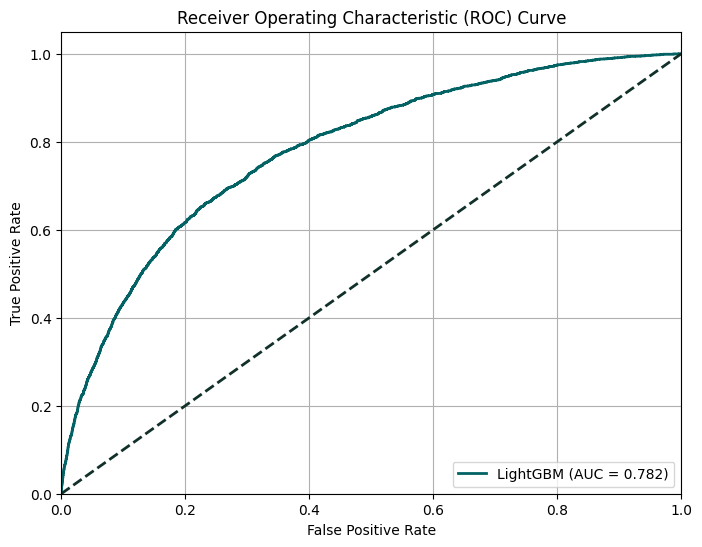

np.float64(0.7819554818535829)

In [130]:
y_probs = light_model.predict_proba(transformed_x_val)[:, 1]
plot_roc_curve(y_val, y_probs, model_name='LightGBM')

As expected adding additional information makes model to perform better (0,782 vs 0,771 AUC without supplementary data). However improvement is not that high as to have higher accuracy than 0,92.

#### Feature importance

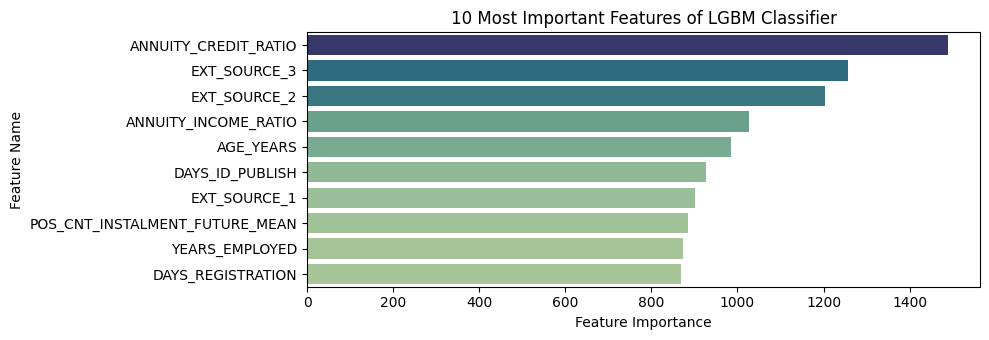

In [131]:
feature_names = X_processed.drop(choosing_params(building_param), axis=1).columns
mylist = plot_feature_importance(light_model, feature_names, model_name="LGBM Classifier")

External source information is in top 10 most important features, just like in XGB model. However, the most important feature here is annuity_credit_ratio. 

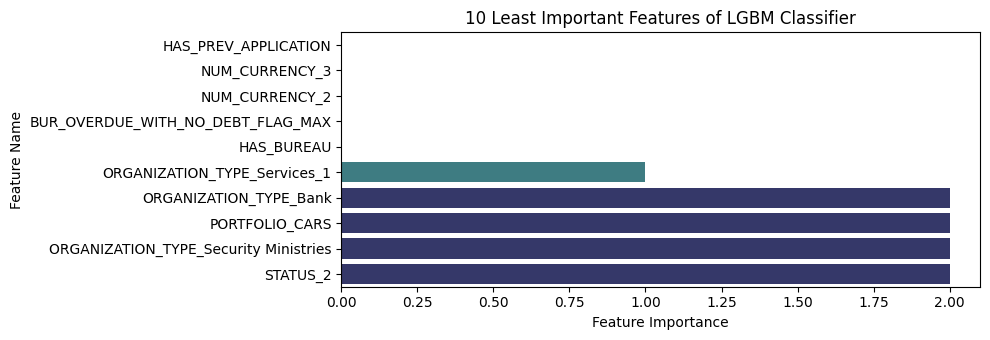

In [132]:
mylist = plot_feature_importance(light_model, feature_names, order="bottom", model_name="LGBM Classifier")

There are very few features with no importance in this version of model – only 5.

### Version 2

#### Optuna Study

Learning rate hyperparameter affects the result of model greatly, therefore it will be adjusted. Everything else stays the same. 

In [133]:
def objective(trial):
    # Hyperparameters

    impute_strategy = trial.suggest_categorical("impute_strategy", ["mean", "median", "most_frequent", "constant_-999"])
    building_param = trial.suggest_categorical('building_param', ['mean', 'median', 'mode'])
    outlier_factor = trial.suggest_float("outlier_factor", 1.5, 4.0)

    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 2000),
        "learning_rate": trial.suggest_float("learning_rate", 0.007, 0.02, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 7, 127),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
        "scale_pos_weight": trial.suggest_categorical("scale_pos_weight", [ratio, 1]),
    }

    # Imputer and model
    if impute_strategy.startswith("constant_"):
        fill_value = float(impute_strategy.split("_")[1])
        imputer = SimpleImputer(strategy="constant", fill_value=fill_value)
    else:
        imputer = SimpleImputer(strategy=impute_strategy)

    clf = LGBMClassifier(**params, random_state=8)

    pipeline = Pipeline(
        [
            ('building_param', FunctionTransformer(lambda df: df.drop(choosing_params(building_param), axis=1))),
            ('remove_outliers', FunctionTransformer(lambda df: remove_outliers_iqr(df, factor=outlier_factor))),
            ('imputer', imputer),
            ('clf', clf),
        ]
    )

    # Evaluate with cross-validation
    scores = cross_val_score(pipeline, X_processed, y_train, cv=3, scoring='roc_auc')
    return np.mean(scores)


# Run optimization
study_lgbm_2 = optuna.create_study(direction="maximize", sampler=optuna.samplers.RandomSampler(seed=8))
study_lgbm_2.optimize(objective, n_trials=30)

best_result = study_lgbm_2.best_trial
print("Best trial:")
print(best_result)

[I 2025-11-11 01:56:53,940] A new study created in memory with name: no-name-fb9d5b4d-5ad3-4e18-bc3c-7c192d02cd80


[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.276345 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 19329
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 274
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.118761 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 19320
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 275
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.4

[I 2025-11-11 02:01:50,398] Trial 0 finished with value: 0.7764337295413674 and parameters: {'impute_strategy': 'median', 'building_param': 'mode', 'outlier_factor': 2.505878400093412, 'n_estimators': 1093, 'learning_rate': 0.01156677125505189, 'num_leaves': 74, 'subsample': 0.7716930087712701, 'colsample_bytree': 0.8804477878014645, 'reg_alpha': 0.02578523933004178, 'reg_lambda': 0.0037769293830248463, 'scale_pos_weight': np.float64(0.08781859667120646)}. Best is trial 0 with value: 0.7764337295413674.


[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.315527 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 19692
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 274
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.103669 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 19650
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 275
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.4

[I 2025-11-11 02:05:20,721] Trial 1 finished with value: 0.7741846142251282 and parameters: {'impute_strategy': 'mean', 'building_param': 'mean', 'outlier_factor': 1.6773571118754969, 'n_estimators': 527, 'learning_rate': 0.010582024838695582, 'num_leaves': 115, 'subsample': 0.6727308059989335, 'colsample_bytree': 0.9923747186426357, 'reg_alpha': 1.813796003613881e-08, 'reg_lambda': 1.4627248055970364e-05, 'scale_pos_weight': 1}. Best is trial 0 with value: 0.7764337295413674.


[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.124636 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 20074
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 274
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.120650 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 20028
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 275
[LightGBM]

... (52 outputs left out)

[I 2025-11-11 04:08:02,520] Trial 28 finished with value: 0.7740151264083925 and parameters: {'impute_strategy': 'constant_-999', 'building_param': 'median', 'outlier_factor': 2.6913516132865833, 'n_estimators': 662, 'learning_rate': 0.011337661097840145, 'num_leaves': 106, 'subsample': 0.6858899963842484, 'colsample_bytree': 0.5770946689972087, 'reg_alpha': 0.01405266511081332, 'reg_lambda': 0.0026347620008998047, 'scale_pos_weight': np.float64(0.08781859667120646)}. Best is trial 22 with value: 0.780618033046481.


[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.373615 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 19514
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 300
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.408100 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 19516
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 300
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[Lig

[I 2025-11-11 04:13:54,269] Trial 29 finished with value: 0.7787795423353283 and parameters: {'impute_strategy': 'constant_-999', 'building_param': 'median', 'outlier_factor': 2.3954215431550576, 'n_estimators': 933, 'learning_rate': 0.012263671737159067, 'num_leaves': 127, 'subsample': 0.6620813961450908, 'colsample_bytree': 0.5901928327724709, 'reg_alpha': 1.6817790759020818e-07, 'reg_lambda': 0.09971890644715549, 'scale_pos_weight': np.float64(0.08781859667120646)}. Best is trial 22 with value: 0.780618033046481.


Best trial:
FrozenTrial(number=22, state=1, values=[0.780618033046481], datetime_start=datetime.datetime(2025, 11, 11, 3, 39, 18, 886846), datetime_complete=datetime.datetime(2025, 11, 11, 3, 45, 37, 217338), params={'impute_strategy': 'most_frequent', 'building_param': 'mode', 'outlier_factor': 2.956594306011862, 'n_estimators': 1392, 'learning_rate': 0.011373358860871752, 'num_leaves': 87, 'subsample': 0.5321358276168069, 'colsample_bytree': 0.7624692693920407, 'reg_alpha': 0.660854321507347, 'reg_lambda': 0.0005756180942597289, 'scale_pos_weight': np.float64(0.08781859667120646)}, user_attrs={}, system_attrs={}, intermediate_values={}, distributions={'impute_strategy': CategoricalDistribution(choices=('mean', 'median', 'most_frequent', 'constant_-999')), 'building_param': CategoricalDistribution(choices=('mean', 'median', 'mode')), 'outlier_factor': FloatDistribution(high=4.0, log=False, low=1.5, step=None), 'n_estimators': IntDistribution(high=2000, log=False, low=100, step=1), 'le

In [134]:
best_score = study_lgbm_2.best_value
print(f"best roc_auc: {best_score:.3f}")

best roc_auc: 0.781


In [135]:
optuna.visualization.plot_optimization_history(study_lgbm_2)

The best trial in Optuna study was 22nd one.

#### Hyperparameters

In [136]:
optuna.visualization.plot_slice(study_lgbm_2, params=['outlier_factor', 'building_param', 'impute_strategy'])

For impute_strategy median performs the worse. No other clear trends can be observed.

In [137]:
optuna.visualization.plot_slice(study_lgbm_2, params=['n_estimators', "learning_rate", "num_leaves", 'subsample'])

There is very clear trend for n_estimators – models with higher values than 700 perform better. No other clear trends.

In [138]:
optuna.visualization.plot_slice(
    study_lgbm_2, params=["colsample_bytree", "reg_alpha", "reg_lambda", "scale_pos_weight"]
)

There is a minor trend for models with lower values of colsample_bytree to performe better. Also, in this case models with balancing performed slightly better.  No other clear trends can be observed.

In [139]:
optuna.visualization.plot_param_importances(study_lgbm_2)

The most important hyperparameter is n_estimators.

#### Best parameters and confusion matrix

In [140]:
best_par = study_lgbm_2.best_params
impute_strategy = best_par['impute_strategy']
del best_par['impute_strategy']
building_param = best_par['building_param']
del best_par['building_param']
outlier_factor = best_par['outlier_factor']
del best_par['outlier_factor']

study_lgbm_2.best_params

{'impute_strategy': 'most_frequent',
 'building_param': 'mode',
 'outlier_factor': 2.956594306011862,
 'n_estimators': 1392,
 'learning_rate': 0.011373358860871752,
 'num_leaves': 87,
 'subsample': 0.5321358276168069,
 'colsample_bytree': 0.7624692693920407,
 'reg_alpha': 0.660854321507347,
 'reg_lambda': 0.0005756180942597289,
 'scale_pos_weight': np.float64(0.08781859667120646)}

In [141]:
if impute_strategy.startswith("constant_"):
    fill_value = float(impute_strategy.split("_")[1])
    imputer = SimpleImputer(strategy="constant", fill_value=fill_value)
else:
    imputer = SimpleImputer(strategy=impute_strategy)

light_model = Pipeline(
    [
        ('drop_columns', FunctionTransformer(lambda df: df.drop(choosing_params(building_param), axis=1))),
        ('remove_outliers', FunctionTransformer(lambda df: remove_outliers_iqr(df, factor=outlier_factor))),
        ('imput', imputer),
        ("clf", LGBMClassifier(**best_par, random_state=8)),
    ]
)
light_model.fit(X_processed, y_train)

yhat = light_model.predict(transformed_x_val)
prediction = list(map(round, yhat))

cm = confusion_matrix(y_val, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y_val, prediction))

[LightGBM] [Info] Number of positive: 19860, number of negative: 226148
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.457824 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 19424
[LightGBM] [Info] Number of data points in the train set: 246008, number of used features: 274
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432482
[LightGBM] [Info] Start training from score -2.432482
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive

#### Receiver Operating Characteristic (ROC) Curve

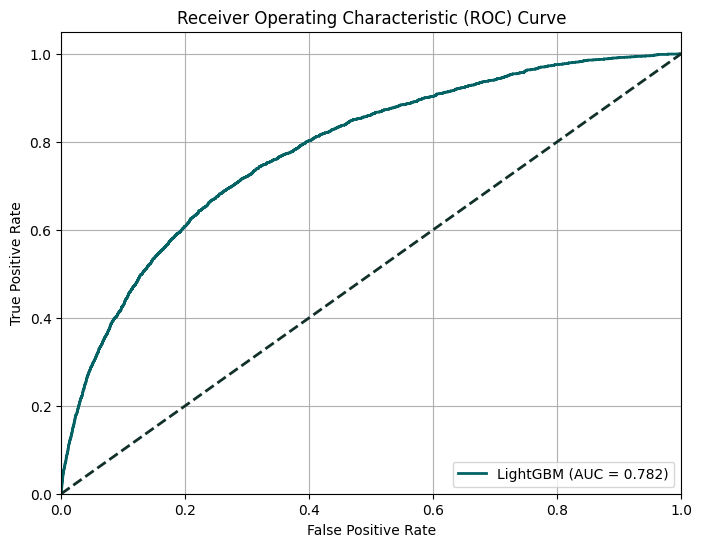

np.float64(0.7815879269008466)

In [142]:
y_probs = light_model.predict_proba(transformed_x_val)[:, 1]
plot_roc_curve(y_val, y_probs, model_name='LightGBM')

The performance of version 2 is very similar to version 1. Both versions have AUC of 0,782.

#### Feature importance

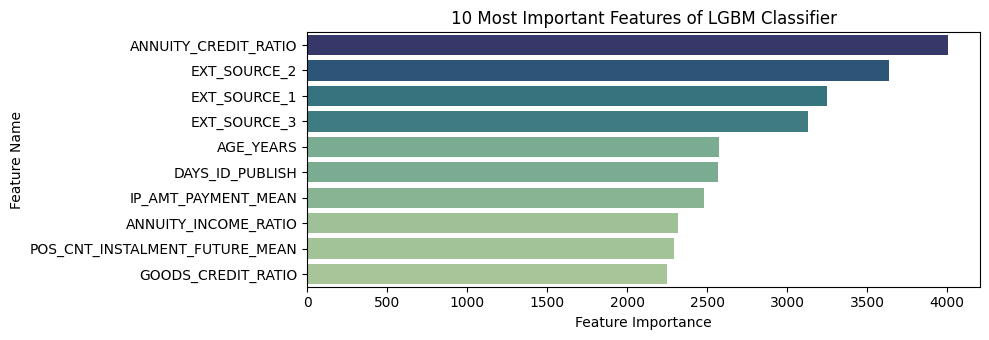

In [143]:
feature_names = X_processed.drop(choosing_params(building_param), axis=1).columns
mylist = plot_feature_importance(light_model, feature_names, model_name="LGBM Classifier")

The most important feature remains annuity_credit_ratio. It is followed by external sources of information.

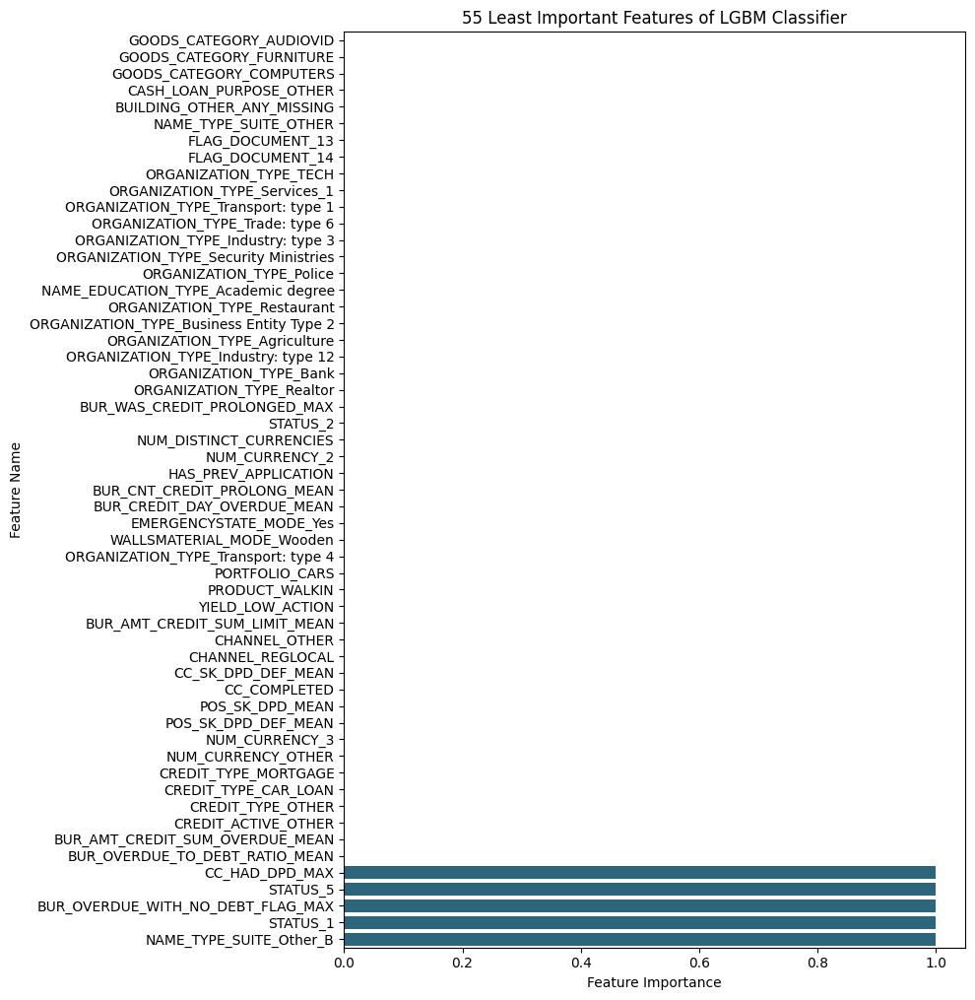

In [144]:
mylist = plot_feature_importance(light_model, feature_names, n=55, order="bottom", model_name="LGBM Classifier")

This version of model has a lot more features which are not important compared to version 1 (55 vs 5).

### Version 3

#### Optuna Study

N_estimators affect the result of model greatly, therefore it will be adjusted. Learning rate hyperparameter will also be adjusted. Col sample by try will be adjusted. Everything else stays the same. 

In [145]:
def objective(trial):
    # Hyperparameters

    impute_strategy = trial.suggest_categorical("impute_strategy", ["mean", "median", "most_frequent", "constant_-999"])
    building_param = trial.suggest_categorical('building_param', ['mean', 'median', 'mode'])
    outlier_factor = trial.suggest_float("outlier_factor", 1.5, 4.0)

    params = {
        "n_estimators": trial.suggest_int("n_estimators", 900, 1800),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.018, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 7, 127),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 0.8),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
        "scale_pos_weight": trial.suggest_categorical("scale_pos_weight", [ratio, 1]),
    }

    # Imputer and model
    if impute_strategy.startswith("constant_"):
        fill_value = float(impute_strategy.split("_")[1])
        imputer = SimpleImputer(strategy="constant", fill_value=fill_value)
    else:
        imputer = SimpleImputer(strategy=impute_strategy)

    clf = LGBMClassifier(**params, random_state=8)

    pipeline = Pipeline(
        [
            ('building_param', FunctionTransformer(lambda df: df.drop(choosing_params(building_param), axis=1))),
            ('remove_outliers', FunctionTransformer(lambda df: remove_outliers_iqr(df, factor=outlier_factor))),
            ('imputer', imputer),
            ('clf', clf),
        ]
    )

    # Evaluate with cross-validation
    scores = cross_val_score(pipeline, X_processed, y_train, cv=3, scoring='roc_auc')
    return np.mean(scores)


# Run optimization
study_lgbm_3 = optuna.create_study(direction="maximize", sampler=optuna.samplers.RandomSampler(seed=8))
study_lgbm_3.optimize(objective, n_trials=50)

best_result = study_lgbm_3.best_trial
print("Best trial:")
print(best_result)

[I 2025-11-11 04:16:52,693] A new study created in memory with name: no-name-f861828b-f3cd-46a7-9708-d52d95741830


[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.309473 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 19329
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 274
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.327166 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 19320
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 275
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[Lig

[I 2025-11-11 04:22:36,644] Trial 0 finished with value: 0.7768511556111902 and parameters: {'impute_strategy': 'median', 'building_param': 'mode', 'outlier_factor': 2.505878400093412, 'n_estimators': 1370, 'learning_rate': 0.013247083449251209, 'num_leaves': 74, 'subsample': 0.7716930087712701, 'colsample_bytree': 0.7043582302411716, 'reg_alpha': 0.02578523933004178, 'reg_lambda': 0.0037769293830248463, 'scale_pos_weight': np.float64(0.08781859667120646)}. Best is trial 0 with value: 0.7768511556111902.


[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.129475 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 19692
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 274
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.107235 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 19650
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 275
[LightGBM]

[I 2025-11-11 04:28:28,170] Trial 1 finished with value: 0.7782681697498498 and parameters: {'impute_strategy': 'mean', 'building_param': 'mean', 'outlier_factor': 1.6773571118754969, 'n_estimators': 1102, 'learning_rate': 0.012603297005576069, 'num_leaves': 115, 'subsample': 0.6727308059989335, 'colsample_bytree': 0.7938997749141086, 'reg_alpha': 1.813796003613881e-08, 'reg_lambda': 1.4627248055970364e-05, 'scale_pos_weight': 1}. Best is trial 1 with value: 0.7782681697498498.


[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.356377 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 20074
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 274
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.119154 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 20028
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 275
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.4

... (92 outputs left out)

[I 2025-11-11 09:17:32,907] Trial 48 finished with value: 0.7787464114577324 and parameters: {'impute_strategy': 'median', 'building_param': 'median', 'outlier_factor': 2.2503196851213065, 'n_estimators': 1393, 'learning_rate': 0.011798452388693365, 'num_leaves': 110, 'subsample': 0.9184979554841979, 'colsample_bytree': 0.5578216265808746, 'reg_alpha': 1.8114506312652198e-08, 'reg_lambda': 1.43550163399704e-08, 'scale_pos_weight': 1}. Best is trial 32 with value: 0.7816308694955821.


[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.276925 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 19640
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 274
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.281593 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 19645
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 275
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[Lig

[I 2025-11-11 09:25:26,028] Trial 49 finished with value: 0.7827318025607853 and parameters: {'impute_strategy': 'most_frequent', 'building_param': 'median', 'outlier_factor': 3.911498936135372, 'n_estimators': 1571, 'learning_rate': 0.014589306277961322, 'num_leaves': 115, 'subsample': 0.9842128936130204, 'colsample_bytree': 0.6446457765112299, 'reg_alpha': 6.634562176331224e-06, 'reg_lambda': 8.809686218403414, 'scale_pos_weight': 1}. Best is trial 49 with value: 0.7827318025607853.


Best trial:
FrozenTrial(number=49, state=1, values=[0.7827318025607853], datetime_start=datetime.datetime(2025, 11, 11, 9, 17, 32, 908908), datetime_complete=datetime.datetime(2025, 11, 11, 9, 25, 26, 28928), params={'impute_strategy': 'most_frequent', 'building_param': 'median', 'outlier_factor': 3.911498936135372, 'n_estimators': 1571, 'learning_rate': 0.014589306277961322, 'num_leaves': 115, 'subsample': 0.9842128936130204, 'colsample_bytree': 0.6446457765112299, 'reg_alpha': 6.634562176331224e-06, 'reg_lambda': 8.809686218403414, 'scale_pos_weight': 1}, user_attrs={}, system_attrs={}, intermediate_values={}, distributions={'impute_strategy': CategoricalDistribution(choices=('mean', 'median', 'most_frequent', 'constant_-999')), 'building_param': CategoricalDistribution(choices=('mean', 'median', 'mode')), 'outlier_factor': FloatDistribution(high=4.0, log=False, low=1.5, step=None), 'n_estimators': IntDistribution(high=1800, log=False, low=900, step=1), 'learning_rate': FloatDistribu

In [146]:
best_score = study_lgbm_3.best_value
print(f"best roc_auc: {best_score:.3f}")

best roc_auc: 0.783


In [147]:
optuna.visualization.plot_optimization_history(study_lgbm_3)

Best trial in Optuna study was 50th.

#### Hyperparameters

In [148]:
optuna.visualization.plot_slice(study_lgbm_3, params=['outlier_factor', 'building_param', 'impute_strategy'])

For building_param, the median appears to perform best. Among imputation strategies, the most frequent strategy performed the best, while median performed the worst. Higher values of outlier_factor also lead to better performance.

In [149]:
optuna.visualization.plot_slice(study_lgbm_3, params=['n_estimators', "learning_rate", "num_leaves", 'subsample'])

A learning_rate of approximately 0,0145 appears to perform best. The optimal value for n_estimators is around 1600, and higher values of num_leaves also seem to improve performance. Additionally, higher values of subsample lead to better results.

In [150]:
optuna.visualization.plot_slice(
    study_lgbm_3, params=["colsample_bytree", "reg_alpha", "reg_lambda", "scale_pos_weight"]
)

The best value for colsample_bytree is around 0,65, while the best value for reg_alpha is approximately 6,6μ. Higher values of reg_lambda also seem to improve performance. Using no balancing (scale_pos_weight = 1) outperforms applying balancing in this case.

In [151]:
optuna.visualization.plot_param_importances(study_lgbm_3)

The most important hyperparameter was impute_strategy. Other highly important hyperparameters were learning_rate, num_leaves and outlier_factor.

#### Best parameters and confusion matrix

In [152]:
best_par = study_lgbm_3.best_params
impute_strategy = best_par['impute_strategy']
del best_par['impute_strategy']
building_param = best_par['building_param']
del best_par['building_param']
outlier_factor = best_par['outlier_factor']
del best_par['outlier_factor']

study_lgbm_3.best_params

{'impute_strategy': 'most_frequent',
 'building_param': 'median',
 'outlier_factor': 3.911498936135372,
 'n_estimators': 1571,
 'learning_rate': 0.014589306277961322,
 'num_leaves': 115,
 'subsample': 0.9842128936130204,
 'colsample_bytree': 0.6446457765112299,
 'reg_alpha': 6.634562176331224e-06,
 'reg_lambda': 8.809686218403414,
 'scale_pos_weight': 1}

In [153]:
if impute_strategy.startswith("constant_"):
    fill_value = float(impute_strategy.split("_")[1])
    imputer = SimpleImputer(strategy="constant", fill_value=fill_value)
else:
    imputer = SimpleImputer(strategy=impute_strategy)

light_model = Pipeline(
    [
        ('drop_columns', FunctionTransformer(lambda df: df.drop(choosing_params(building_param), axis=1))),
        ('remove_outliers', FunctionTransformer(lambda df: remove_outliers_iqr(df, factor=outlier_factor))),
        ('imput', imputer),
        ("clf", LGBMClassifier(**best_par, random_state=8)),
    ]
)
light_model.fit(X_processed, y_train)

yhat = light_model.predict(transformed_x_val)
prediction = list(map(round, yhat))

cm = confusion_matrix(y_val, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y_val, prediction))

[LightGBM] [Info] Number of positive: 19860, number of negative: 226148
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.421603 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 19654
[LightGBM] [Info] Number of data points in the train set: 246008, number of used features: 274
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432482
[LightGBM] [Info] Start training from score -2.432482
Confusion Matrix : 
 [[28178    91]
 [ 2379   103]]
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     28269
           1       0.53      0.04      0.08      2482

    accuracy                           0.92     30751
   macro avg       0.73      0.52      0.52     30751
weighted avg       0.89      0.92      0.89     30751



#### Receiver Operating Characteristic (ROC) Curve

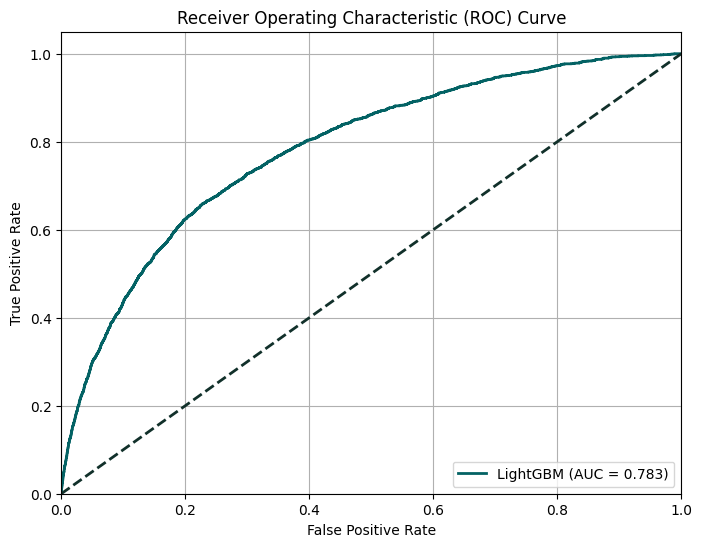

np.float64(0.783322314808615)

In [154]:
y_probs = light_model.predict_proba(transformed_x_val)[:, 1]
plot_roc_curve(y_val, y_probs, model_name='LightGBM')

This version of LGBM performs slightly better than versions 1 and 2 (AUC 0,783 vs 0,782).

#### Feature importance

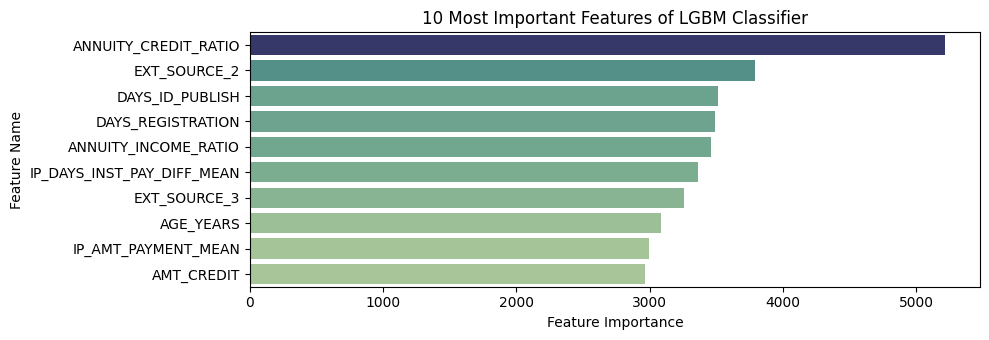

In [155]:
feature_names = X_processed.drop(choosing_params(building_param), axis=1).columns
mylist = plot_feature_importance(light_model, feature_names, model_name="LGBM Classifier")

Annuity_credit_ratio remains the most important feature; however, EXT_SOURCE_1 is no longer among the top 10 most important features, which distinguishes this version from all previous model versions.

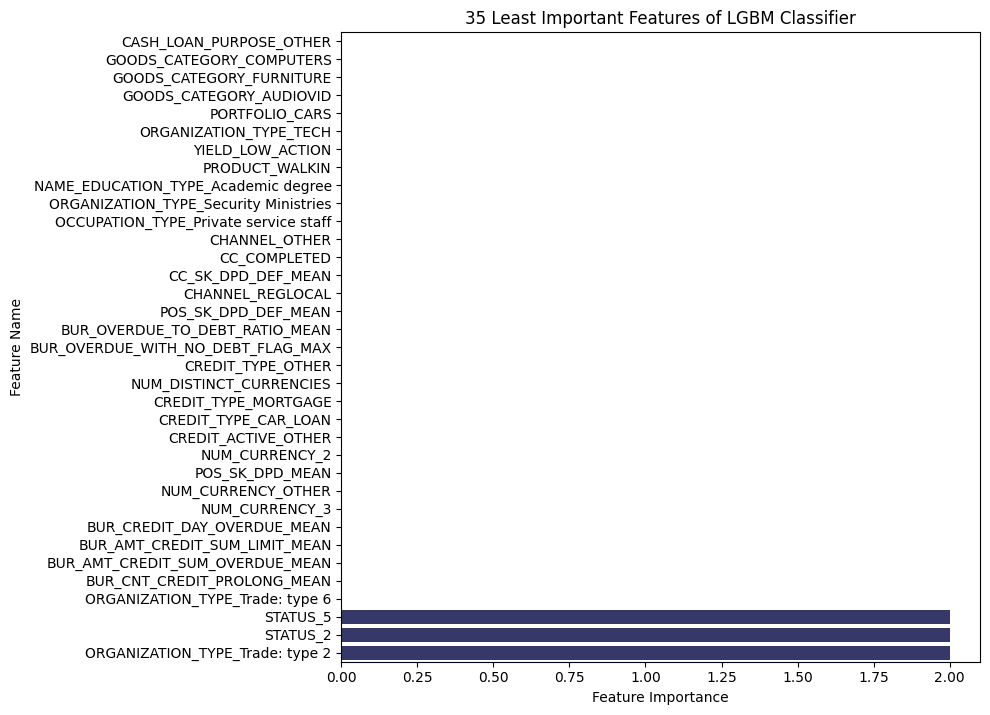

In [156]:
mylist = plot_feature_importance(light_model, feature_names, n=35, order="bottom", model_name="LGBM Classifier")

There are 32 not important features in this version. Differences between model versions are due to that they evaluate certain features differently.

### Version 4

#### Optuna Study

Col sample by tree affect the result of model greatly, therefore it will be adjusted. Learning rate hyperparameter will also be adjusted. For impute strategy median and most frequent will be removed. From building params, median will be removed. Num leaves, n estimators, subsample, outlier factor, reg alpha will be adjusted. Everything else stays the same. 

In [157]:
def objective(trial):
    # Hyperparameters

    impute_strategy = trial.suggest_categorical("impute_strategy", ["mean", "constant_-999"])
    building_param = trial.suggest_categorical('building_param', ['mean', 'mode'])
    outlier_factor = trial.suggest_float("outlier_factor", 1.5, 3.0)

    params = {
        "n_estimators": trial.suggest_int("n_estimators", 1000, 1350),
        "learning_rate": trial.suggest_float("learning_rate", 0.009, 0.015, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 45, 91),
        "subsample": trial.suggest_float("subsample", 0.5, 0.75),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.45, 0.55),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-1, 100.0, log=True),
        "scale_pos_weight": trial.suggest_categorical("scale_pos_weight", [ratio, 1]),
    }

    # Imputer and model
    if impute_strategy.startswith("constant_"):
        fill_value = float(impute_strategy.split("_")[1])
        imputer = SimpleImputer(strategy="constant", fill_value=fill_value)
    else:
        imputer = SimpleImputer(strategy=impute_strategy)

    clf = LGBMClassifier(**params, random_state=8)

    pipeline = Pipeline(
        [
            ('building_param', FunctionTransformer(lambda df: df.drop(choosing_params(building_param), axis=1))),
            ('remove_outliers', FunctionTransformer(lambda df: remove_outliers_iqr(df, factor=outlier_factor))),
            ('imputer', imputer),
            ('clf', clf),
        ]
    )

    # Evaluate with cross-validation
    scores = cross_val_score(pipeline, X_processed, y_train, cv=3, scoring='roc_auc')
    return np.mean(scores)


# Run optimization
study_lgbm_4 = optuna.create_study(direction="maximize", sampler=optuna.samplers.RandomSampler(seed=8))
study_lgbm_4.optimize(objective, n_trials=55)

best_result = study_lgbm_4.best_trial
print("Best trial:")
print(best_result)

[I 2025-11-11 09:29:13,799] A new study created in memory with name: no-name-07d24318-cb6f-4354-8bfe-7d54b9dcfb5e


[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.150072 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 19839
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 300
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best

[I 2025-11-11 09:35:03,362] Trial 0 finished with value: 0.7787609382411707 and parameters: {'impute_strategy': 'constant_-999', 'building_param': 'mean', 'outlier_factor': 1.8490924919659362, 'n_estimators': 1004, 'learning_rate': 0.01121350751717502, 'num_leaves': 63, 'subsample': 0.6306686678381423, 'colsample_bytree': 0.49783917958024027, 'reg_alpha': 0.0009958828750129861, 'reg_lambda': 4.267347919781316, 'scale_pos_weight': np.float64(0.08781859667120646)}. Best is trial 0 with value: 0.7787609382411707.


[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.093237 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 19288
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 274
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.092790 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 19290
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 275
[LightGBM]

[I 2025-11-11 09:40:59,177] Trial 1 finished with value: 0.7801463429452543 and parameters: {'impute_strategy': 'mean', 'building_param': 'mode', 'outlier_factor': 2.0006610682660053, 'n_estimators': 1076, 'learning_rate': 0.009307692307147354, 'num_leaves': 91, 'subsample': 0.5319639282312579, 'colsample_bytree': 0.48221307932041796, 'reg_alpha': 4.349963398762401e-08, 'reg_lambda': 0.4723999216420231, 'scale_pos_weight': 1}. Best is trial 1 with value: 0.7801463429452543.


[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.134372 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 19380
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 300
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.124669 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 19377
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 300
[LightGBM]

... (102 outputs left out)

[I 2025-11-11 15:57:59,979] Trial 53 finished with value: 0.7816683776401163 and parameters: {'impute_strategy': 'constant_-999', 'building_param': 'mode', 'outlier_factor': 2.9997952087634667, 'n_estimators': 1253, 'learning_rate': 0.011845113843201497, 'num_leaves': 53, 'subsample': 0.5811037504516715, 'colsample_bytree': 0.49015360234998606, 'reg_alpha': 1.3803849864715772e-05, 'reg_lambda': 0.8767690585155832, 'scale_pos_weight': 1}. Best is trial 51 with value: 0.7837297398270753.


[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.132817 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 20026
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 300
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432480
[LightGBM] [Info] Start training from score -2.432480
[LightGBM] [Info] Number of positive: 13240, number of negative: 150765
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.134941 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 20010
[LightGBM] [Info] Number of data points in the train set: 164005, number of used features: 300
[LightGBM]

[I 2025-11-11 16:04:16,575] Trial 54 finished with value: 0.7820644226243738 and parameters: {'impute_strategy': 'constant_-999', 'building_param': 'mean', 'outlier_factor': 2.642292527294058, 'n_estimators': 1021, 'learning_rate': 0.011832304863900828, 'num_leaves': 52, 'subsample': 0.5889532156104037, 'colsample_bytree': 0.5213260241299644, 'reg_alpha': 0.4183824649091536, 'reg_lambda': 4.651251510540097, 'scale_pos_weight': 1}. Best is trial 51 with value: 0.7837297398270753.


Best trial:
FrozenTrial(number=51, state=1, values=[0.7837297398270753], datetime_start=datetime.datetime(2025, 11, 11, 15, 34, 48, 512906), datetime_complete=datetime.datetime(2025, 11, 11, 15, 43, 43, 705972), params={'impute_strategy': 'constant_-999', 'building_param': 'mean', 'outlier_factor': 2.5628031334253443, 'n_estimators': 1281, 'learning_rate': 0.013995247988332347, 'num_leaves': 81, 'subsample': 0.6519486573995867, 'colsample_bytree': 0.5027605590802061, 'reg_alpha': 0.048546620008132944, 'reg_lambda': 95.48031493906012, 'scale_pos_weight': 1}, user_attrs={}, system_attrs={}, intermediate_values={}, distributions={'impute_strategy': CategoricalDistribution(choices=('mean', 'constant_-999')), 'building_param': CategoricalDistribution(choices=('mean', 'mode')), 'outlier_factor': FloatDistribution(high=3.0, log=False, low=1.5, step=None), 'n_estimators': IntDistribution(high=1350, log=False, low=1000, step=1), 'learning_rate': FloatDistribution(high=0.015, log=True, low=0.009

In [158]:
best_score = study_lgbm_4.best_value
print(f"best roc_auc: {best_score:.3f}")

best roc_auc: 0.784


In [159]:
optuna.visualization.plot_optimization_history(study_lgbm_4)

Best optuna trial was 51st. All of the trials, expect for few outliers, are very close to each other.

#### Hyperparameters

In [160]:
optuna.visualization.plot_slice(study_lgbm_4, params=['outlier_factor', 'building_param', 'impute_strategy'])

In [161]:
optuna.visualization.plot_slice(study_lgbm_4, params=['n_estimators', "learning_rate", "num_leaves", 'subsample'])

In [162]:
optuna.visualization.plot_slice(
    study_lgbm_4, params=["colsample_bytree", "reg_alpha", "reg_lambda", "scale_pos_weight"]
)

There are no clear trends in the slice plots.

In [163]:
optuna.visualization.plot_param_importances(study_lgbm_4)

The most important hyperparemeter is reg_alpha.

#### Best parameters and confusion matrix

In [164]:
best_par = study_lgbm_4.best_params
impute_strategy = best_par['impute_strategy']
del best_par['impute_strategy']
building_param = best_par['building_param']
del best_par['building_param']
outlier_factor = best_par['outlier_factor']
del best_par['outlier_factor']

study_lgbm_4.best_params

{'impute_strategy': 'constant_-999',
 'building_param': 'mean',
 'outlier_factor': 2.5628031334253443,
 'n_estimators': 1281,
 'learning_rate': 0.013995247988332347,
 'num_leaves': 81,
 'subsample': 0.6519486573995867,
 'colsample_bytree': 0.5027605590802061,
 'reg_alpha': 0.048546620008132944,
 'reg_lambda': 95.48031493906012,
 'scale_pos_weight': 1}

In [165]:
if impute_strategy.startswith("constant_"):
    fill_value = float(impute_strategy.split("_")[1])
    imputer = SimpleImputer(strategy="constant", fill_value=fill_value)
else:
    imputer = SimpleImputer(strategy=impute_strategy)

light_model = Pipeline(
    [
        ('drop_columns', FunctionTransformer(lambda df: df.drop(choosing_params(building_param), axis=1))),
        ('remove_outliers', FunctionTransformer(lambda df: remove_outliers_iqr(df, factor=outlier_factor))),
        ('imput', imputer),
        ("clf", LGBMClassifier(**best_par, random_state=8)),
    ]
)
light_model.fit(X_processed, y_train)

yhat = light_model.predict(transformed_x_val)
prediction = list(map(round, yhat))

cm = confusion_matrix(y_val, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y_val, prediction))

[LightGBM] [Info] Number of positive: 19860, number of negative: 226148
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.198144 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 20010
[LightGBM] [Info] Number of data points in the train set: 246008, number of used features: 300
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432482
[LightGBM] [Info] Start training from score -2.432482
Confusion Matrix : 
 [[28196    73]
 [ 2384    98]]
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     28269
           1       0.57      0.04      0.07      2482

    accuracy                           0.92     30751
   macro avg       0.75      0.52      0.52     30751
weighted avg       0.89      0.92      0.89     30751



#### Receiver Operating Characteristic (ROC) Curve

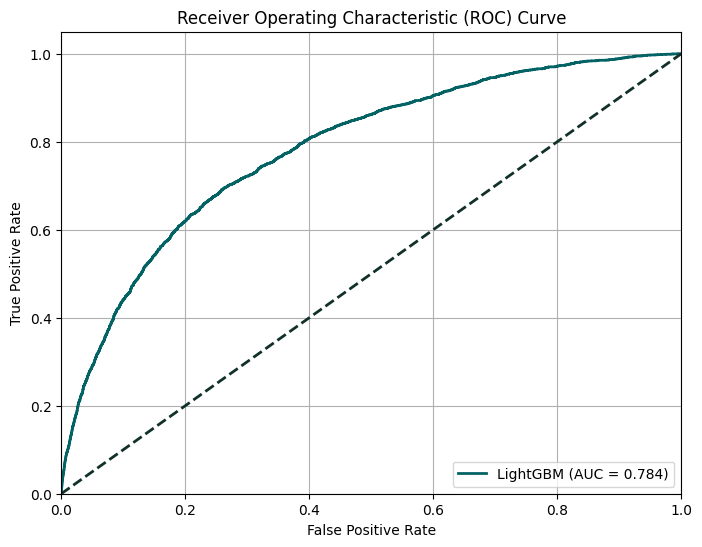

np.float64(0.7836922499109155)

In [166]:
y_probs = light_model.predict_proba(transformed_x_val)[:, 1]
plot_roc_curve(y_val, y_probs, model_name='LightGBM')

This version performs slightly better than the previous one (0,784 AUC vs 0,783). All versions had accuracy of 0,92.

#### Feature importance

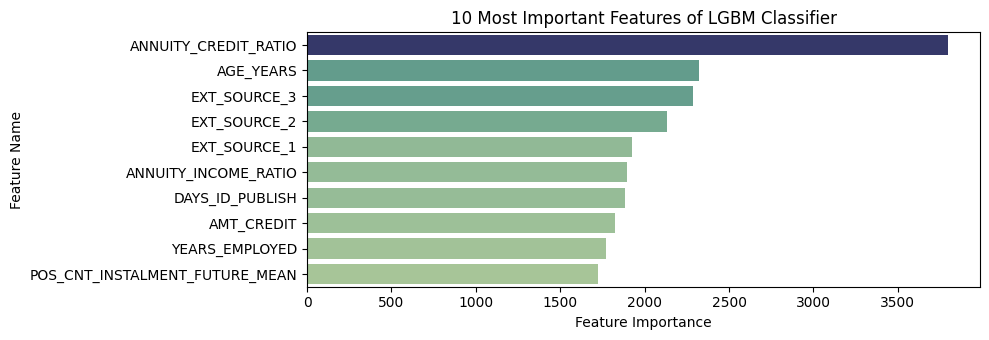

In [167]:
feature_names = X_processed.drop(choosing_params(building_param), axis=1).columns
mylist = plot_feature_importance(light_model, feature_names, model_name="LGBM Classifier")

Annuity_credit_ratio remains the most important feature, as in all previous versions of the LGBM model. The second most important feature is the applicant's age, while external source variables also play a significant role. These findings suggest that the target variable – which represents the likelihood of loan repayment – is strongly influenced by the balance between a client's annuity and credit amount, their age, and their overall credit reliability captured by external sources.

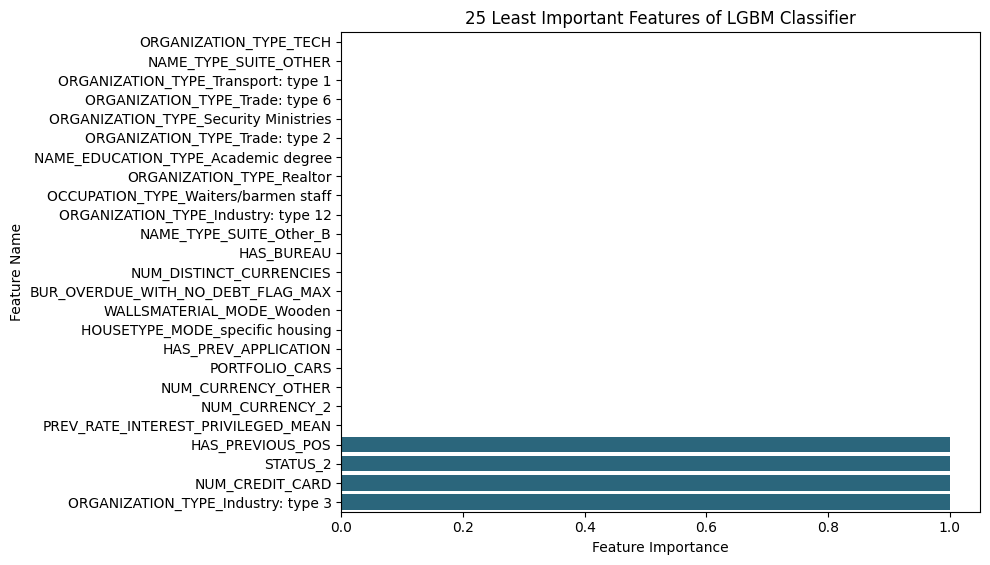

In [168]:
mylist = plot_feature_importance(light_model, feature_names, n=25, order="bottom", model_name="LGBM Classifier")

There are 21 features with no importance for this version.

# Final models testing

Because the performance is slightly better, version 4 of both the XGB and LGBM models will be used for the final selection. Both models will be tested using the test dataset and deployed on Google Cloud.

## XGB Classifier

In [169]:
best_par_xgb = study_xgb_4.best_params
building_param_xgb = best_par_xgb['building_param']
del best_par_xgb['building_param']
outlier_factor_xgb = best_par_xgb['outlier_factor']
del best_par_xgb['outlier_factor']

In [170]:
preprocessor_xgb = make_pipeline(
    FunctionTransformer(preprocess_app, validate=False),
    FunctionTransformer(lambda df: df.drop(choosing_params(building_param_xgb), axis=1)),
    FunctionTransformer(connect_all, validate=False),
    FunctionTransformer(lambda df: remove_outliers_iqr(df, factor=outlier_factor_xgb)),
)

imputer_xgb = SimpleImputer(strategy="constant", fill_value=-999)

xgb_model = Pipeline(
    [
        ('preprocessor', preprocessor_xgb),
        ('imput', imputer_xgb),
        ("clf", xgb.XGBClassifier(**best_par_xgb, random_state=8)),
    ]
)
xgb_model.fit(x_train, y_train)

yhat = xgb_model.predict(x_test)
prediction = list(map(round, yhat))

cm = confusion_matrix(y_test, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y_test, prediction))

Confusion Matrix : 
 [[28181    88]
 [ 2351   132]]
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     28269
           1       0.60      0.05      0.10      2483

    accuracy                           0.92     30752
   macro avg       0.76      0.53      0.53     30752
weighted avg       0.90      0.92      0.89     30752



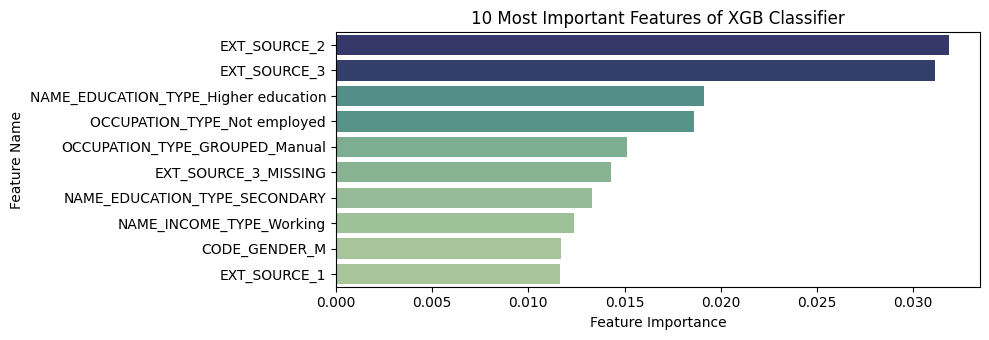

In [171]:
feature_names = preprocessor_xgb.transform(x_train).columns
mylist = plot_feature_importance(xgb_model, feature_names, model_name="XGB Classifier")

The XGB model achieved a recall of 0,05 and a precision of 0.60 for the target variable, with an overall accuracy of 0,92. Although its accuracy is not higher than the baseline model (0,92), it performs better in other metrics such as AUC and precision.

The most important feature for this model is EXT_SOURCE_2, closely followed by EXT_SOURCE_3. EXT_SOURCE_1 also appears among the top ten features, indicating that external credit scoring variables remain highly predictive of the target – the likelihood of loan repayment. Additionally, EXT_SOURCE_3_MISSING appears in the list, suggesting that missing external credit data also carries information about risk. Other influential factors include education and employment-related features such as NAME_EDUCATION_TYPE_Higher education, NAME_EDUCATION_TYPE_Secondary, OCCUPATION_TYPE_Not employed, OCCUPATION_TYPE_GROUPED_Manual, and NAME_INCOME_TYPE_Working, reflecting the borrower's socioeconomic status. Gender also plays a role, as CODE_GENDER_M is among the top features.

## LGBMClassifier

In [172]:
best_par_lgbm = study_lgbm_4.best_params
impute_strategy_lgbm = best_par_lgbm['impute_strategy']
del best_par_lgbm['impute_strategy']
building_param_lgbm = best_par_lgbm['building_param']
del best_par_lgbm['building_param']
outlier_factor_lgbm = best_par_lgbm['outlier_factor']
del best_par_lgbm['outlier_factor']

In [173]:
if impute_strategy_lgbm.startswith("constant_"):
    fill_value = float(impute_strategy.split("_")[1])
    imputer_lgbm = SimpleImputer(strategy="constant", fill_value=fill_value)
else:
    imputer_lgbm = SimpleImputer(strategy=impute_strategy)

preprocessor_lgbm = make_pipeline(
    FunctionTransformer(preprocess_app, validate=False),
    FunctionTransformer(lambda df: df.drop(choosing_params(building_param_lgbm), axis=1)),
    FunctionTransformer(connect_all, validate=False),
    FunctionTransformer(lambda df: remove_outliers_iqr(df, factor=outlier_factor_lgbm)),
)

light_model = Pipeline(
    [
        ('preprocessor', preprocessor_lgbm),
        ('imput', imputer_lgbm),
        ("clf", LGBMClassifier(**best_par_lgbm, random_state=8)),
    ]
)
light_model.fit(x_train, y_train)

yhat = light_model.predict(x_test)
prediction = list(map(round, yhat))

cm = confusion_matrix(y_test, prediction)
print("Confusion Matrix : \n", cm)

print(classification_report(y_test, prediction))

[LightGBM] [Info] Number of positive: 19860, number of negative: 226148
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.164125 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 20010
[LightGBM] [Info] Number of data points in the train set: 246008, number of used features: 300
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432482
[LightGBM] [Info] Start training from score -2.432482
Confusion Matrix : 
 [[28203    66]
 [ 2369   114]]
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     28269
           1       0.63      0.05      0.09      2483

    accuracy                           0.92     30752
   macro avg       0.78      0.52      0.52     30752
weighted avg       0.90      0.92      0.89     30752



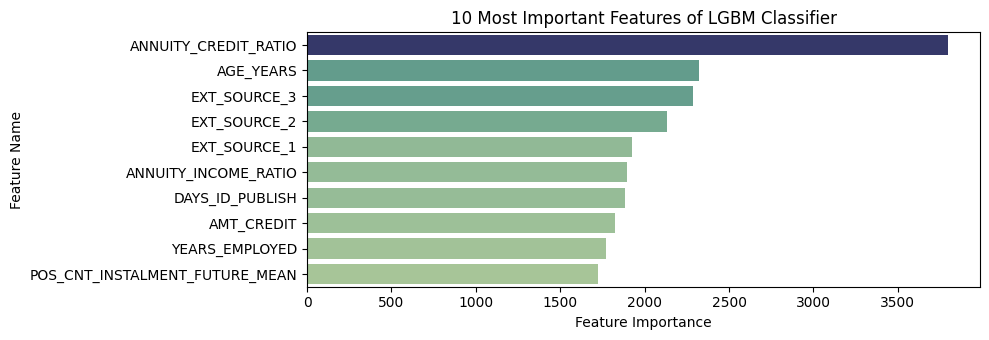

In [174]:
feature_names = preprocessor_lgbm.transform(x_train).columns
mylist = plot_feature_importance(light_model, feature_names, model_name="LGBM Classifier")

The LGBM model achieved a recall of 0,05 and a precision of 0,63, with the same overall accuracy of 0,92. Although its accuracy is identical to the baseline model, it shows improved precision and AUC.

The most important feature in this model is ANNUITY_CREDIT_RATIO, which represents the proportion of a borrower's annuity payment to their total credit amount — a key indicator of repayment capacity. The second most important feature is AGE_YEARS, highlighting the relevance of applicant age in assessing loan risk. These are followed by EXT_SOURCE_3, EXT_SOURCE_2, and EXT_SOURCE_1, confirming that external credit scores remain strong predictors of repayment likelihood. Other notable features include ANNUITY_INCOME_RATIO, DAYS_ID_PUBLISH, AMT_CREDIT, YEARS_EMPLOYED, and POS_CNT_INSTALMENT_FUTURE_MEAN, each reflecting financial stability and repayment behavior.

## Receiver Operating Characteristic (ROC) Curve

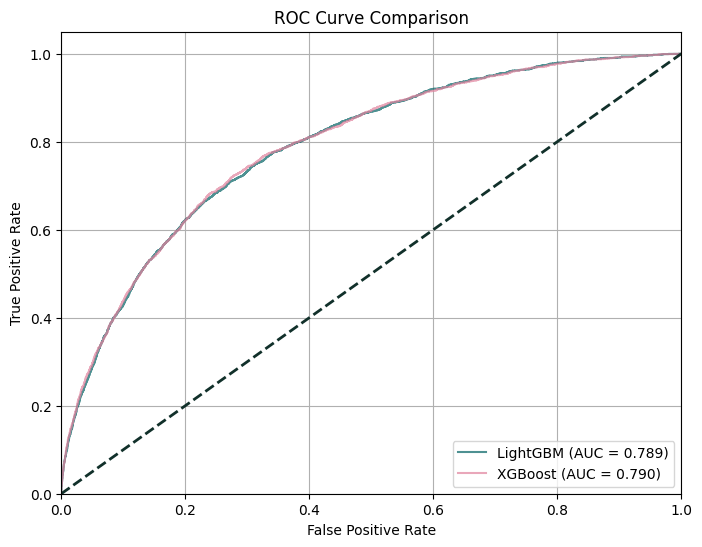

In [175]:
y_probs_light = light_model.predict_proba(x_test)[:, 1]
fpr_light, tpr_light, _ = roc_curve(y_test, y_probs_light)
roc_auc_light = auc(fpr_light, tpr_light)

y_probs_xgb = xgb_model.predict_proba(x_test)[:, 1]
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_probs_xgb)
roc_auc_xgb = auc(fpr_xgb, tpr_xgb)

# Plot both
plt.figure(figsize=(8, 6))
plt.plot(fpr_light, tpr_light, color='#036264', lw=1.5, alpha=0.7, label=f'LightGBM (AUC = {roc_auc_light:.3f})')
plt.plot(fpr_xgb, tpr_xgb, color='#e0829d', lw=1.5, alpha=0.7, label=f'XGBoost (AUC = {roc_auc_xgb:.3f})')

# Random guess diagonal
plt.plot([0, 1], [0, 1], color='#11302a', linestyle='--', lw=2)

# Formatting
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

Both models outperform the baseline in terms of AUC, with the XGB model achieving 0,790 and the LGBM model 0,789, compared to the baseline AUC of 0,714. While their performance is nearly identical, XGB slightly outperforms LGBM in AUC, whereas LGBM shows marginally better precision. Therefore, both models can be considered as candidates for deployment, with XGB offering marginally better overall discrimination and LGBM providing slightly more precise predictions.

## Deploying the model

Here are all the steps required to save the files needed for model deployment. The deployed models can be tested using test_api.py.

In [176]:
cat_cols = x_val.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = x_val.select_dtypes(exclude=["object", "category"]).columns.tolist()

# Build categorical "template" DataFrame (unique categories per column)
cat_template_parts = [x_val[[col]].drop_duplicates().reset_index(drop=True) for col in cat_cols]
cat_template_df = pd.concat(cat_template_parts, axis=1)

# Create numeric template (single row of zeros)
num_template_df = pd.DataFrame({col: [0] * len(cat_template_df) for col in num_cols})

# Combine both into one full template
template_df = pd.concat([cat_template_df, num_template_df], axis=1)

# Add missing cathegory for OCCUPATION_TYPE
template_df.loc[0, 'OCCUPATION_TYPE'] = "Not employed"

# Reorder columns to match the original x_val order
template_df = template_df[x_val.columns]
template_df = template_df.copy().ffill()
template_df.head()

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,0,Cash loans,M,N,N,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,Revolving loans,F,Y,Y,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,Revolving loans,F,Y,Y,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,Revolving loans,F,Y,Y,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,Revolving loans,F,Y,Y,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [177]:
template_df.to_csv("app/template.csv", index=False)

with open("app/list_to_remove.txt", "w") as f:
    f.write("\n".join(list_to_remove))

with open("app/building_param_xgb.txt", "w") as f:
    f.write(building_param_xgb)

with open("app/outlier_factor_xgb.txt", "w") as f:
    f.write(str(outlier_factor_xgb))

with open("app/xgb_model.pkl", "wb") as f:
    dill.dump(xgb_model, f)

with open("app/building_param_lgbm.txt", "w") as f:
    f.write(building_param_lgbm)

with open("app/impute_strategy_lgbm.txt", "w") as f:
    f.write(impute_strategy_lgbm)

with open("app/outlier_factor_lgbm.txt", "w") as f:
    f.write(str(outlier_factor_lgbm))

with open("app/light_model.pkl", "wb") as f:
    dill.dump(light_model, f)

feature_names = list(X.columns)
with open("app/feature_names.json", "w") as f:
    json.dump(feature_names, f)

# End Of Part Four

In this part, XGBoost and LightGBM models were trained and deployed on Google Cloud. The deployed API can be accessed at https://fastapi-models-166989861873.europe-central2.run.app

Overall, while both models outperformed the baseline model, they did not achieve the target of higher accuracy than 0.92. Despite this, the project demonstrated a complete end-to-end machine learning workflow – from data preprocessing and feature engineering to model training, evaluation, and cloud deployment.

The results suggest that there is room for further optimization, particularly in feature engineering, hyperparameter tuning, and model selection.

# Conclusion

This marks the end of the project. To summarize, in Part 1 the application data was explored. While there were no strong correlations with the target variable, several meaningful tendencies were observed. For example, younger adults and those with shorter employment histories were more likely to struggle with credit repayment.

In Part 2, the supplementary data was analyzed. In Part 3, correlation analysis and statistical inference were performed. The findings showed that borrowers who are older, more educated, and stably employed tend to be less risky. External credit scores demonstrated strong predictive power, while behavioral data proved to be statistically significant and highly informative. During these stages, new features were engineered, and feature selection was conducted to remove irrelevant and uninformative variables.

Finally, in Part 4, two models – XGBoost and LightGBM – were trained and deployed on Google Cloud. Although the models did not achieve target accuracy, they provided valuable insights and are better than random guessing. The results indicate potential for further improvement, particularly in feature engineering, hyperparameter tuning, and model selection. Nevertheless, the successful deployment confirms that the pipeline is functional, reproducible, and scalable for future iterations.

## Suggestions For Improvement

- Try additional machine learning models beyond XGBoost and LightGBM (e.g., CatBoost, Random Forest, or Neural Networks).
- Engineer new features that could capture deeper relationships in the data.
- Experiment with training models using all available features (without prior selection via hypothesis testing or correlation filtering) to compare performance.
- Utilize more powerful computing resources to allow for larger-scale model training and hyperparameter tuning.
- Optimize hyperparameters using automated search techniques such as Optuna or Bayesian optimization.
- Apply advanced feature selection.
- Improve the data preprocessing and imputation pipeline for handling missing or skewed data more robustly.
- Consider building an ensemble or stacking model to combine predictions from multiple classifiers.
- Perform a more in-depth analysis of the features.